## Imports

In [9]:
# @title Imports
import torch, kornia, numpy as np, cv2, skimage.morphology as morph # Keep skimage.morphology
from pathlib import Path, PosixPath
import urllib.request, time, matplotlib.pyplot as plt
import os, sys

try:
    import gdown
except ImportError:
    !pip install gdown -q
    import gdown

from skimage.morphology import skeletonize, remove_small_objects

# Removed Kornia update
# !pip install -U kornia


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/traitlets/config/application.

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import

In [2]:
# @title edge_models.py - Multi-model edge detection with PiDiNet priority
import torch
import numpy as np
import cv2

def get_edge_detector():
    """Get best available edge detector: PiDiNet > DexiNed > Canny

    Returns:
        Function that takes BGR image and returns edge probability map [0,1]
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Try PiDiNet first (best quality)
    try:
        from controlnet_aux import PidiNetDetector
        pidinet = PidiNetDetector.from_pretrained("lllyasviel/Annotators")
        if torch.cuda.is_available():
            pidinet = pidinet.to(device)

        def pidinet_detector(img_bgr):
            """PiDiNet edge detection"""
            # PidiNet expects RGB
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            # Returns PIL Image, convert to numpy
            edges = pidinet(img_rgb, detect_resolution=512, image_resolution=512)
            edges_np = np.array(edges)

            # Convert to grayscale if needed
            if len(edges_np.shape) == 3:
                edges_np = cv2.cvtColor(edges_np, cv2.COLOR_RGB2GRAY)

            # Normalize to [0,1]
            return edges_np.astype(np.float32) / 255.0

        print("âœ“ Using PiDiNet edge detector")
        return pidinet_detector

    except Exception as e:
        print(f"PiDiNet not available: {e}")

    # Try DexiNed if available
    if 'edge_detector' in globals() and edge_detector is not None:
        print("âœ“ Using existing DexiNed edge detector")
        def dexi_wrapper(img_bgr):
            edges = edge_detector(img_bgr)
            if edges is not None:
                return edges.astype(np.float32) / 255.0
            return None
        return dexi_wrapper

    # Fallback: Enhanced Canny
    def canny_detector(img_bgr):
        """Enhanced Canny edge detection with auto-thresholding"""
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

        # Apply bilateral filter to reduce noise while keeping edges
        filtered = cv2.bilateralFilter(gray, 9, 50, 50)

        # Auto threshold using Otsu's method
        otsu_thresh, _ = cv2.threshold(filtered, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        lower = 0.5 * otsu_thresh
        upper = otsu_thresh

        # Multi-scale Canny
        edges1 = cv2.Canny(filtered, lower, upper)
        edges2 = cv2.Canny(cv2.GaussianBlur(filtered, (5,5), 1.0), lower*0.5, upper*0.5)

        # Combine scales
        edges = cv2.bitwise_or(edges1, edges2)

        # Dilate slightly to connect edges
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
        edges = cv2.dilate(edges, kernel, iterations=1)

        return edges.astype(np.float32) / 255.0

    print("âœ“ Using Canny edge detector (fallback)")
    return canny_detector

# Initialize edge detector
edge_detector_v2 = get_edge_detector()

/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/controlnet_aux/segment_anything/m

âœ“ Using PiDiNet edge detector


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# 2. Load the unchanged PiDiNet model using existing infrastructure
print("\nðŸ“¥ Loading baseline PiDiNet...")
from controlnet_aux import PidiNetDetector

# Create detector using same method as edge_detector_v2
pidinet_baseline = PidiNetDetector.from_pretrained("lllyasviel/Annotators")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    pidinet_baseline = pidinet_baseline.to(device)

# Extract the actual model
if hasattr(pidinet_baseline, 'netNetwork'):
    model = pidinet_baseline.netNetwork
elif hasattr(pidinet_baseline, 'net'):
    model = pidinet_baseline.net
else:
    raise ValueError("Could not find model in PidiNetDetector")

model.eval()
print(f"âœ“ Loaded PiDiNet model on {device}")


ðŸ“¥ Loading baseline PiDiNet...
âœ“ Loaded PiDiNet model on cuda


## Choose Image

Original dimensions: 865x577
No resize needed (image smaller than 1024px)
✅ Image loaded and resized successfully
Final shape: (577, 865, 3)


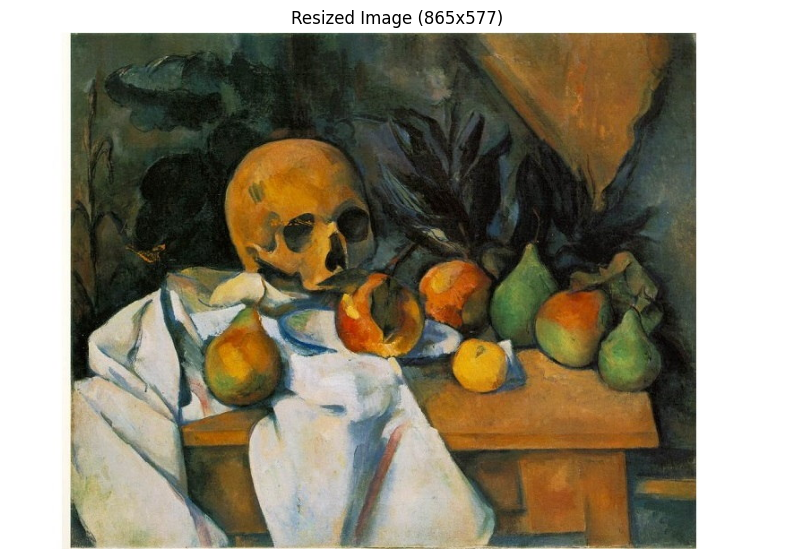

✅ Image set as 'sample_img' for pipeline processing


In [5]:
# @title Load and Resize Image (Max 1024px preserving aspect ratio)
"""
Load an image and resize it to have maximum dimension of 1024 pixels
while preserving the original aspect ratio
"""

import cv2
import numpy as np

def load_and_resize_image(image_path, max_dimension=1024):
   """
   Load image and resize to max dimension while preserving aspect ratio
   
   Args:
       image_path: Path to the image file
       max_dimension: Maximum dimension (width or height) in pixels
   
   Returns:
       Resized image in BGR format
   """
   # Read image
   img = cv2.imread(image_path)
   if img is None:
       print(f"❌ Error: Could not load image from {image_path}")
       return None
   
   # Get original dimensions
   h, w = img.shape[:2]
   print(f"Original dimensions: {w}x{h}")
   
   # Calculate scaling factor
   scale = max_dimension / max(h, w)
   
   # Only resize if image is larger than max_dimension
   if scale < 1:
       new_w = int(w * scale)
       new_h = int(h * scale)
       
       # Resize image
       img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
       print(f"Resized to: {new_w}x{new_h} (scale: {scale:.2f})")
   else:
       img_resized = img
       print(f"No resize needed (image smaller than {max_dimension}px)")
   
   return img_resized

# Example usage
image_path = "../images/still_famous.jpg"  # Change this to your image path
max_dim = 1024  # Maximum dimension

# Load and resize
img_resized = load_and_resize_image(image_path, max_dim)

if img_resized is not None:
   print(f"✅ Image loaded and resized successfully")
   print(f"Final shape: {img_resized.shape}")
   
   # Optional: Display the image
   import matplotlib.pyplot as plt
   plt.figure(figsize=(10, 10))
   plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
   plt.title(f"Resized Image ({img_resized.shape[1]}x{img_resized.shape[0]})")
   plt.axis('off')
   plt.show()
   
   # Set as sample_img for pipeline use
   sample_img = img_resized
   print("✅ Image set as 'sample_img' for pipeline processing")

## Pipeline

RGB preprocessing: 60.3ms


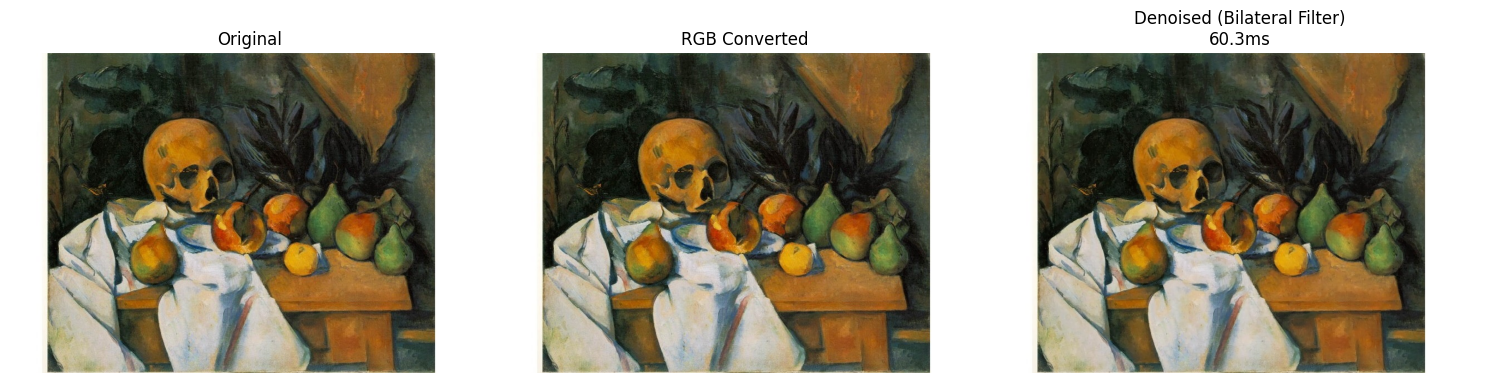

In [6]:
# @title RGB Preprocessing for PiDiNet
"""
RGB Preprocessing Method for Edge Detection
Using only RGB preprocessing approach for PiDiNet
"""

import cv2
import numpy as np
import torch
import time

class RGBPreprocessor:
    """RGB-only preprocessing for edge detection"""

    def __init__(self):
        pass

    def process(self, img_bgr):
        """Proper RGB preprocessing for models trained on RGB"""
        start_time = time.time()

        # Convert BGR to RGB
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Light denoising while preserving edges
        img_denoised = cv2.bilateralFilter(img_rgb, d=5, sigmaColor=10, sigmaSpace=10)

        # Convert to tensor
        tensor = torch.from_numpy(img_denoised).float() / 255.0
        tensor = tensor.permute(2, 0, 1)

        # Use proper normalization for edge detection
        # These values are more appropriate for edge detection than ImageNet stats
        mean = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
        std = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
        tensor = (tensor - mean) / std

        prep_time = time.time() - start_time

        return tensor, prep_time, {
            'rgb': img_rgb,
            'denoised': img_denoised,
            'channels': img_denoised
        }

# Initialize RGB preprocessor
preprocessor = RGBPreprocessor()

# Process sample image
if 'sample_img' in globals():
    tensor, time_taken, debug_info = preprocessor.process(sample_img)
    print(f"RGB preprocessing: {time_taken*1000:.1f}ms")

    # Visualize preprocessing output
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Original
    axes[0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original')
    axes[0].axis('off')

    # RGB converted
    axes[1].imshow(debug_info['rgb'])
    axes[1].set_title('RGB Converted')
    axes[1].axis('off')

    # Denoised
    axes[2].imshow(debug_info['denoised'])
    axes[2].set_title(f'Denoised (Bilateral Filter)\n{time_taken*1000:.1f}ms')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Please load sample_img first")

RGB preprocessing: 14.8ms
PiDiNet inference: 868.2ms
Total time: 883.1ms


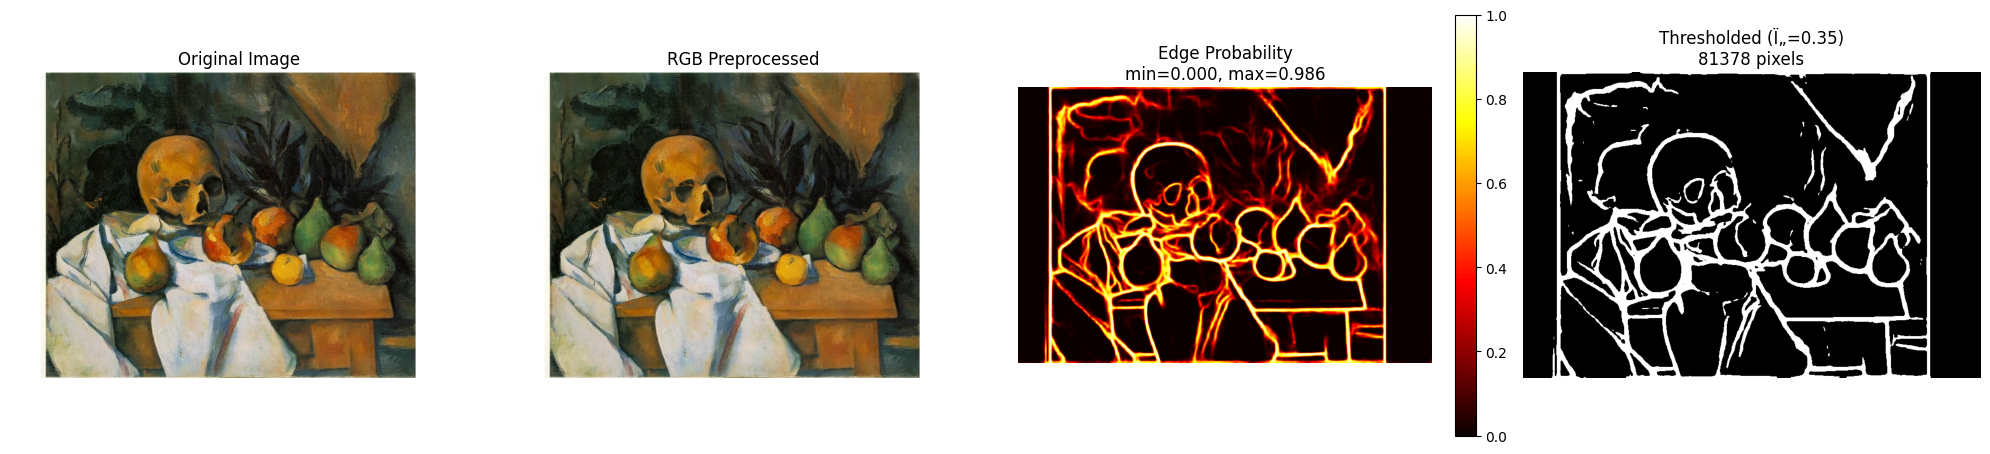

In [7]:
# @title PiDiNet Edge Detection with RGB Preprocessing
"""
Run PiDiNet inference using RGB preprocessing only
"""

def run_pidinet_inference(tensor, model, device):
    """Run PiDiNet inference and return edge probability map"""
    # Move tensor to device
    tensor = tensor.to(device).unsqueeze(0)

    # Run inference
    with torch.no_grad():
        output = model(tensor)
        if isinstance(output, (list, tuple)):
            output = output[-1]

    # Get edge probability map
    edges_prob = output.squeeze().cpu().numpy()

    # Convert to probability if needed (sigmoid)
    if edges_prob.min() < 0:
        edges_prob = 1 / (1 + np.exp(-edges_prob))

    return edges_prob

# Run inference with RGB preprocessing
if 'sample_img' in globals() and 'model' in globals():
    # Use RGB preprocessing
    tensor, prep_time, debug_info = preprocessor.process(sample_img)

    # Run inference
    start_time = time.time()
    edges_prob = run_pidinet_inference(tensor, model, device)
    inference_time = time.time() - start_time

    print(f"RGB preprocessing: {prep_time*1000:.1f}ms")
    print(f"PiDiNet inference: {inference_time*1000:.1f}ms")
    print(f"Total time: {(prep_time + inference_time)*1000:.1f}ms")

    # Visualize results
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    # Original
    axes[0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    # Preprocessed
    axes[1].imshow(debug_info['denoised'])
    axes[1].set_title('RGB Preprocessed')
    axes[1].axis('off')

    # Edge probability map
    im = axes[2].imshow(edges_prob, cmap='hot', vmin=0, vmax=1)
    axes[2].set_title(f'Edge Probability\nmin={edges_prob.min():.3f}, max={edges_prob.max():.3f}')
    axes[2].axis('off')
    plt.colorbar(im, ax=axes[2], fraction=0.046)

    # Thresholded (example with 0.35)
    threshold = 0.35
    binary = (edges_prob > threshold).astype(np.uint8)
    axes[3].imshow(binary * 255, cmap='gray')
    axes[3].set_title(f'Thresholded (Ï„={threshold})\n{np.sum(binary)} pixels')
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Please ensure sample_img and model are loaded")

In [8]:
# @title Fixed DT Ridge - Preserves Object Boundaries and Important Details
"""
Enhanced DT Ridge that uses SAM masks to protect important object boundaries
"""

import cv2
import numpy as np
from scipy.ndimage import distance_transform_edt, maximum_filter
from skimage.morphology import thin
import matplotlib.pyplot as plt

# DT Ridge Presets Dictionary
dt_ridge_presets = {
    'minimal': {
        'edge_threshold': 0.45,
        'base_neigh': 5,
        'lambda_val': 0.50,
        'max_neigh': 5,
        'r_win': 15,
        'min_dist': 1.5
    },
    'balanced': {
        'edge_threshold': 0.35,
        'base_neigh': 3,
        'lambda_val': 0.40,
        'max_neigh': 7,
        'r_win': 20,
        'min_dist': 1.0
    },
    'detailed': {
        'edge_threshold': 0.25,
        'base_neigh': 3,
        'lambda_val': 0.25,
        'max_neigh': 9,
        'r_win': 25,
        'min_dist': 0.0
    },
    'maximal': {
        'edge_threshold': 0.15,
        'base_neigh': 3,
        'lambda_val': 0.15,
        'max_neigh': 11,
        'r_win': 30,
        'min_dist': 0.0
    }
}

# Alternative version with more aggressive settings (if you want fewer strokes)
dt_ridge_presets_aggressive = {
    'minimal': {
        'edge_threshold': 0.50,  # Higher threshold
        'base_neigh': 7,
        'lambda_val': 0.60,  # More pruning
        'max_neigh': 5,
        'r_win': 10,
        'min_dist': 2.0  # Larger minimum
    },
    'balanced': {
        'edge_threshold': 0.40,
        'base_neigh': 5,
        'lambda_val': 0.45,
        'max_neigh': 7,
        'r_win': 15,
        'min_dist': 1.5
    },
    'detailed': {
        'edge_threshold': 0.30,
        'base_neigh': 3,
        'lambda_val': 0.35,
        'max_neigh': 9,
        'r_win': 20,
        'min_dist': 0.5
    },
    'maximal': {
        'edge_threshold': 0.20,
        'base_neigh': 3,
        'lambda_val': 0.20,
        'max_neigh': 11,
        'r_win': 25,
        'min_dist': 0.0
    }
}

# For the boundary-preserving version, these get modified by get_adaptive_dt_presets()
# which further reduces λ and min_dist based on the number of objects detectedParameter Explanations:


def dt_ridge_preserving(mask, object_masks=None, base_neigh=3, lambda_val=0.4, 
                        max_neigh=7, r_win=25, min_dist=0.0,
                        preserve_boundaries=True, boundary_weight=2.0):
    """
    Advanced DT ridge that preserves object boundaries
    
    Args:
        mask: Binary edge mask from PiDiNet
        object_masks: List of SAM object masks to preserve boundaries
        preserve_boundaries: If True, protects object boundaries from removal
        boundary_weight: How much to boost boundary edges (higher = stronger preservation)
    """
    
    # Original distance transform
    dist = distance_transform_edt(mask > 0)
    
    # Create importance map based on object boundaries
    if object_masks and preserve_boundaries:
        importance_map = create_importance_map(mask.shape, object_masks)
        
        # Boost distance values at important boundaries
        dist_boosted = dist.copy()
        dist_boosted[importance_map > 0] *= (1 + importance_map[importance_map > 0] * boundary_weight)
    else:
        dist_boosted = dist
        importance_map = np.zeros_like(mask, dtype=np.float32)
    
    # Find ridge pixels with boosted distances
    max_filt = maximum_filter(dist_boosted, size=base_neigh)
    ridge = (dist_boosted == max_filt) & (dist > 0)
    
    # Scale-adaptive dilation (less aggressive)
    if ridge.any() and max_neigh > base_neigh:
        dist_max = dist.max()
        if dist_max > 0:
            ridge_dilated = np.zeros_like(ridge, dtype=bool)
            
            # More conservative dilation
            bins = [(0, 0.3), (0.3, 0.6), (0.6, 1.0)]
            dilation_radii = [1, 2, 2]  # Reduced dilation
            
            for (low, high), radius in zip(bins, dilation_radii):
                dist_low = low * dist_max
                dist_high = high * dist_max
                bin_mask = ridge & (dist > dist_low) & (dist <= dist_high)
                
                if bin_mask.any():
                    actual_radius = min(radius, (max_neigh - 1) // 2)
                    
                    if actual_radius > 0:
                        kernel = cv2.getStructuringElement(
                            cv2.MORPH_ELLIPSE,
                            (2*actual_radius+1, 2*actual_radius+1)
                        )
                        bin_dilated = cv2.dilate(bin_mask.astype(np.uint8), kernel) > 0
                    else:
                        bin_dilated = bin_mask
                    
                    ridge_dilated |= bin_dilated
            
            ridge = ridge_dilated
    
    # MODIFIED Lambda-medial pruning - less aggressive near boundaries
    if lambda_val > 0:
        max_r = maximum_filter(dist, size=r_win)
        
        # Adaptive lambda based on importance
        adaptive_lambda = np.ones_like(mask, dtype=np.float32) * lambda_val
        
        # Reduce lambda (less pruning) near important boundaries
        if preserve_boundaries and importance_map.max() > 0:
            adaptive_lambda[importance_map > 0.5] *= 0.5  # Half lambda at boundaries
            adaptive_lambda[importance_map > 0.8] *= 0.3  # Even less at strong boundaries
        
        # Apply adaptive pruning
        ridge = ridge & (dist > adaptive_lambda * max_r)
    
    # Apply minimum distance threshold (but not at boundaries)
    if min_dist > 0:
        if preserve_boundaries:
            # Don't apply min_dist at important boundaries
            min_dist_mask = (dist > min_dist) | (importance_map > 0.7)
            ridge = ridge & min_dist_mask
        else:
            ridge = ridge & (dist > min_dist)
    
    # Add back critical boundary pixels that might have been removed
    if preserve_boundaries and object_masks:
        critical_boundaries = extract_critical_boundaries(mask, object_masks)
        ridge = ridge | critical_boundaries
    
    # Final thinning
    ridge_final = thin(ridge)
    
    # Count strokes
    num_labels, labels = cv2.connectedComponents(ridge_final.astype(np.uint8), connectivity=8)
    num_strokes = num_labels - 1
    num_pixels = np.sum(ridge_final > 0)
    
    return {
        'dist_map': dist,
        'ridge_raw': ridge,
        'ridge_final': ridge_final,
        'num_strokes': num_strokes,
        'num_pixels': num_pixels,
        'importance_map': importance_map
    }

def create_importance_map(shape, object_masks):
    """
    Create an importance map based on object boundaries
    Higher values = more important to preserve
    """
    h, w = shape
    importance = np.zeros((h, w), dtype=np.float32)
    
    for mask_data in object_masks[:50]:  # Process top 50 objects
        if isinstance(mask_data, dict):
            mask = mask_data.get('mask', mask_data.get('segmentation'))
        else:
            mask = mask_data
        
        if mask is None:
            continue
            
        mask = np.asarray(mask, dtype=bool)
        
        # Find boundaries of this object
        eroded = cv2.erode(mask.astype(np.uint8), np.ones((3,3), np.uint8), iterations=1)
        boundary = mask.astype(np.uint8) - eroded
        
        # Add to importance map with weight based on object size
        area = mask.sum()
        weight = min(1.0, np.sqrt(area / (h * w)) * 2)  # Larger objects = more important
        
        importance[boundary > 0] = np.maximum(importance[boundary > 0], weight)
    
    # Smooth the importance map slightly
    importance = cv2.GaussianBlur(importance, (5, 5), 1.0)
    
    return importance

def extract_critical_boundaries(edge_mask, object_masks):
    """
    Extract critical boundary pixels that must be preserved
    """
    h, w = edge_mask.shape
    critical = np.zeros((h, w), dtype=bool)
    
    for mask_data in object_masks[:30]:  # Top objects
        if isinstance(mask_data, dict):
            mask = mask_data.get('mask', mask_data.get('segmentation'))
        else:
            mask = mask_data
            
        if mask is None:
            continue
            
        mask = np.asarray(mask, dtype=bool)
        
        # Get boundary
        kernel = np.ones((3,3), np.uint8)
        dilated = cv2.dilate(mask.astype(np.uint8), kernel, iterations=1)
        boundary = dilated - mask.astype(np.uint8)
        
        # Find edge pixels on this boundary - ensure boolean type
        boundary_edges = edge_mask & boundary.astype(bool)
        
        # Add connected components that form the object outline
        if boundary_edges.any():
            # Keep edge pixels that are on object boundaries
            # Fix: Ensure boundary_edges is boolean
            critical = critical | boundary_edges.astype(bool)
    
    return critical

def get_adaptive_dt_presets(preset_name, num_objects):
    """
    Get adaptive DT Ridge parameters based on content
    Less aggressive for images with many objects
    """
    base_presets = {
        'minimal': {
            'edge_threshold': 0.45,
            'base_neigh': 5,
            'lambda_val': 0.50,  # Less aggressive pruning
            'max_neigh': 5,
            'r_win': 15,
            'min_dist': 1.5
        },
        'balanced': {
            'edge_threshold': 0.35,
            'base_neigh': 3,
            'lambda_val': 0.35,  # Reduced from 0.40
            'max_neigh': 7,
            'r_win': 20,  # Smaller window
            'min_dist': 0.5  # Less aggressive
        },
        'detailed': {
            'edge_threshold': 0.25,
            'base_neigh': 3,
            'lambda_val': 0.25,  # Much less aggressive
            'max_neigh': 9,
            'r_win': 25,
            'min_dist': 0.0  # No minimum distance
        },
        'maximal': {
            'edge_threshold': 0.15,
            'base_neigh': 3,
            'lambda_val': 0.15,  # Very conservative
            'max_neigh': 11,
            'r_win': 30,
            'min_dist': 0.0
        }
    }
    
    preset = base_presets.get(preset_name, base_presets['balanced']).copy()
    
    # Adapt based on number of objects
    if num_objects > 50:
        # Many objects - be more conservative
        preset['lambda_val'] *= 0.7
        preset['min_dist'] *= 0.5
        preset['edge_threshold'] *= 0.9
    elif num_objects > 100:
        # Very complex image - preserve more
        preset['lambda_val'] *= 0.5
        preset['min_dist'] = 0
        preset['edge_threshold'] *= 0.8
    
    return preset

# Test function to demonstrate the improvement
def test_preserving_dt_ridge(sample_img, masks, edges_hybrid, dt_preset='balanced'):
    """
    Compare original vs preserving DT Ridge
    """
    print("🔧 Testing Boundary-Preserving DT Ridge")
    print("="*50)
    
    # Get adaptive parameters
    dt_params = get_adaptive_dt_presets(dt_preset, len(masks))
    
    # Threshold edges
    binary = (edges_hybrid > dt_params['edge_threshold']).astype(np.uint8) * 255
    
    # Original DT Ridge
    print("\n1. Original DT Ridge (may lose details)...")
    dt_original = dt_ridge_preserving(
        binary,
        base_neigh=dt_params['base_neigh'],
        lambda_val=dt_params['lambda_val'],
        max_neigh=dt_params['max_neigh'],
        r_win=dt_params['r_win'],
        min_dist=dt_params['min_dist']
    )
    
    # Preserving DT Ridge
    print("2. Boundary-Preserving DT Ridge...")
    dt_preserving = dt_ridge_preserving(
        binary,
        object_masks=masks,
        base_neigh=dt_params['base_neigh'],
        lambda_val=dt_params['lambda_val'],
        max_neigh=dt_params['max_neigh'],
        r_win=dt_params['r_win'],
        min_dist=dt_params['min_dist'],
        preserve_boundaries=True,
        boundary_weight=2.0
    )
    
    # Visualize comparison
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Row 1: Original approach
    axes[0, 0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title('Original Image')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(edges_hybrid, cmap='hot')
    axes[0, 1].set_title('Edge Detection')
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(dt_original['ridge_final'] * 255, cmap='gray')
    axes[0, 2].set_title(f'Original DT Ridge\n{dt_original["num_strokes"]} strokes, {dt_original["num_pixels"]} pixels')
    axes[0, 2].axis('off')
    
    # Row 2: Preserving approach
    axes[1, 0].imshow(dt_preserving['importance_map'], cmap='hot')
    axes[1, 0].set_title('Importance Map\n(Object boundaries)')
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(dt_preserving['ridge_final'] * 255, cmap='gray')
    axes[1, 1].set_title(f'Preserving DT Ridge\n{dt_preserving["num_strokes"]} strokes, {dt_preserving["num_pixels"]} pixels')
    axes[1, 1].axis('off')
    
    # Difference
    difference = dt_preserving['ridge_final'].astype(float) - dt_original['ridge_final'].astype(float)
    axes[1, 2].imshow(difference, cmap='RdBu_r', vmin=-1, vmax=1)
    axes[1, 2].set_title(f'Difference\n+{np.sum(difference > 0)} preserved pixels')
    axes[1, 2].axis('off')
    
    plt.suptitle(f'DT Ridge Comparison - {dt_preset} preset', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Statistics
    print("\n📊 Comparison Results:")
    print(f"   Original: {dt_original['num_strokes']} strokes, {dt_original['num_pixels']} pixels")
    print(f"   Preserving: {dt_preserving['num_strokes']} strokes, {dt_preserving['num_pixels']} pixels")
    print(f"   Pixels preserved: {dt_preserving['num_pixels'] - dt_original['num_pixels']}")
    print(f"   Preservation rate: {(dt_preserving['num_pixels'] / dt_original['num_pixels'] - 1) * 100:.1f}% more detail")
    
    return dt_preserving

## SAM

In [9]:
# @title Initialize SAM Model
"""
Initialize Segment Anything Model with automatic mask generation
"""

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
import torch

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load SAM model
sam_checkpoint = "sam_checkpoint/sam_vit_b.pth"
model_type = "vit_b"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)
sam.eval()

# Create automatic mask generator with optimized parameters for sketch preprocessing
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,  # Higher for more detailed segmentation
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Minimum area for valid masks
)

print("âœ… SAM model loaded and configured")
print(f"   Model: {model_type}")
print(f"   Device: {device}")

Using device: cuda


/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/segment_anything/build_sam.py:105: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(f

âœ… SAM model loaded and configured
   Model: vit_b
   Device: cuda


Generating masks...
âœ“ Analyzed 64 regions


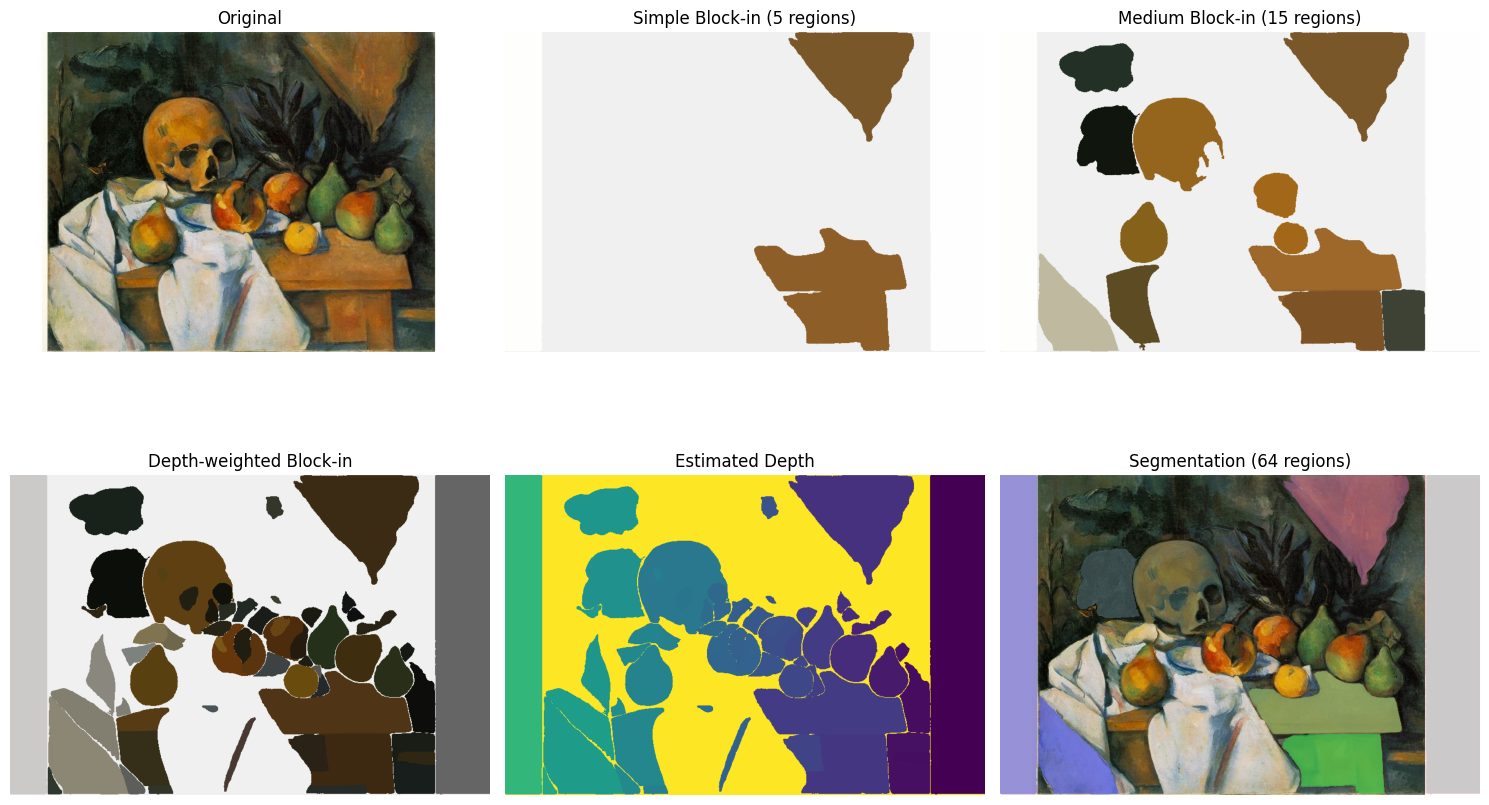

âœ… Segmentation complete: 64 regions found


In [10]:
# @title SAM-Enhanced Segmentation with Value Block-in
"""
Advanced segmentation that creates value-based regions for edge detection
"""

import cv2
import numpy as np
from typing import List, Dict, Tuple
import matplotlib.pyplot as plt

class SAMValueSegmenter:
    """Segment image and create value-based blocks for enhanced edge detection"""

    def __init__(self, mask_generator):
        self.mask_generator = mask_generator

    def segment_and_analyze(self, img_bgr):
        """Segment image and analyze values for each region"""
        # Convert to RGB for SAM
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Generate masks
        print("Generating masks...")
        masks = self.mask_generator.generate(img_rgb)

        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)

        # Analyze each mask
        analyzed_masks = []
        for i, mask_data in enumerate(masks):
            mask = mask_data['segmentation']

            # Extract region
            region = img_rgb[mask]

            if len(region) > 0:
                # Calculate statistics
                mean_color = region.mean(axis=0)
                std_color = region.std(axis=0)

                # Convert to grayscale for value analysis
                # Check if region has enough channels before converting
                if len(region.shape) == 2 or region.shape[1] == 1: # Check if grayscale or single channel
                     gray_region = region # It's already grayscale or single channel, no conversion needed
                else:
                    gray_region = cv2.cvtColor(region, cv2.COLOR_RGB2GRAY)

                mean_value = gray_region.mean()
                std_value = gray_region.std()

                # Classify by value
                if mean_value < 85:
                    value_class = "shadow"
                elif mean_value < 170:
                    value_class = "midtone"
                else:
                    value_class = "highlight"

                analyzed_masks.append({
                    'mask': mask,
                    'area': mask_data['area'],
                    'bbox': mask_data['bbox'],
                    'mean_color': mean_color,
                    'std_color': std_color,
                    'mean_value': mean_value,
                    'std_value': std_value,
                    'value_class': value_class,
                    'stability_score': mask_data.get('stability_score', 0)
                })

        print(f"âœ“ Analyzed {len(analyzed_masks)} regions")
        return analyzed_masks

    def create_value_blockin(self, img_bgr, masks, simplification='medium'):
        """Create value block-in version of image"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240  # Light background

        # Simplification levels
        simplify_params = {
            'minimal': {'num_masks': 5, 'blur': 0},
            'medium': {'num_masks': 15, 'blur': 3},
            'detailed': {'num_masks': 30, 'blur': 1}
        }

        params = simplify_params.get(simplification, simplify_params['medium'])

        # Process top N masks by area
        for mask_data in masks[:params['num_masks']]:
            mask = mask_data['mask']
            mean_color = mask_data['mean_color'].astype(np.uint8)

            # Apply to block-in
            blockin[mask] = cv2.cvtColor(
                np.array([[mean_color]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]

        # Optional smoothing
        if params['blur'] > 0:
            blockin = cv2.bilateralFilter(blockin, params['blur'], 75, 75)

        return blockin

    def create_depth_weighted_blockin(self, img_bgr, masks):
        """Create block-in with pseudo-depth weighting"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
        depth_map = np.ones((h, w), dtype=np.float32)

        # Estimate depth based on vertical position and size
        for i, mask_data in enumerate(masks):
            mask = mask_data['mask']

            # Simple depth heuristic: smaller + higher = farther
            y, x, h_box, w_box = mask_data['bbox']
            area_ratio = mask_data['area'] / (h * w)
            vertical_position = (y + h_box/2) / h

            # Depth score (0 = far, 1 = near)
            depth_score = (1 - vertical_position) * 0.6 + area_ratio * 0.4
            depth_map[mask] = depth_score

            # Adjust color based on depth
            mean_color = mask_data['mean_color']
            depth_adjusted = mean_color * (0.5 + 0.5 * depth_score)

            blockin[mask] = cv2.cvtColor(
                np.array([[depth_adjusted.astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]

        return blockin, depth_map

# Initialize segmenter
segmenter = SAMValueSegmenter(mask_generator)

# Test with sample image
if 'sample_img' in globals():
    analyzed_masks = segmenter.segment_and_analyze(sample_img)

    # Create different block-in versions
    blockin_simple = segmenter.create_value_blockin(sample_img, analyzed_masks, 'minimal')
    blockin_medium = segmenter.create_value_blockin(sample_img, analyzed_masks, 'medium')
    blockin_depth, depth_map = segmenter.create_depth_weighted_blockin(sample_img, analyzed_masks)

    # Visualize
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    axes[0, 0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title('Original')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(cv2.cvtColor(blockin_simple, cv2.COLOR_BGR2RGB))
    axes[0, 1].set_title(f'Simple Block-in ({5} regions)')
    axes[0, 1].axis('off')

    axes[0, 2].imshow(cv2.cvtColor(blockin_medium, cv2.COLOR_BGR2RGB))
    axes[0, 2].set_title(f'Medium Block-in ({15} regions)')
    axes[0, 2].axis('off')

    axes[1, 0].imshow(cv2.cvtColor(blockin_depth, cv2.COLOR_BGR2RGB))
    axes[1, 0].set_title('Depth-weighted Block-in')
    axes[1, 0].axis('off')

    axes[1, 1].imshow(depth_map, cmap='viridis')
    axes[1, 1].set_title('Estimated Depth')
    axes[1, 1].axis('off')

    # Show mask overlay
    mask_overlay = sample_img.copy()
    for i, mask_data in enumerate(analyzed_masks[:10]):
        color = np.random.randint(0, 255, 3).tolist()
        mask_overlay[mask_data['mask']] = mask_overlay[mask_data['mask']] * 0.5 + np.array(color) * 0.5

    axes[1, 2].imshow(cv2.cvtColor(mask_overlay.astype(np.uint8), cv2.COLOR_BGR2RGB))
    axes[1, 2].set_title(f'Segmentation ({len(analyzed_masks)} regions)')
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"âœ… Segmentation complete: {len(analyzed_masks)} regions found")

Processing with SAM-enhanced pipeline...


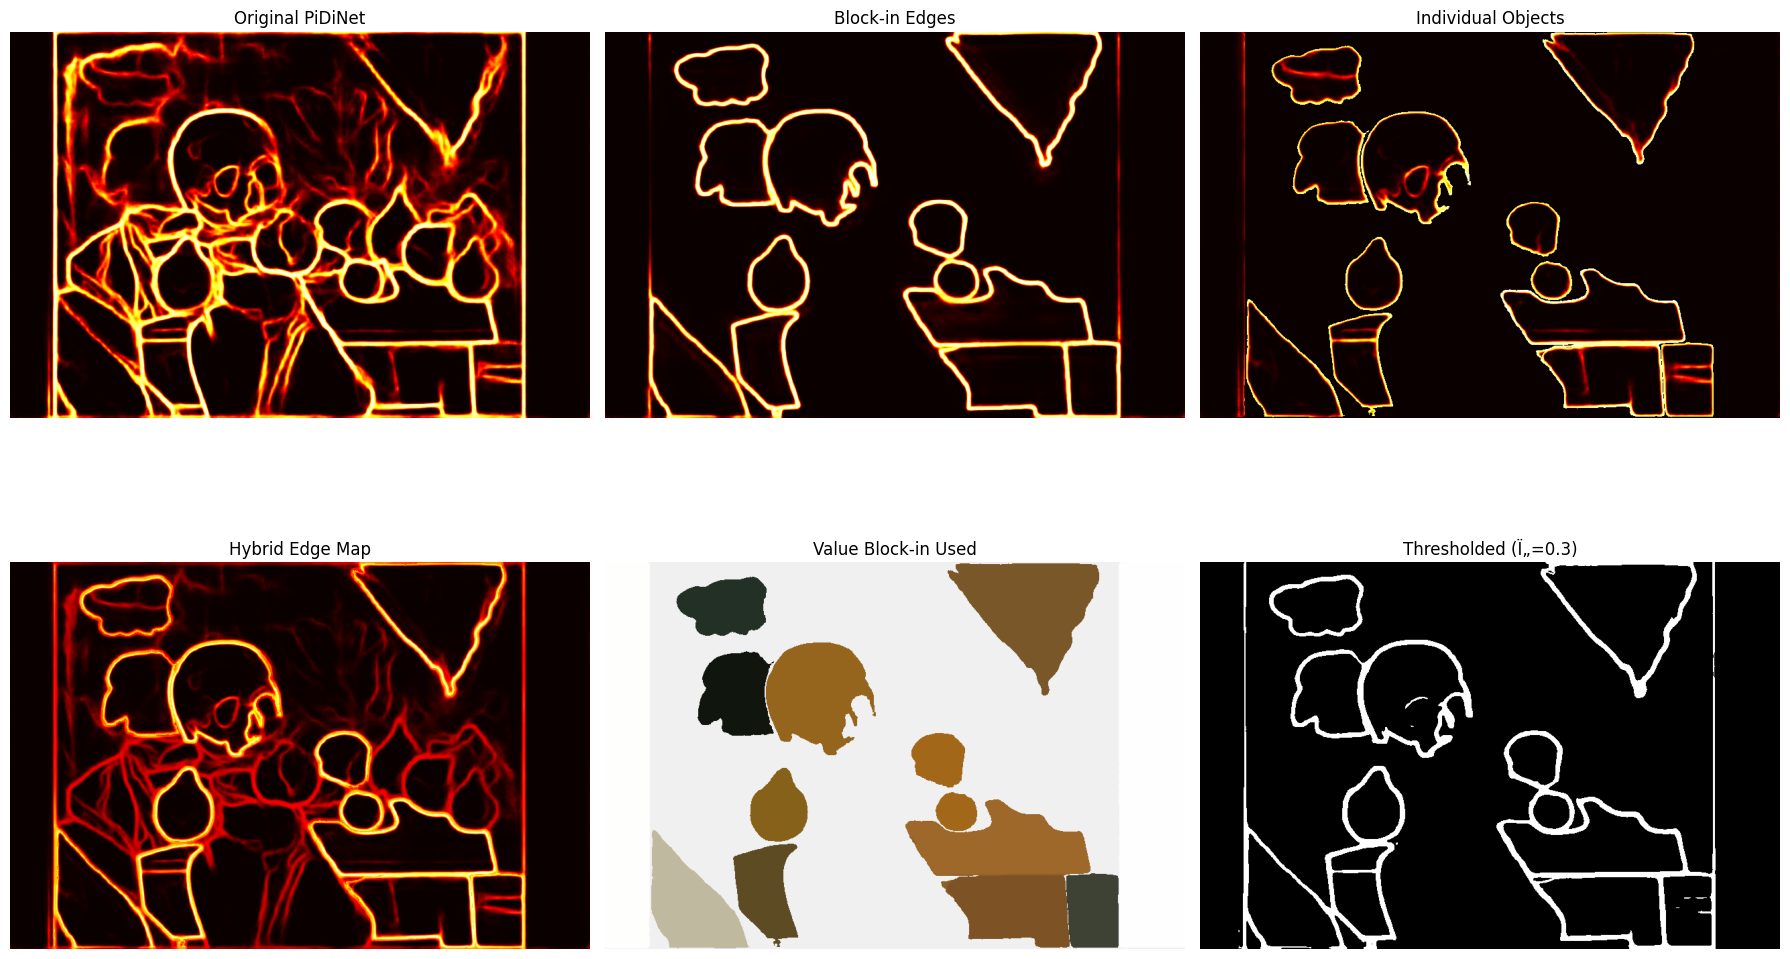

âœ… SAM-enhanced edge detection complete


In [11]:
# @title SAM-Enhanced PiDiNet Pipeline
"""
Apply PiDiNet to individual objects and value blocks for refined edge detection
"""

class SAMEnhancedEdgeDetector:
    """Combine SAM segmentation with PiDiNet for enhanced edge detection"""

    def __init__(self, model, preprocessor, device='cuda'):
        self.model = model
        self.preprocessor = preprocessor
        self.device = device

    def process_individual_objects(self, img_bgr, masks, top_n=20):
        """Process each object separately with PiDiNet"""
        h, w = img_bgr.shape[:2]
        combined_edges = np.zeros((h, w), dtype=np.float32)
        edge_maps = []

        for i, mask_data in enumerate(masks[:top_n]):
            mask = mask_data['mask']

            # Create isolated object image
            object_img = img_bgr.copy()
            object_img[~mask] = 255  # White background for non-object areas

            # Preprocess and run PiDiNet
            tensor, _, _ = self.preprocessor.process(object_img)
            edges_prob = run_pidinet_inference(tensor, self.model, self.device)

            # Mask the edges to object region only
            edges_masked = edges_prob * mask.astype(np.float32)

            # Weight by object importance (area and stability)
            area_weight = np.sqrt(mask_data['area'] / (h * w))
            stability_weight = mask_data.get('stability_score', 0.5)
            weight = (area_weight + stability_weight) / 2

            # Add to combined map
            combined_edges = np.maximum(combined_edges, edges_masked * weight)

            edge_maps.append({
                'edges': edges_masked,
                'mask': mask,
                'weight': weight,
                'value_class': mask_data['value_class']
            })

        return combined_edges, edge_maps

    def process_value_blockin(self, blockin_img):
        """Process value block-in version with PiDiNet"""
        tensor, _, _ = self.preprocessor.process(blockin_img)
        edges_prob = run_pidinet_inference(tensor, self.model, self.device)
        return edges_prob

    def create_hybrid_edges(self, img_bgr, masks, weights=None):
        """Create hybrid edge map combining multiple approaches"""
        if weights is None:
            weights = {
                'original': 0.3,
                'blockin': 0.3,
                'individual': 0.4
            }

        h, w = img_bgr.shape[:2]

        # 1. Original image edges
        tensor, _, _ = self.preprocessor.process(img_bgr)
        edges_original = run_pidinet_inference(tensor, self.model, self.device)

        # 2. Block-in edges (simplified forms)
        blockin = segmenter.create_value_blockin(img_bgr, masks, 'medium')
        edges_blockin = self.process_value_blockin(blockin)

        # 3. Individual object edges
        edges_individual, _ = self.process_individual_objects(img_bgr, masks, top_n=15)

        # Combine with weights
        hybrid = (edges_original * weights['original'] +
                 edges_blockin * weights['blockin'] +
                 edges_individual * weights['individual'])

        # Normalize
        hybrid = np.clip(hybrid, 0, 1)

        return {
            'hybrid': hybrid,
            'original': edges_original,
            'blockin': edges_blockin,
            'individual': edges_individual,
            'blockin_img': blockin
        }

# Initialize enhanced detector
enhanced_detector = SAMEnhancedEdgeDetector(model, preprocessor, device)

# Test with sample image
if 'sample_img' in globals() and 'analyzed_masks' in globals():
    print("Processing with SAM-enhanced pipeline...")

    # Generate hybrid edges
    edge_results = enhanced_detector.create_hybrid_edges(sample_img, analyzed_masks)

    # Visualize comparison
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # Row 1: Different edge types
    axes[0, 0].imshow(edge_results['original'], cmap='hot')
    axes[0, 0].set_title('Original PiDiNet')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(edge_results['blockin'], cmap='hot')
    axes[0, 1].set_title('Block-in Edges')
    axes[0, 1].axis('off')

    axes[0, 2].imshow(edge_results['individual'], cmap='hot')
    axes[0, 2].set_title('Individual Objects')
    axes[0, 2].axis('off')

    # Row 2: Hybrid and comparisons
    axes[1, 0].imshow(edge_results['hybrid'], cmap='hot')
    axes[1, 0].set_title('Hybrid Edge Map')
    axes[1, 0].axis('off')

    axes[1, 1].imshow(cv2.cvtColor(edge_results['blockin_img'], cv2.COLOR_BGR2RGB))
    axes[1, 1].set_title('Value Block-in Used')
    axes[1, 1].axis('off')

    # Thresholded hybrid
    threshold = 0.3
    binary = (edge_results['hybrid'] > threshold).astype(np.uint8) * 255
    axes[1, 2].imshow(binary, cmap='gray')
    axes[1, 2].set_title(f'Thresholded (Ï„={threshold})')
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

    print("âœ… SAM-enhanced edge detection complete")

ðŸš€ Starting SAM-Enhanced Pipeline
1. SAM Segmentation...
Generating masks...
âœ“ Analyzed 64 regions
   âœ“ Found 64 regions
2. Creating value block-ins...
   âœ“ Generated 3 block-in variants
3. Enhanced edge detection...
   âœ“ Computed hybrid edge map
4. Applying DT Ridge thinning...
   âœ“ Final sketch: 4535 pixels, 78 strokes


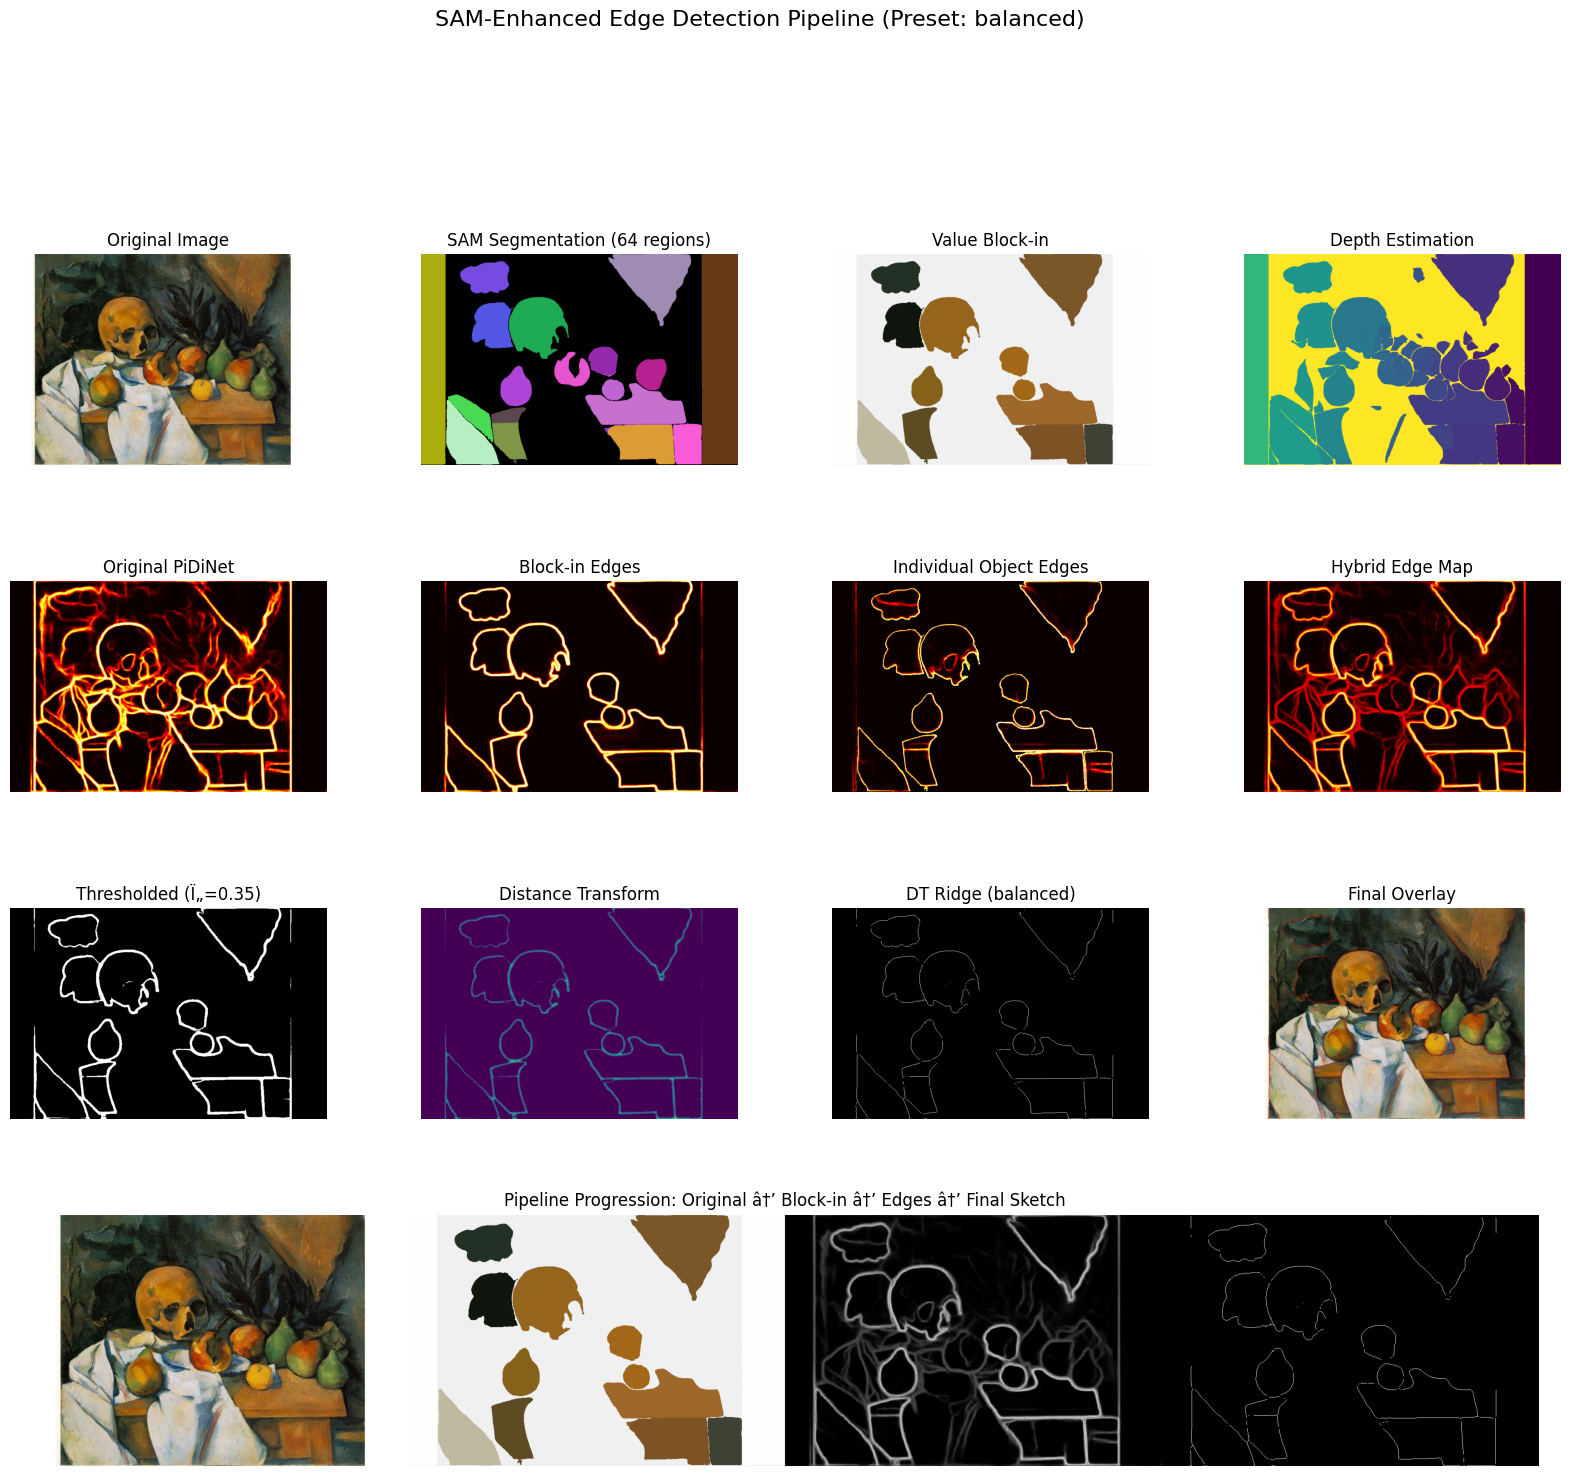


âœ… Pipeline complete!
   Final sketch: 4,535 pixels in 78 strokes


In [12]:
# @title Complete SAM-Enhanced Pipeline with DT Ridge
"""
Full pipeline: SAM segmentation â†’ Enhanced PiDiNet â†’ DT Ridge thinning
"""

def sam_enhanced_dt_pipeline(img_bgr, preset='balanced', visualize=True):
    """
    Complete enhanced pipeline with SAM integration

    Args:
        img_bgr: Input image in BGR format
        preset: DT Ridge preset ('minimal', 'balanced', 'detailed', 'maximal')
        visualize: Whether to show visualization

    Returns:
        Dictionary with all pipeline outputs
    """

    print("ðŸš€ Starting SAM-Enhanced Pipeline")
    print("=" * 50)

    # Step 1: SAM Segmentation
    print("1. SAM Segmentation...")
    analyzed_masks = segmenter.segment_and_analyze(img_bgr)
    print(f"   âœ“ Found {len(analyzed_masks)} regions")

    # Step 2: Create value block-ins
    print("2. Creating value block-ins...")
    blockin_simple = segmenter.create_value_blockin(img_bgr, analyzed_masks, 'minimal')
    blockin_medium = segmenter.create_value_blockin(img_bgr, analyzed_masks, 'medium')
    blockin_depth, depth_map = segmenter.create_depth_weighted_blockin(img_bgr, analyzed_masks)
    print("   âœ“ Generated 3 block-in variants")

    # Step 3: Enhanced edge detection
    print("3. Enhanced edge detection...")
    edge_results = enhanced_detector.create_hybrid_edges(img_bgr, analyzed_masks)
    print("   âœ“ Computed hybrid edge map")

    # Step 4: DT Ridge thinning
    print("4. Applying DT Ridge thinning...")
    dt_preset = dt_ridge_presets.get(preset, dt_ridge_presets['balanced'])

    # Apply threshold
    binary = (edge_results['hybrid'] > dt_preset['edge_threshold']).astype(np.uint8)
    binary_mask = binary * 255

    # Apply DT Ridge
    dt_result = dt_ridge_preserving(
        binary_mask,
        base_neigh=dt_preset['base_neigh'],
        lambda_val=dt_preset['lambda_val'],
        max_neigh=dt_preset['max_neigh'],
        r_win=dt_preset['r_win'],
        min_dist=dt_preset['min_dist']
    )
    print(f"   âœ“ Final sketch: {dt_result['num_pixels']} pixels, {dt_result['num_strokes']} strokes")

    # Prepare results
    results = {
        'masks': analyzed_masks,
        'blockin_simple': blockin_simple,
        'blockin_medium': blockin_medium,
        'blockin_depth': blockin_depth,
        'depth_map': depth_map,
        'edges_original': edge_results['original'],
        'edges_blockin': edge_results['blockin'],
        'edges_individual': edge_results['individual'],
        'edges_hybrid': edge_results['hybrid'],
        'dt_ridge': dt_result['ridge_final'],
        'dt_distance': dt_result['dist_map'],
        'stats': {
            'num_regions': len(analyzed_masks),
            'num_pixels': dt_result['num_pixels'],
            'num_strokes': dt_result['num_strokes']
        }
    }

    # Visualization
    if visualize:
        fig = plt.figure(figsize=(20, 16))

        # Create grid
        gs = fig.add_gridspec(4, 4, hspace=0.3, wspace=0.3)

        # Row 1: Input and segmentation
        ax1 = fig.add_subplot(gs[0, 0])
        ax1.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        ax1.set_title('Original Image')
        ax1.axis('off')

        ax2 = fig.add_subplot(gs[0, 1])
        mask_viz = np.zeros_like(img_bgr)
        for i, m in enumerate(analyzed_masks[:20]):
            color = np.random.randint(0, 255, 3)
            mask_viz[m['mask']] = color
        ax2.imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
        ax2.set_title(f'SAM Segmentation ({len(analyzed_masks)} regions)')
        ax2.axis('off')

        ax3 = fig.add_subplot(gs[0, 2])
        ax3.imshow(cv2.cvtColor(blockin_medium, cv2.COLOR_BGR2RGB))
        ax3.set_title('Value Block-in')
        ax3.axis('off')

        ax4 = fig.add_subplot(gs[0, 3])
        ax4.imshow(depth_map, cmap='viridis')
        ax4.set_title('Depth Estimation')
        ax4.axis('off')

        # Row 2: Edge detection variants
        ax5 = fig.add_subplot(gs[1, 0])
        ax5.imshow(edge_results['original'], cmap='hot')
        ax5.set_title('Original PiDiNet')
        ax5.axis('off')

        ax6 = fig.add_subplot(gs[1, 1])
        ax6.imshow(edge_results['blockin'], cmap='hot')
        ax6.set_title('Block-in Edges')
        ax6.axis('off')

        ax7 = fig.add_subplot(gs[1, 2])
        ax7.imshow(edge_results['individual'], cmap='hot')
        ax7.set_title('Individual Object Edges')
        ax7.axis('off')

        ax8 = fig.add_subplot(gs[1, 3])
        ax8.imshow(edge_results['hybrid'], cmap='hot')
        ax8.set_title('Hybrid Edge Map')
        ax8.axis('off')

        # Row 3: DT Ridge processing
        ax9 = fig.add_subplot(gs[2, 0])
        ax9.imshow(binary * 255, cmap='gray')
        ax9.set_title(f'Thresholded (Ï„={dt_preset["edge_threshold"]})')
        ax9.axis('off')

        ax10 = fig.add_subplot(gs[2, 1])
        ax10.imshow(dt_result['dist_map'], cmap='viridis')
        ax10.set_title('Distance Transform')
        ax10.axis('off')

        ax11 = fig.add_subplot(gs[2, 2])
        ax11.imshow(dt_result['ridge_final'] * 255, cmap='gray')
        ax11.set_title(f'DT Ridge ({preset})')
        ax11.axis('off')

        ax12 = fig.add_subplot(gs[2, 3])
        overlay = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()
        overlay[dt_result['ridge_final'] > 0] = [255, 0, 0]
        ax12.imshow(overlay)
        ax12.set_title('Final Overlay')
        ax12.axis('off')

        # Row 4: Comparison strip
        ax_full = fig.add_subplot(gs[3, :])

        # Create comparison strip
        strip_images = [
            cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB),
            cv2.cvtColor(blockin_medium, cv2.COLOR_BGR2RGB),
            np.stack([edge_results['hybrid']*255]*3, axis=-1).astype(np.uint8),
            np.stack([dt_result['ridge_final']*255]*3, axis=-1).astype(np.uint8)
        ]
        strip = np.hstack(strip_images)
        ax_full.imshow(strip)
        ax_full.set_title('Pipeline Progression: Original â†’ Block-in â†’ Edges â†’ Final Sketch')
        ax_full.axis('off')

        plt.suptitle(f'SAM-Enhanced Edge Detection Pipeline (Preset: {preset})', fontsize=16, y=1.02)
        plt.show()

    print("\nâœ… Pipeline complete!")
    print(f"   Final sketch: {results['stats']['num_pixels']:,} pixels in {results['stats']['num_strokes']} strokes")

    return results

# Run the complete pipeline
if 'sample_img' in globals():
    results = sam_enhanced_dt_pipeline(sample_img, preset='balanced', visualize=True)

## SAM 2.1

In [13]:
import torch
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator


checkpoint = "./checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"

# Build SAM 2.1 model
sam2 = build_sam2(model_cfg, checkpoint, device=device, apply_postprocessing=False)
sam2.eval()

# Create automatic mask generator with optimized parameters for sketch preprocessing
mask_generator = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=32,  # Higher for more detailed segmentation
    points_per_batch=64,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,
    stability_score_offset=1.0,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Minimum area for valid masks
    output_mode="binary_mask",
)

print("âœ… SAM 2.1 model loaded and configured")

âœ… SAM 2.1 model loaded and configured


Generating masks with SAM 2.1...


/teamspace/studios/this_studio/sam2/sam2/sam2_image_predictor.py:431: UserWarning: /teamspace/studios/this_studio/sam2/sam2/_C.so: undefined symbol: _ZN3c106detail23torchInternalAssertFailEPKcS2_jS2_RKNSt7__cxx1112basic_stringIcSt11char_traitsIcESaIcEEE

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  masks = self._transforms.postprocess_masks(


âœ” Analyzed 22 regions with SAM 2.1


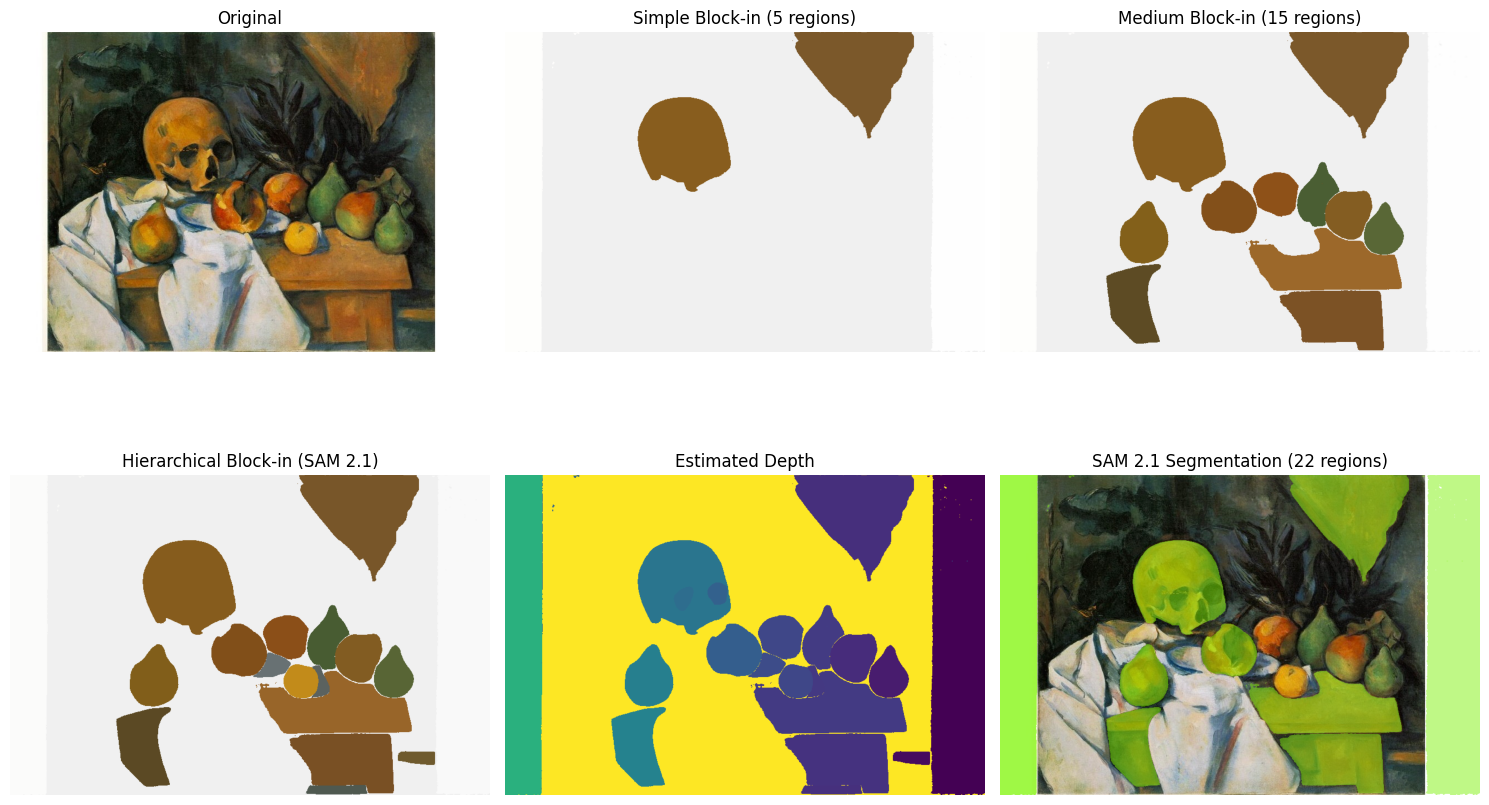

âœ… SAM 2.1 segmentation complete: 22 regions found
   Average stability score: 0.952
   Average IoU: 0.940


In [14]:
# @title SAM 2.1-Enhanced Segmentation with Value Block-in
"""
Advanced segmentation using SAM 2.1 that creates value-based regions for edge detection
"""

import cv2
import numpy as np
from typing import List, Dict, Tuple
import matplotlib.pyplot as plt
import torch

class SAM21ValueSegmenter:
    """Segment image using SAM 2.1 and create value-based blocks for enhanced edge detection"""

    def __init__(self, mask_generator):
        self.mask_generator = mask_generator

    def segment_and_analyze(self, img_bgr):
        """Segment image and analyze values for each region"""
        # Convert to RGB for SAM
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Generate masks with SAM 2.1
        print("Generating masks with SAM 2.1...")
        with torch.no_grad():
            masks = self.mask_generator.generate(img_rgb)

        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)

        # Analyze each mask
        analyzed_masks = []
        for i, mask_data in enumerate(masks):
            mask = mask_data['segmentation']

            # Extract region
            region_pixels = img_rgb[mask]

            if len(region_pixels) > 0:
                # Calculate statistics
                mean_color = region_pixels.mean(axis=0)
                std_color = region_pixels.std(axis=0)

                # Convert to grayscale for value analysis
                gray_pixels = np.dot(region_pixels[...,:3], [0.2989, 0.5870, 0.1140])
                mean_value = gray_pixels.mean()
                std_value = gray_pixels.std()

                # Classify by value
                if mean_value < 85:
                    value_class = "shadow"
                elif mean_value < 170:
                    value_class = "midtone"
                else:
                    value_class = "highlight"

                # SAM 2.1 specific metrics
                stability_score = mask_data.get('stability_score', 0)
                predicted_iou = mask_data.get('predicted_iou', 0)

                analyzed_masks.append({
                    'mask': mask,
                    'area': mask_data['area'],
                    'bbox': mask_data['bbox'],
                    'mean_color': mean_color,
                    'std_color': std_color,
                    'mean_value': mean_value,
                    'std_value': std_value,
                    'value_class': value_class,
                    'stability_score': stability_score,
                    'predicted_iou': predicted_iou,
                    'point_coords': mask_data.get('point_coords', [])
                })

        print(f"âœ” Analyzed {len(analyzed_masks)} regions with SAM 2.1")
        return analyzed_masks

    def create_value_blockin(self, img_bgr, masks, simplification='medium'):
        """Create value block-in version of image"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240  # Light background

        # Simplification levels
        simplify_params = {
            'minimal': {'num_masks': 5, 'blur': 0, 'iou_threshold': 0.9},
            'medium': {'num_masks': 15, 'blur': 3, 'iou_threshold': 0.85},
            'detailed': {'num_masks': 30, 'blur': 1, 'iou_threshold': 0.8}
        }

        params = simplify_params.get(simplification, simplify_params['medium'])

        # Filter by IoU threshold if available
        filtered_masks = [m for m in masks if m.get('predicted_iou', 1.0) >= params['iou_threshold']]

        # Process top N masks by area
        for mask_data in filtered_masks[:params['num_masks']]:
            mask = mask_data['mask']
            mean_color = mask_data['mean_color'].astype(np.uint8)

            # Apply to block-in
            blockin[mask] = cv2.cvtColor(
                np.array([[mean_color]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]

        # Optional smoothing
        if params['blur'] > 0:
            blockin = cv2.bilateralFilter(blockin, params['blur'], 75, 75)

        return blockin

    def create_hierarchical_blockin(self, img_bgr, masks):
        """Create hierarchical block-in using SAM 2.1's multi-scale information"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
        hierarchy_map = np.zeros((h, w), dtype=np.float32)

        # Group masks by stability score (SAM 2.1 feature)
        stable_masks = [m for m in masks if m['stability_score'] > 0.95]
        medium_masks = [m for m in masks if 0.85 <= m['stability_score'] <= 0.95]
        unstable_masks = [m for m in masks if m['stability_score'] < 0.85]

        # Apply in hierarchical order
        for level, mask_group in enumerate([unstable_masks, medium_masks, stable_masks]):
            for mask_data in mask_group[:10]:  # Limit per level
                mask = mask_data['mask']
                mean_color = mask_data['mean_color']

                # Adjust intensity based on stability
                stability_factor = 0.6 + 0.4 * mask_data['stability_score']
                adjusted_color = mean_color * stability_factor

                blockin[mask] = cv2.cvtColor(
                    np.array([[adjusted_color.astype(np.uint8)]], dtype=np.uint8),
                    cv2.COLOR_RGB2BGR
                )[0, 0]

                hierarchy_map[mask] = level + 1

        return blockin, hierarchy_map

    def create_depth_weighted_blockin(self, img_bgr, masks):
        """Create block-in with pseudo-depth weighting using SAM 2.1 features"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
        depth_map = np.ones((h, w), dtype=np.float32)

        for i, mask_data in enumerate(masks):
            mask = mask_data['mask']

            # Enhanced depth heuristic using SAM 2.1 metrics
            y, x, h_box, w_box = mask_data['bbox']
            area_ratio = mask_data['area'] / (h * w)
            vertical_position = (y + h_box/2) / h

            # Use stability and IoU as additional depth cues
            stability = mask_data.get('stability_score', 0.5)
            iou = mask_data.get('predicted_iou', 0.5)

            # Depth score (0 = far, 1 = near)
            # Stable, high-IoU regions are likely foreground
            depth_score = (
                (1 - vertical_position) * 0.4 +
                area_ratio * 0.3 +
                stability * 0.15 +
                iou * 0.15
            )
            depth_map[mask] = depth_score

            # Adjust color based on depth
            mean_color = mask_data['mean_color']
            depth_adjusted = mean_color * (0.5 + 0.5 * depth_score)

            blockin[mask] = cv2.cvtColor(
                np.array([[depth_adjusted.astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]

        return blockin, depth_map

# Initialize SAM 2.1 segmenter
segmenter = SAM21ValueSegmenter(mask_generator)

# Test with sample image
if 'sample_img' in globals():
    analyzed_masks = segmenter.segment_and_analyze(sample_img)

    # Create different block-in versions
    blockin_simple = segmenter.create_value_blockin(sample_img, analyzed_masks, 'minimal')
    blockin_medium = segmenter.create_value_blockin(sample_img, analyzed_masks, 'medium')
    blockin_hier, hier_map = segmenter.create_hierarchical_blockin(sample_img, analyzed_masks)
    blockin_depth, depth_map = segmenter.create_depth_weighted_blockin(sample_img, analyzed_masks)

    # Visualize
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    axes[0, 0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title('Original')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(cv2.cvtColor(blockin_simple, cv2.COLOR_BGR2RGB))
    axes[0, 1].set_title(f'Simple Block-in (5 regions)')
    axes[0, 1].axis('off')

    axes[0, 2].imshow(cv2.cvtColor(blockin_medium, cv2.COLOR_BGR2RGB))
    axes[0, 2].set_title(f'Medium Block-in (15 regions)')
    axes[0, 2].axis('off')

    axes[1, 0].imshow(cv2.cvtColor(blockin_hier, cv2.COLOR_BGR2RGB))
    axes[1, 0].set_title('Hierarchical Block-in (SAM 2.1)')
    axes[1, 0].axis('off')

    axes[1, 1].imshow(depth_map, cmap='viridis')
    axes[1, 1].set_title('Estimated Depth')
    axes[1, 1].axis('off')

    # Show mask overlay with SAM 2.1 quality metrics
    mask_overlay = sample_img.copy()
    for i, mask_data in enumerate(analyzed_masks[:10]):
        # Color by stability score
        stability = mask_data['stability_score']
        color = np.array([255 * (1-stability), 255 * stability, 128])
        mask_overlay[mask_data['mask']] = mask_overlay[mask_data['mask']] * 0.5 + color * 0.5

    axes[1, 2].imshow(cv2.cvtColor(mask_overlay.astype(np.uint8), cv2.COLOR_BGR2RGB))
    axes[1, 2].set_title(f'SAM 2.1 Segmentation ({len(analyzed_masks)} regions)')
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"âœ… SAM 2.1 segmentation complete: {len(analyzed_masks)} regions found")
    print(f"   Average stability score: {np.mean([m['stability_score'] for m in analyzed_masks]):.3f}")
    print(f"   Average IoU: {np.mean([m['predicted_iou'] for m in analyzed_masks]):.3f}")

ðŸš€ Starting SAM 2.1-Enhanced Pipeline
1. SAM 2.1 Segmentation...
Generating masks with SAM 2.1...
âœ” Analyzed 22 regions with SAM 2.1
   âœ” Found 22 regions
   âœ” Avg stability: 0.952, Avg IoU: 0.940
2. Creating SAM 2.1 value block-ins...
   âœ” Generated hierarchical block-in using stability scores
   âœ” Generated 4 block-in variants with SAM 2.1 features
3. Enhanced edge detection...
   âœ” Computed hybrid edge map with SAM 2.1 enhancements
4. Applying DT Ridge thinning...
   âœ” Final sketch: 3975 pixels, 43 strokes


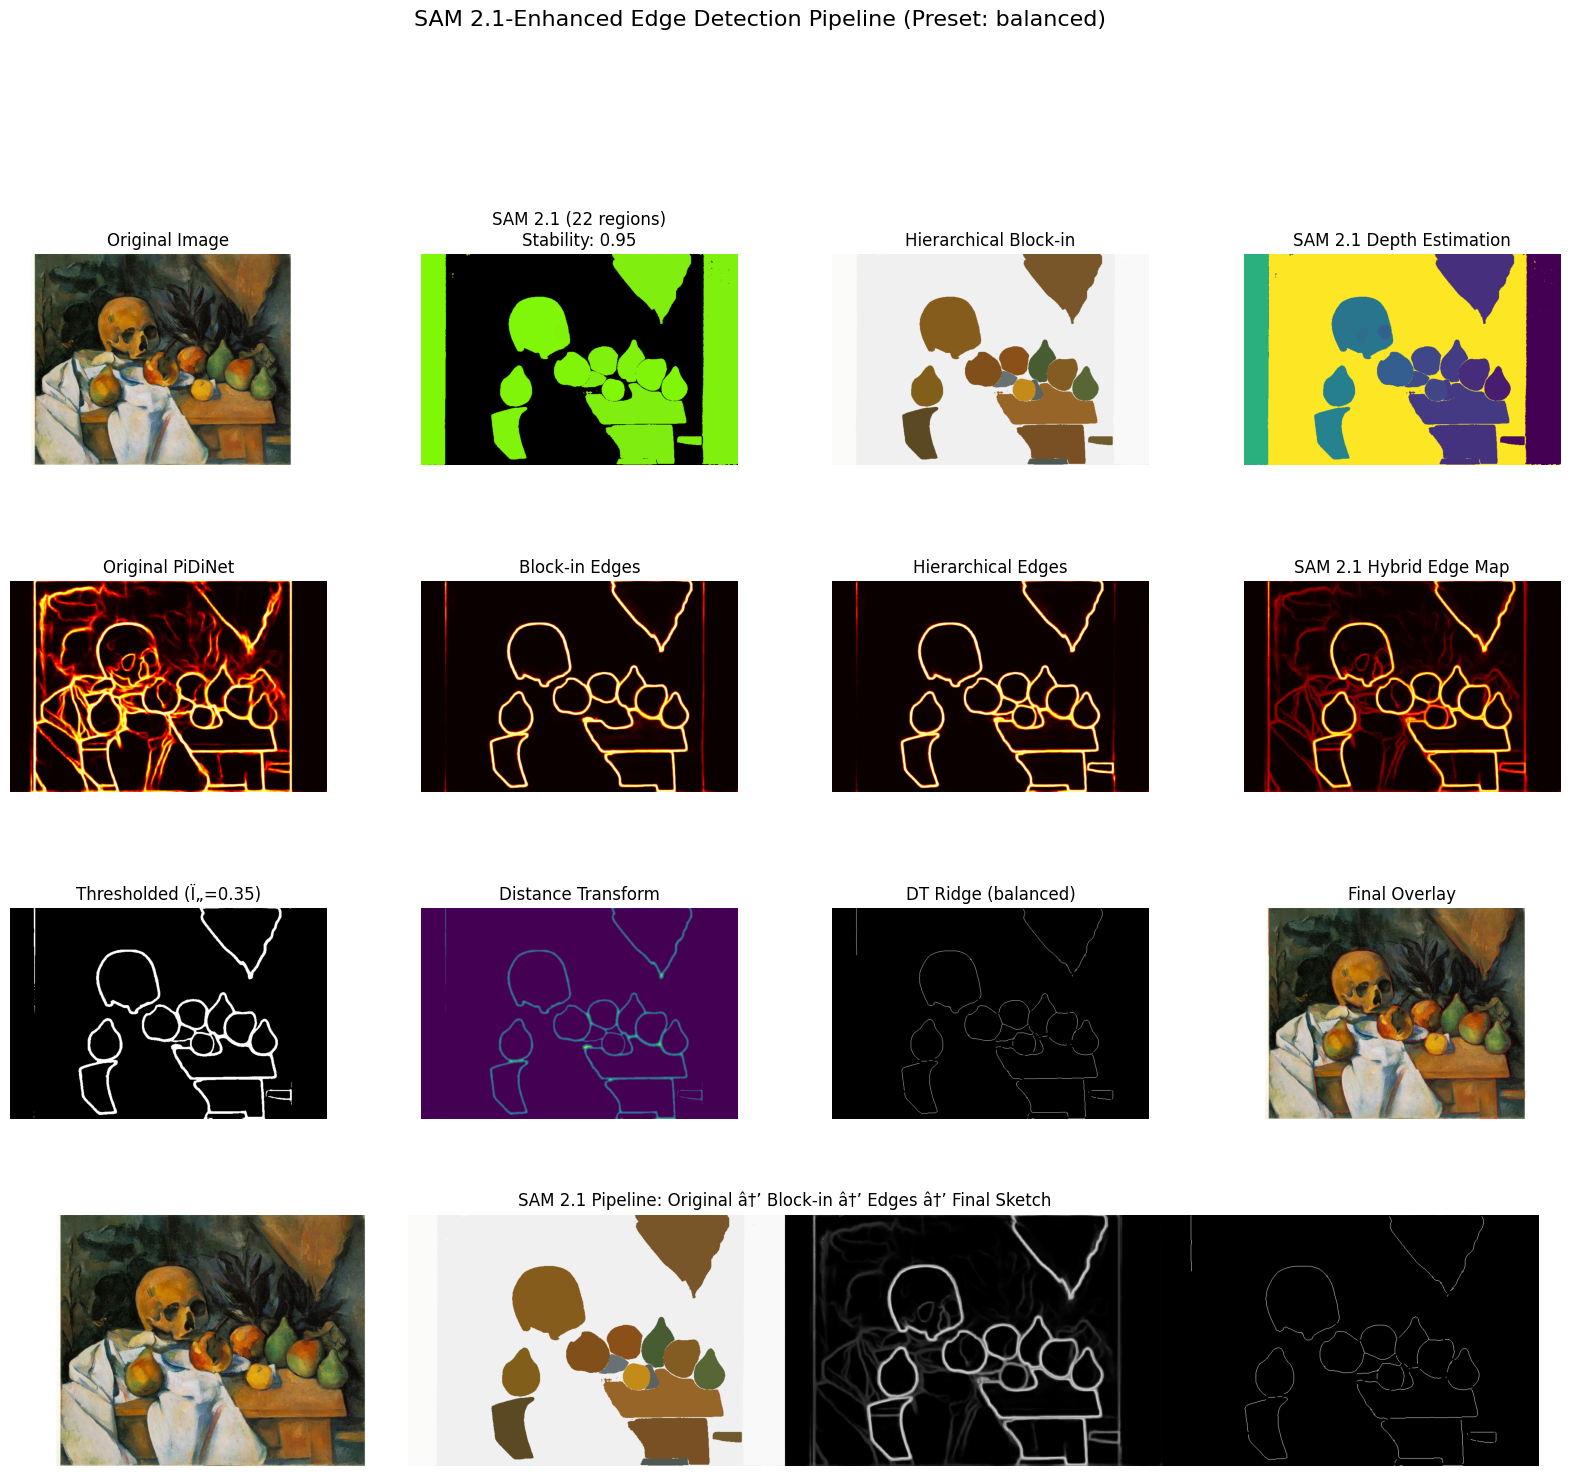


âœ… SAM 2.1 Pipeline complete!
   Final sketch: 3,975 pixels in 43 strokes
   SAM 2.1 quality: Stability=0.952, IoU=0.940


In [15]:
# @title Complete SAM 2.1-Enhanced Pipeline with DT Ridge
"""
Full pipeline: SAM 2.1 segmentation â†’ Enhanced PiDiNet â†’ DT Ridge thinning
"""

def sam21_enhanced_dt_pipeline(img_bgr, preset='balanced', visualize=True, use_hierarchical=True):
    """
    Complete enhanced pipeline with SAM 2.1 integration

    Args:
        img_bgr: Input image in BGR format
        preset: DT Ridge preset ('minimal', 'balanced', 'detailed', 'maximal')
        visualize: Whether to show visualization
        use_hierarchical: Use SAM 2.1's hierarchical features

    Returns:
        Dictionary with all pipeline outputs
    """

    print("ðŸš€ Starting SAM 2.1-Enhanced Pipeline")
    print("=" * 50)

    # Step 1: SAM 2.1 Segmentation
    print("1. SAM 2.1 Segmentation...")
    analyzed_masks = segmenter.segment_and_analyze(img_bgr)
    print(f"   âœ” Found {len(analyzed_masks)} regions")

    # Calculate quality metrics
    avg_stability = np.mean([m['stability_score'] for m in analyzed_masks])
    avg_iou = np.mean([m['predicted_iou'] for m in analyzed_masks])
    print(f"   âœ” Avg stability: {avg_stability:.3f}, Avg IoU: {avg_iou:.3f}")

    # Step 2: Create value block-ins with SAM 2.1 enhancements
    print("2. Creating SAM 2.1 value block-ins...")
    blockin_simple = segmenter.create_value_blockin(img_bgr, analyzed_masks, 'minimal')
    blockin_medium = segmenter.create_value_blockin(img_bgr, analyzed_masks, 'medium')

    if use_hierarchical:
        blockin_hier, hier_map = segmenter.create_hierarchical_blockin(img_bgr, analyzed_masks)
        print("   âœ” Generated hierarchical block-in using stability scores")

    blockin_depth, depth_map = segmenter.create_depth_weighted_blockin(img_bgr, analyzed_masks)
    print("   âœ” Generated 4 block-in variants with SAM 2.1 features")

    # Step 3: Enhanced edge detection
    print("3. Enhanced edge detection...")

    # Modified to use hierarchical blockin if available
    if use_hierarchical:
        # Use hierarchical blockin for better edge quality
        tensor_hier, _, _ = preprocessor.process(blockin_hier)
        edges_hier = run_pidinet_inference(tensor_hier, model, device)

        # Combine with original approach
        edge_results = enhanced_detector.create_hybrid_edges(img_bgr, analyzed_masks)

        # Add hierarchical edges to the mix
        edge_results['hierarchical'] = edges_hier
        edge_results['hybrid'] = (
            edge_results['hybrid'] * 0.7 +
            edges_hier * 0.3
        )
        edge_results['hybrid'] = np.clip(edge_results['hybrid'], 0, 1)
    else:
        edge_results = enhanced_detector.create_hybrid_edges(img_bgr, analyzed_masks)

    print("   âœ” Computed hybrid edge map with SAM 2.1 enhancements")

    # Step 4: DT Ridge thinning
    print("4. Applying DT Ridge thinning...")
    dt_preset = dt_ridge_presets.get(preset, dt_ridge_presets['balanced'])

    # Apply threshold
    binary = (edge_results['hybrid'] > dt_preset['edge_threshold']).astype(np.uint8)
    binary_mask = binary * 255

    # Apply DT Ridge
    dt_result = dt_ridge_preserving(
        binary_mask,
        base_neigh=dt_preset['base_neigh'],
        lambda_val=dt_preset['lambda_val'],
        max_neigh=dt_preset['max_neigh'],
        r_win=dt_preset['r_win'],
        min_dist=dt_preset['min_dist']
    )
    print(f"   âœ” Final sketch: {dt_result['num_pixels']} pixels, {dt_result['num_strokes']} strokes")

    # Prepare results
    results = {
        'masks': analyzed_masks,
        'blockin_simple': blockin_simple,
        'blockin_medium': blockin_medium,
        'blockin_depth': blockin_depth,
        'depth_map': depth_map,
        'edges_original': edge_results['original'],
        'edges_blockin': edge_results['blockin'],
        'edges_individual': edge_results['individual'],
        'edges_hybrid': edge_results['hybrid'],
        'dt_ridge': dt_result['ridge_final'],
        'dt_distance': dt_result['dist_map'],
        'sam21_metrics': {
            'avg_stability': avg_stability,
            'avg_iou': avg_iou,
            'num_stable_masks': len([m for m in analyzed_masks if m['stability_score'] > 0.95])
        },
        'stats': {
            'num_regions': len(analyzed_masks),
            'num_pixels': dt_result['num_pixels'],
            'num_strokes': dt_result['num_strokes']
        }
    }

    if use_hierarchical:
        results['blockin_hierarchical'] = blockin_hier
        results['hierarchy_map'] = hier_map
        results['edges_hierarchical'] = edges_hier

    # Visualization
    if visualize:
        fig = plt.figure(figsize=(20, 16))

        # Create grid
        gs = fig.add_gridspec(4, 4, hspace=0.3, wspace=0.3)

        # Row 1: Input and SAM 2.1 segmentation
        ax1 = fig.add_subplot(gs[0, 0])
        ax1.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        ax1.set_title('Original Image')
        ax1.axis('off')

        ax2 = fig.add_subplot(gs[0, 1])
        mask_viz = np.zeros_like(img_bgr)
        for i, m in enumerate(analyzed_masks[:20]):
            # Color by stability score
            stability = m['stability_score']
            color = np.array([255 * (1-stability), 255 * stability, 128])
            mask_viz[m['mask']] = color
        ax2.imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
        ax2.set_title(f'SAM 2.1 ({len(analyzed_masks)} regions)\nStability: {avg_stability:.2f}')
        ax2.axis('off')

        ax3 = fig.add_subplot(gs[0, 2])
        if use_hierarchical:
            ax3.imshow(cv2.cvtColor(blockin_hier, cv2.COLOR_BGR2RGB))
            ax3.set_title('Hierarchical Block-in')
        else:
            ax3.imshow(cv2.cvtColor(blockin_medium, cv2.COLOR_BGR2RGB))
            ax3.set_title('Value Block-in')
        ax3.axis('off')

        ax4 = fig.add_subplot(gs[0, 3])
        ax4.imshow(depth_map, cmap='viridis')
        ax4.set_title('SAM 2.1 Depth Estimation')
        ax4.axis('off')

        # Row 2: Edge detection variants
        ax5 = fig.add_subplot(gs[1, 0])
        ax5.imshow(edge_results['original'], cmap='hot')
        ax5.set_title('Original PiDiNet')
        ax5.axis('off')

        ax6 = fig.add_subplot(gs[1, 1])
        ax6.imshow(edge_results['blockin'], cmap='hot')
        ax6.set_title('Block-in Edges')
        ax6.axis('off')

        ax7 = fig.add_subplot(gs[1, 2])
        if use_hierarchical:
            ax7.imshow(edges_hier, cmap='hot')
            ax7.set_title('Hierarchical Edges')
        else:
            ax7.imshow(edge_results['individual'], cmap='hot')
            ax7.set_title('Individual Object Edges')
        ax7.axis('off')

        ax8 = fig.add_subplot(gs[1, 3])
        ax8.imshow(edge_results['hybrid'], cmap='hot')
        ax8.set_title('SAM 2.1 Hybrid Edge Map')
        ax8.axis('off')

        # Row 3: DT Ridge processing
        ax9 = fig.add_subplot(gs[2, 0])
        ax9.imshow(binary * 255, cmap='gray')
        ax9.set_title(f'Thresholded (Ï„={dt_preset["edge_threshold"]})')
        ax9.axis('off')

        ax10 = fig.add_subplot(gs[2, 1])
        ax10.imshow(dt_result['dist_map'], cmap='viridis')
        ax10.set_title('Distance Transform')
        ax10.axis('off')

        ax11 = fig.add_subplot(gs[2, 2])
        ax11.imshow(dt_result['ridge_final'] * 255, cmap='gray')
        ax11.set_title(f'DT Ridge ({preset})')
        ax11.axis('off')

        ax12 = fig.add_subplot(gs[2, 3])
        overlay = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()
        overlay[dt_result['ridge_final'] > 0] = [255, 0, 0]
        ax12.imshow(overlay)
        ax12.set_title('Final Overlay')
        ax12.axis('off')

        # Row 4: Comparison strip
        ax_full = fig.add_subplot(gs[3, :])

        # Create comparison strip
        strip_images = [
            cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB),
            cv2.cvtColor(blockin_hier if use_hierarchical else blockin_medium, cv2.COLOR_BGR2RGB),
            np.stack([edge_results['hybrid']*255]*3, axis=-1).astype(np.uint8),
            np.stack([dt_result['ridge_final']*255]*3, axis=-1).astype(np.uint8)
        ]
        strip = np.hstack(strip_images)
        ax_full.imshow(strip)
        ax_full.set_title('SAM 2.1 Pipeline: Original â†’ Block-in â†’ Edges â†’ Final Sketch')
        ax_full.axis('off')

        plt.suptitle(f'SAM 2.1-Enhanced Edge Detection Pipeline (Preset: {preset})', fontsize=16, y=1.02)
        plt.show()

    print("\nâœ… SAM 2.1 Pipeline complete!")
    print(f"   Final sketch: {results['stats']['num_pixels']:,} pixels in {results['stats']['num_strokes']} strokes")
    print(f"   SAM 2.1 quality: Stability={avg_stability:.3f}, IoU={avg_iou:.3f}")

    return results

# Run the complete SAM 2.1 pipeline
if 'sample_img' in globals():
    results = sam21_enhanced_dt_pipeline(sample_img, preset='balanced', visualize=True, use_hierarchical=True)

In [16]:
# @title Initialize SAM 2.1 Model with Optimized Object Detection Parameters
"""
Initialize SAM 2.1 with parameters optimized for complete object detection
Similar to the Meta demo website
"""

# OPTIMIZED PARAMETERS for complete objects (not fragments)
mask_generator = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=32,  # Balanced - not too dense to avoid over-segmentation
    points_per_batch=64,
    pred_iou_thresh=0.88,  # Higher threshold for better quality masks
    stability_score_thresh=0.95,  # High stability for complete objects only
    stability_score_offset=1.0,
    crop_n_layers=0,  # Disable crop layers to avoid fragments
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Reasonable minimum to avoid tiny fragments
    output_mode="binary_mask",
)

# STANDARD MODE - Good balance of speed and detection
mask_generator_standard = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=48,  # Good density without being too slow
    points_per_batch=64,
    pred_iou_thresh=0.86,  # Reasonable threshold
    stability_score_thresh=0.90,  # Lower than before to find more objects
    stability_score_offset=1.0,
    crop_n_layers=1,  # Single layer for some multi-scale
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Filter tiny fragments
    output_mode="binary_mask",
)

# QUICK MODE - Faster but still finds main objects
mask_generator_quick = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=32,  # Less dense for speed
    points_per_batch=64,
    pred_iou_thresh=0.88,
    stability_score_thresh=0.92,  # Higher for quality
    stability_score_offset=1.0,
    crop_n_layers=0,  # No crops for speed
    min_mask_region_area=150,  # Larger minimum
    output_mode="binary_mask",
)


# Alternative settings for more objects (but still complete ones)
mask_generator_balanced = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=48,  # Slightly denser grid
    points_per_batch=64,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,  # Still high for quality
    stability_score_offset=1.0,
    crop_n_layers=1,  # Single crop layer for multi-scale
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,
    output_mode="binary_mask",
)

# COMPREHENSIVE MODE - Find more objects (slower)
mask_generator_comprehensive = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=64,  # Denser sampling
    points_per_batch=128,
    pred_iou_thresh=0.84,  # Lower threshold for more objects
    stability_score_thresh=0.88,  # Even lower stability requirement
    stability_score_offset=1.0,
    crop_n_layers=1,  # Keep single layer to avoid too many fragments
    crop_n_points_downscale_factor=2,
    crop_overlap_ratio=0.2,  # Some overlap for better coverage
    min_mask_region_area=80,  # Slightly smaller minimum
    output_mode="binary_mask",
)

print("âœ… SAM 2.1 model loaded with optimized object detection parameters")

âœ… SAM 2.1 model loaded with optimized object detection parameters


In [ ]:
# @title Fast SAM 2.1 Segmentation with Smart Object Merging
"""
Efficient segmentation that merges fragments into complete objects
Much faster and produces cleaner results
"""

import cv2
import numpy as np
from typing import List, Dict, Optional
import matplotlib.pyplot as plt
import torch
import time

class SAM21FastSegmenter:
    """Fast segmenter that produces complete objects, not fragments"""
    
    def __init__(self, mask_generator, balanced_generator=None):
        self.mask_generator = mask_generator
        self.balanced_generator = balanced_generator
    
    def segment_and_merge(self, img_bgr, mode='fast', merge_fragments=True, visualize=False):
        """
        Segment image and merge fragments into complete objects
        
        Args:
            img_bgr: Input image in BGR format
            mode: 'fast' or 'balanced'
            merge_fragments: Whether to merge overlapping fragments
            visualize: Show results
        """
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Select generator
        generator = self.balanced_generator if mode == 'balanced' and self.balanced_generator else self.mask_generator
        
        print(f"ðŸ” Detecting objects ({mode} mode)...")
        start_time = time.time()
        
        # Generate initial masks
        with torch.no_grad():
            masks = generator.generate(img_rgb)
        
        initial_count = len(masks)
        print(f"   Initial detection: {initial_count} masks in {time.time()-start_time:.1f}s")
        
        if merge_fragments:
            # Merge overlapping fragments into complete objects
            masks = self._merge_fragments(masks)
            print(f"   After merging: {len(masks)} complete objects")
        
        # Remove redundant masks
        masks = self._remove_redundant_masks(masks)
        
        # Sort by area and stability
        masks = sorted(masks, key=lambda x: (x['area'], x['stability_score']), reverse=True)
        
        print(f"âœ” Final: {len(masks)} objects detected in {time.time()-start_time:.1f}s")
        
        if visualize:
            self._visualize_results(img_rgb, masks)
        
        return masks
    
    def _merge_fragments(self, masks, iou_threshold=0.5):
        """
        Merge overlapping mask fragments into complete objects
        Uses hierarchical merging based on containment and overlap
        """
        if not masks:
            return []
        
        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)
        
        merged = []
        processed = set()
        
        for i, mask1 in enumerate(masks):
            if i in processed:
                continue
            
            # Check if this mask should be merged with any existing merged mask
            should_merge_with_existing = False
            for j, existing in enumerate(merged):
                overlap = self._calculate_overlap(mask1['segmentation'], existing['segmentation'])
                containment = self._calculate_containment(mask1['segmentation'], existing['segmentation'])
                
                # If this mask is largely contained in an existing one, skip it
                if containment > 0.8:
                    processed.add(i)
                    should_merge_with_existing = True
                    break
                
                # If significant overlap, merge into existing
                if overlap > iou_threshold:
                    merged[j] = self._merge_two_masks(existing, mask1)
                    processed.add(i)
                    should_merge_with_existing = True
                    break
            
            if should_merge_with_existing:
                continue
            
            # Start new merged group
            current_merged = mask1.copy()
            processed.add(i)
            
            # Find all fragments that belong to this object
            for j in range(i + 1, len(masks)):
                if j in processed:
                    continue
                
                mask2 = masks[j]
                
                # Check overlap and containment
                overlap = self._calculate_overlap(current_merged['segmentation'], mask2['segmentation'])
                containment = self._calculate_containment(mask2['segmentation'], current_merged['segmentation'])
                
                # Merge if significant overlap or containment
                if overlap > iou_threshold or containment > 0.7:
                    current_merged = self._merge_two_masks(current_merged, mask2)
                    processed.add(j)
            
            merged.append(current_merged)
        
        return merged
    
    def _calculate_overlap(self, mask1, mask2):
        """Calculate IoU (Intersection over Union) between two masks"""
        intersection = (mask1 & mask2).sum()
        union = (mask1 | mask2).sum()
        return intersection / union if union > 0 else 0
    
    def _calculate_containment(self, mask1, mask2):
        """Calculate how much of mask1 is contained in mask2"""
        intersection = (mask1 & mask2).sum()
        mask1_area = mask1.sum()
        return intersection / mask1_area if mask1_area > 0 else 0
    
    def _merge_two_masks(self, mask1_data, mask2_data):
        """Merge two mask dictionaries into one"""
        merged = mask1_data.copy()
        merged['segmentation'] = mask1_data['segmentation'] | mask2_data['segmentation']
        merged['area'] = merged['segmentation'].sum()
        
        # Average the scores weighted by area
        w1 = mask1_data['area'] / (mask1_data['area'] + mask2_data['area'])
        w2 = mask2_data['area'] / (mask1_data['area'] + mask2_data['area'])
        
        merged['stability_score'] = (mask1_data['stability_score'] * w1 + 
                                     mask2_data['stability_score'] * w2)
        merged['predicted_iou'] = (mask1_data['predicted_iou'] * w1 + 
                                   mask2_data['predicted_iou'] * w2)
        
        # Update bbox
        y_indices, x_indices = np.where(merged['segmentation'])
        if len(x_indices) > 0 and len(y_indices) > 0:
            x_min, x_max = x_indices.min(), x_indices.max()
            y_min, y_max = y_indices.min(), y_indices.max()
            merged['bbox'] = [x_min, y_min, x_max - x_min + 1, y_max - y_min + 1]
        
        return merged
    
    def _remove_redundant_masks(self, masks, containment_threshold=0.9):
        """Remove masks that are mostly contained in other masks"""
        if not masks:
            return []
        
        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)
        
        kept = []
        for i, mask1 in enumerate(masks):
            is_redundant = False
            
            # Check if this mask is contained in any kept mask
            for kept_mask in kept:
                containment = self._calculate_containment(
                    mask1['segmentation'], 
                    kept_mask['segmentation']
                )
                if containment > containment_threshold:
                    is_redundant = True
                    break
            
            if not is_redundant:
                kept.append(mask1)
        
        return kept
    
    def _visualize_results(self, img_rgb, masks):
        """Quick visualization of segmentation results"""
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        
        # All masks with different colors
        mask_overlay = np.zeros_like(img_rgb)
        for i, mask_data in enumerate(masks):
            color = plt.cm.tab20(i % 20)[:3]
            mask_overlay[mask_data['segmentation']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[1].imshow(mask_overlay)
        axes[1].set_title(f'{len(masks)} Objects Detected')
        axes[1].axis('off')
        
        # Overlay on original
        alpha = 0.5
        overlay = img_rgb.copy()
        mask_pixels = mask_overlay.sum(axis=2) > 0
        overlay[mask_pixels] = (overlay[mask_pixels] * (1 - alpha) + 
                                mask_overlay[mask_pixels] * alpha).astype(np.uint8)
        
        axes[2].imshow(overlay)
        axes[2].set_title('Objects Overlay')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()
        
        # Print statistics
        print("\nðŸ“Š Object Statistics:")
        print(f"   Total objects: {len(masks)}")
        print(f"   Large objects (>5% of image): {len([m for m in masks if m['area'] > 0.05 * img_rgb.shape[0] * img_rgb.shape[1]])}")
        print(f"   High stability (>0.95): {len([m for m in masks if m['stability_score'] > 0.95])}")
        
        # Show size distribution
        areas = [m['area'] for m in masks]
        if areas:
            print(f"   Size range: {min(areas):,} - {max(areas):,} pixels")
            print(f"   Mean size: {np.mean(areas):,.0f} pixels")

# Initialize fast segmenter
if 'mask_generator' in globals():
    if 'mask_generator_balanced' in globals():
        segmenter = SAM21FastSegmenter(mask_generator, mask_generator_balanced)
        print("âœ… Fast segmenter initialized with both fast and balanced modes")
    else:
        segmenter = SAM21FastSegmenter(mask_generator)
        print("âœ… Fast segmenter initialized")
else:
    print("âš ï¸ Please run the SAM 2.1 initialization cell first")

# Test with sample image
if 'sample_img' in globals() and 'segmenter' in globals():
    print("\n" + "="*50)
    print("Testing fast object detection...")
    print("="*50)
    sample_img = cv2.imread("../images/still1.jfif")
    # Run fast segmentation with merging
    masks = segmenter.segment_and_merge(
        sample_img, 
        mode='balanced',  # Use 'balanced' for more objects
        merge_fragments=True,  # Merge fragments into complete objects
        visualize=True
    )
    
    # Quick analysis
    print("\nðŸŽ¯ Top 5 Largest Objects:")
    for i, mask in enumerate(masks[:5], 1):
        print(f"   {i}. Area: {mask['area']:,} pixels | "
              f"Stability: {mask['stability_score']:.3f} | "
              f"IoU: {mask['predicted_iou']:.3f}")

âœ… Fast segmenter initialized with both fast and balanced modes

Testing fast object detection...
ðŸ” Detecting objects (balanced mode)...


In [ ]:
# @title Smart SAM 2.1 Segmenter - Adaptive Object Detection
"""
Intelligent segmentation that adapts merging based on detection quality
Finds the right balance between complete objects and fragments
"""

import cv2
import numpy as np
from typing import List, Dict, Optional
import matplotlib.pyplot as plt
import torch
import time

class SAM21SmartSegmenter:
    """Smart segmenter with adaptive merging strategies"""
    
    def __init__(self, quick_gen=None, standard_gen=None, comprehensive_gen=None):
        # Store all available generators
        self.generators = {}
        if quick_gen:
            self.generators['quick'] = quick_gen
        if standard_gen:
            self.generators['standard'] = standard_gen
        if comprehensive_gen:
            self.generators['comprehensive'] = comprehensive_gen
        
        # Default to standard if available
        self.default_generator = standard_gen or comprehensive_gen or quick_gen
    
    def smart_segment(self, img_bgr, mode='auto', target_objects=None, visualize=True):
        """
        Smart segmentation with adaptive parameters
        
        Args:
            img_bgr: Input image
            mode: 'auto', 'quick', 'standard', 'comprehensive'
            target_objects: Expected number of objects (for auto mode)
            visualize: Show results
        """
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Auto mode: try to determine best approach
        if mode == 'auto':
            mode = self._determine_mode(img_rgb, target_objects)
            print(f"ðŸŽ¯ Auto-selected mode: {mode}")
        
        # Select generator
        generator = self.generators.get(mode, self.default_generator)
        if not generator:
            raise ValueError(f"No generator available for mode: {mode}")
        
        print(f"ðŸ” Detecting objects ({mode} mode)...")
        start_time = time.time()
        
        # Generate masks
        with torch.no_grad():
            masks = generator.generate(img_rgb)
        
        initial_count = len(masks)
        elapsed = time.time() - start_time
        print(f"   Raw detection: {initial_count} masks in {elapsed:.1f}s")
        
        # Smart post-processing based on results
        masks = self._smart_postprocess(masks, mode, img_rgb)
        
        print(f"âœ” Final: {len(masks)} objects")
        
        if visualize:
            self._visualize_comprehensive(img_rgb, masks)
        
        return masks
    
    def _determine_mode(self, img_rgb, target_objects):
        """Automatically determine best mode based on image characteristics"""
        h, w = img_rgb.shape[:2]
        pixels = h * w
        
        # Simple heuristics
        if target_objects and target_objects < 10:
            return 'quick'
        elif target_objects and target_objects > 30:
            return 'comprehensive'
        elif pixels > 1000000:  # Large image
            return 'standard'
        else:
            return 'standard'
    
    def _smart_postprocess(self, masks, mode, img_rgb):
        """Smart post-processing based on detection mode and results"""
        if not masks:
            return []
        
        # Calculate statistics
        areas = [m['area'] for m in masks]
        mean_area = np.mean(areas)
        std_area = np.std(areas)
        
        # Determine if we have over-segmentation
        small_masks = [m for m in masks if m['area'] < mean_area - std_area]
        over_segmented = len(small_masks) > len(masks) * 0.5
        
        if over_segmented or mode == 'comprehensive':
            print("   Applying aggressive merging (many fragments detected)...")
            masks = self._aggressive_merge(masks)
        elif mode == 'standard':
            print("   Applying balanced merging...")
            masks = self._balanced_merge(masks)
        else:  # quick mode
            print("   Applying minimal merging...")
            masks = self._minimal_merge(masks)
        
        # Remove tiny masks
        min_area = 0.0001 * img_rgb.shape[0] * img_rgb.shape[1]  # 0.01% of image
        masks = [m for m in masks if m['area'] > min_area]
        
        # Sort by area and stability
        masks = sorted(masks, key=lambda x: (x['area'] * x['stability_score']), reverse=True)
        
        return masks
    
    def _minimal_merge(self, masks):
        """Minimal merging - only merge obvious duplicates"""
        return self._merge_masks(masks, iou_threshold=0.8, containment_threshold=0.95)
    
    def _balanced_merge(self, masks):
        """Balanced merging - merge overlapping fragments"""
        return self._merge_masks(masks, iou_threshold=0.5, containment_threshold=0.8)
    
    def _aggressive_merge(self, masks):
        """Aggressive merging - combine many fragments"""
        return self._merge_masks(masks, iou_threshold=0.3, containment_threshold=0.6)
    
    def _merge_masks(self, masks, iou_threshold=0.5, containment_threshold=0.8):
        """Generic mask merging with configurable thresholds"""
        if not masks:
            return []
        
        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)
        
        merged = []
        processed = set()
        
        for i, mask1 in enumerate(masks):
            if i in processed:
                continue
            
            # Check against already merged masks
            should_skip = False
            for existing in merged:
                containment = self._calculate_containment(
                    mask1['segmentation'], 
                    existing['segmentation']
                )
                if containment > containment_threshold:
                    processed.add(i)
                    should_skip = True
                    break
            
            if should_skip:
                continue
            
            # Start new merged group
            current = mask1.copy()
            processed.add(i)
            merge_count = 1
            
            # Find mergeable masks
            for j in range(i + 1, len(masks)):
                if j in processed:
                    continue
                
                mask2 = masks[j]
                
                # Calculate metrics
                iou = self._calculate_iou(current['segmentation'], mask2['segmentation'])
                containment = self._calculate_containment(
                    mask2['segmentation'], 
                    current['segmentation']
                )
                
                # Merge if criteria met
                if iou > iou_threshold or containment > containment_threshold:
                    current = self._merge_two_masks(current, mask2)
                    processed.add(j)
                    merge_count += 1
            
            # Add merged info
            current['merge_count'] = merge_count
            merged.append(current)
        
        return merged
    
    def _calculate_iou(self, mask1, mask2):
        """Calculate Intersection over Union"""
        intersection = (mask1 & mask2).sum()
        union = (mask1 | mask2).sum()
        return intersection / union if union > 0 else 0
    
    def _calculate_containment(self, mask1, mask2):
        """Calculate how much of mask1 is contained in mask2"""
        intersection = (mask1 & mask2).sum()
        mask1_area = mask1.sum()
        return intersection / mask1_area if mask1_area > 0 else 0
    
    def _merge_two_masks(self, mask1_data, mask2_data):
        """Merge two mask dictionaries"""
        merged = mask1_data.copy()
        merged['segmentation'] = mask1_data['segmentation'] | mask2_data['segmentation']
        merged['area'] = merged['segmentation'].sum()
        
        # Weighted average of scores
        w1 = mask1_data['area'] / (mask1_data['area'] + mask2_data['area'])
        w2 = 1 - w1
        
        merged['stability_score'] = (mask1_data['stability_score'] * w1 + 
                                     mask2_data['stability_score'] * w2)
        merged['predicted_iou'] = (mask1_data['predicted_iou'] * w1 + 
                                   mask2_data['predicted_iou'] * w2)
        
        # Update bbox
        y_indices, x_indices = np.where(merged['segmentation'])
        if len(x_indices) > 0:
            merged['bbox'] = [
                x_indices.min(), 
                y_indices.min(), 
                x_indices.max() - x_indices.min() + 1,
                y_indices.max() - y_indices.min() + 1
            ]
        
        return merged
    
    def _visualize_comprehensive(self, img_rgb, masks):
        """Comprehensive visualization of results"""
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Original
        axes[0, 0].imshow(img_rgb)
        axes[0, 0].set_title('Original Image')
        axes[0, 0].axis('off')
        
        # All masks colored
        mask_colored = np.zeros_like(img_rgb)
        for i, mask_data in enumerate(masks):
            color = plt.cm.tab20(i % 20)[:3]
            mask_colored[mask_data['segmentation']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[0, 1].imshow(mask_colored)
        axes[0, 1].set_title(f'{len(masks)} Objects Detected')
        axes[0, 1].axis('off')
        
        # Overlay
        overlay = img_rgb.copy()
        alpha = 0.4
        mask_pixels = mask_colored.sum(axis=2) > 0
        overlay[mask_pixels] = (overlay[mask_pixels] * (1-alpha) + 
                               mask_colored[mask_pixels] * alpha).astype(np.uint8)
        axes[0, 2].imshow(overlay)
        axes[0, 2].set_title('Objects Overlay')
        axes[0, 2].axis('off')
        
        # Top 10 largest objects
        top10_mask = np.zeros_like(img_rgb)
        for i, mask_data in enumerate(masks[:10]):
            color = plt.cm.Set3(i % 12)[:3]
            top10_mask[mask_data['segmentation']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[1, 0].imshow(top10_mask)
        axes[1, 0].set_title('Top 10 Largest Objects')
        axes[1, 0].axis('off')
        
        # Stability heatmap
        stability_map = np.zeros(img_rgb.shape[:2])
        for mask_data in masks:
            stability_map[mask_data['segmentation']] = mask_data['stability_score']
        
        im = axes[1, 1].imshow(stability_map, cmap='RdYlGn', vmin=0, vmax=1)
        axes[1, 1].set_title('Stability Scores')
        axes[1, 1].axis('off')
        plt.colorbar(im, ax=axes[1, 1], fraction=0.046)
        
        # Size distribution
        areas = [m['area'] for m in masks]
        axes[1, 2].hist(areas, bins=20, color='skyblue', edgecolor='black')
        axes[1, 2].set_title('Object Size Distribution')
        axes[1, 2].set_xlabel('Area (pixels)')
        axes[1, 2].set_ylabel('Count')
        axes[1, 2].set_yscale('log')
        
        plt.tight_layout()
        plt.show()
        
        # Statistics
        print("\nðŸ“Š Detection Statistics:")
        print(f"   Total objects: {len(masks)}")
        print(f"   Objects that were merged: {len([m for m in masks if m.get('merge_count', 1) > 1])}")
        print(f"   Average merge count: {np.mean([m.get('merge_count', 1) for m in masks]):.1f}")
        print(f"   Size range: {min(areas):,} - {max(areas):,} pixels")
        print(f"   Avg stability: {np.mean([m['stability_score'] for m in masks]):.3f}")

# Initialize smart segmenter with all available generators
generators_dict = {}
if 'mask_generator_quick' in globals():
    generators_dict['quick_gen'] = mask_generator_quick
if 'mask_generator_standard' in globals():
    generators_dict['standard_gen'] = mask_generator_standard
if 'mask_generator_comprehensive' in globals():
    generators_dict['comprehensive_gen'] = mask_generator_comprehensive
elif 'mask_generator' in globals():
    generators_dict['standard_gen'] = mask_generator

if generators_dict:
    segmenter = SAM21SmartSegmenter(**generators_dict)
    print("âœ… Smart segmenter initialized with modes:", list(generators_dict.keys()))
else:
    print("âš ï¸ Please run the SAM 2.1 initialization cell first")

# Test with sample image
if 'sample_img' in globals() and 'segmenter' in globals():
    print("\n" + "="*50)
    print("Testing smart segmentation...")
    print("="*50)

    sample_img = cv2.imread("../images/still2.jfif")
    
    # Try standard mode (recommended)
    masks = segmenter.smart_segment(
        sample_img, 
        mode='standard',  # Options: 'quick', 'standard', 'comprehensive', 'auto'
        visualize=True
    )
    
    print("\nðŸ’¡ Tips:")
    print("   â€¢ Use mode='standard' for most images (balanced)")
    print("   â€¢ Use mode='comprehensive' if objects are missing")
    print("   â€¢ Use mode='quick' for speed with main objects only")
    print("   â€¢ Use mode='auto' to let the system decide")

In [ ]:
# @title Complete SAM 2.1 Integrated Pipeline with Edge Detection
"""
Full pipeline: SAM 2.1 smart segmentation â†’ Value block-ins â†’ Enhanced PiDiNet â†’ DT Ridge
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import torch

def sam21_integrated_pipeline(img_bgr, 
                              segmentation_mode='standard',
                              dt_preset='balanced', 
                              visualize=True,
                              use_hierarchical=True,
                              edge_weights=None):
    """
    Complete pipeline with SAM 2.1 smart segmentation
    
    Args:
        img_bgr: Input image in BGR format
        segmentation_mode: 'quick', 'standard', 'comprehensive', or 'auto'
        dt_preset: DT Ridge preset ('minimal', 'balanced', 'detailed', 'maximal')
        visualize: Whether to show visualization
        use_hierarchical: Use hierarchical block-in features
        edge_weights: Custom weights for edge combination
    
    Returns:
        Dictionary with all pipeline outputs
    """
    
    print("ðŸš€ Starting SAM 2.1 Integrated Pipeline")
    print("=" * 50)
    
    # Step 1: Smart SAM 2.1 Segmentation
    print(f"1. SAM 2.1 Segmentation ({segmentation_mode} mode)...")
    start_time = time.time()
    
    # Use smart segmenter
    masks = segmenter.smart_segment(
        img_bgr,
        mode=segmentation_mode,
        visualize=False  # We'll do custom visualization
    )
    
    seg_time = time.time() - start_time
    print(f"   âœ” Found {len(masks)} objects in {seg_time:.1f}s")
    
    # Step 2: Analyze masks and create value block-ins
    print("2. Creating value block-ins...")
    analyzed_masks = analyze_masks_for_pipeline(img_bgr, masks)
    
    # Create different block-in versions
    blockin_simple = create_value_blockin(img_bgr, analyzed_masks, 'minimal')
    blockin_medium = create_value_blockin(img_bgr, analyzed_masks, 'medium')
    blockin_detailed = create_value_blockin(img_bgr, analyzed_masks, 'detailed')
    
    if use_hierarchical:
        blockin_hier, hier_map = create_hierarchical_blockin(img_bgr, analyzed_masks)
        print("   âœ” Generated hierarchical block-in using stability scores")
    
    blockin_depth, depth_map = create_depth_weighted_blockin(img_bgr, analyzed_masks)
    print("   âœ” Generated value block-in variants")
    
    # Step 3: Enhanced edge detection with multiple approaches
    print("3. Enhanced edge detection...")
    
    # Get edge results
    edge_results = process_edges_with_sam(
        img_bgr, 
        analyzed_masks, 
        blockin_medium,
        blockin_hier if use_hierarchical else None,
        edge_weights
    )
    
    print("   âœ” Computed hybrid edge map")
    
    # Step 4: DT Ridge thinning
    print("4. Applying DT Ridge thinning...")
    dt_preset_params = dt_ridge_presets.get(dt_preset, dt_ridge_presets['balanced'])
    
    # Apply threshold
    binary = (edge_results['hybrid'] > dt_preset_params['edge_threshold']).astype(np.uint8)
    binary_mask = binary * 255
    
    # Apply DT Ridge
    dt_result = dt_ridge_preserving(
        binary_mask,
        base_neigh=dt_preset_params['base_neigh'],
        lambda_val=dt_preset_params['lambda_val'],
        max_neigh=dt_preset_params['max_neigh'],
        r_win=dt_preset_params['r_win'],
        min_dist=dt_preset_params['min_dist']
    )
    
    print(f"   âœ” Final sketch: {dt_result['num_pixels']} pixels, {dt_result['num_strokes']} strokes")
    
    # Calculate metrics
    avg_stability = np.mean([m['stability_score'] for m in masks])
    avg_iou = np.mean([m['predicted_iou'] for m in masks])
    
    # Prepare results
    results = {
        'masks': masks,
        'analyzed_masks': analyzed_masks,
        'blockin_simple': blockin_simple,
        'blockin_medium': blockin_medium,
        'blockin_detailed': blockin_detailed,
        'blockin_depth': blockin_depth,
        'depth_map': depth_map,
        'edges_original': edge_results['original'],
        'edges_blockin': edge_results['blockin'],
        'edges_individual': edge_results['individual'],
        'edges_hybrid': edge_results['hybrid'],
        'dt_ridge': dt_result['ridge_final'],
        'dt_distance': dt_result['dist_map'],
        'sam21_metrics': {
            'avg_stability': avg_stability,
            'avg_iou': avg_iou,
            'num_objects': len(masks),
            'segmentation_time': seg_time
        },
        'stats': {
            'num_regions': len(masks),
            'num_pixels': dt_result['num_pixels'],
            'num_strokes': dt_result['num_strokes']
        }
    }
    
    if use_hierarchical:
        results['blockin_hierarchical'] = blockin_hier
        results['hierarchy_map'] = hier_map
        if 'hierarchical' in edge_results:
            results['edges_hierarchical'] = edge_results['hierarchical']
    
    # Visualization
    if visualize:
        visualize_integrated_pipeline(results, img_bgr, dt_preset, avg_stability, avg_iou)
    
    # Summary
    print("\nâœ… Pipeline complete!")
    print(f"   Objects detected: {len(masks)}")
    print(f"   Final sketch: {results['stats']['num_pixels']:,} pixels in {results['stats']['num_strokes']} strokes")
    print(f"   SAM 2.1 quality: Stability={avg_stability:.3f}, IoU={avg_iou:.3f}")
    print(f"   Total time: {time.time() - start_time:.1f}s")
    
    return results

def analyze_masks_for_pipeline(img_bgr, masks):
    """Analyze masks for pipeline processing"""
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    analyzed = []
    
    for mask_data in masks:
        mask = mask_data['segmentation']
        region_pixels = img_rgb[mask]
        
        if len(region_pixels) > 0:
            # Color analysis
            mean_color = region_pixels.mean(axis=0)
            std_color = region_pixels.std(axis=0)
            
            # Value analysis
            gray_pixels = np.dot(region_pixels[...,:3], [0.2989, 0.5870, 0.1140])
            mean_value = gray_pixels.mean()
            std_value = gray_pixels.std()
            
            # Value classification
            if mean_value < 85:
                value_class = "shadow"
            elif mean_value < 170:
                value_class = "midtone"
            else:
                value_class = "highlight"
            
            analyzed.append({
                'mask': mask,
                'area': mask_data['area'],
                'bbox': mask_data['bbox'],
                'mean_color': mean_color,
                'std_color': std_color,
                'mean_value': mean_value,
                'std_value': std_value,
                'value_class': value_class,
                'stability_score': mask_data.get('stability_score', 0.5),
                'predicted_iou': mask_data.get('predicted_iou', 0.5)
            })
    
    return analyzed

def create_value_blockin(img_bgr, analyzed_masks, simplification='medium'):
    """Create value block-in from analyzed masks"""
    h, w = img_bgr.shape[:2]
    blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
    
    params = {
        'minimal': {'num_masks': 5, 'blur': 0},
        'medium': {'num_masks': 15, 'blur': 3},
        'detailed': {'num_masks': 30, 'blur': 1}
    }.get(simplification, {'num_masks': 15, 'blur': 3})
    
    # Process top N masks by area
    for mask_data in analyzed_masks[:params['num_masks']]:
        mask = mask_data['mask']
        mean_color = mask_data['mean_color'].astype(np.uint8)
        blockin[mask] = cv2.cvtColor(
            np.array([[mean_color]], dtype=np.uint8),
            cv2.COLOR_RGB2BGR
        )[0, 0]
    
    if params['blur'] > 0:
        blockin = cv2.bilateralFilter(blockin, params['blur'], 75, 75)
    
    return blockin

def create_hierarchical_blockin(img_bgr, analyzed_masks):
    """Create hierarchical block-in using stability scores"""
    h, w = img_bgr.shape[:2]
    blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
    hierarchy_map = np.zeros((h, w), dtype=np.float32)
    
    # Group by stability
    stable = [m for m in analyzed_masks if m['stability_score'] > 0.95]
    medium = [m for m in analyzed_masks if 0.85 <= m['stability_score'] <= 0.95]
    unstable = [m for m in analyzed_masks if m['stability_score'] < 0.85]
    
    for level, group in enumerate([unstable, medium, stable]):
        for mask_data in group[:10]:
            mask = mask_data['mask']
            mean_color = mask_data['mean_color']
            stability_factor = 0.6 + 0.4 * mask_data['stability_score']
            adjusted_color = mean_color * stability_factor
            
            blockin[mask] = cv2.cvtColor(
                np.array([[adjusted_color.astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]
            hierarchy_map[mask] = level + 1
    
    return blockin, hierarchy_map

def create_depth_weighted_blockin(img_bgr, analyzed_masks):
    """Create depth-weighted block-in"""
    h, w = img_bgr.shape[:2]
    blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
    depth_map = np.ones((h, w), dtype=np.float32)
    
    for mask_data in analyzed_masks:
        mask = mask_data['mask']
        y, x, h_box, w_box = mask_data['bbox']
        
        # Depth heuristics
        area_ratio = mask_data['area'] / (h * w)
        vertical_position = (y + h_box/2) / h
        stability = mask_data.get('stability_score', 0.5)
        iou = mask_data.get('predicted_iou', 0.5)
        
        depth_score = (
            (1 - vertical_position) * 0.4 + 
            area_ratio * 0.3 + 
            stability * 0.15 + 
            iou * 0.15
        )
        depth_map[mask] = depth_score
        
        mean_color = mask_data['mean_color']
        depth_adjusted = mean_color * (0.5 + 0.5 * depth_score)
        
        blockin[mask] = cv2.cvtColor(
            np.array([[depth_adjusted.astype(np.uint8)]], dtype=np.uint8),
            cv2.COLOR_RGB2BGR
        )[0, 0]
    
    return blockin, depth_map

def process_edges_with_sam(img_bgr, analyzed_masks, blockin_medium, blockin_hier=None, weights=None):
    """Process edges using multiple approaches"""
    if weights is None:
        weights = {
            'original': 0.3,
            'blockin': 0.3,
            'individual': 0.3,
            'hierarchical': 0.1
        }
    
    h, w = img_bgr.shape[:2]
    
    # 1. Original image edges
    tensor_orig, _, _ = preprocessor.process(img_bgr)
    edges_original = run_pidinet_inference(tensor_orig, model, device)
    
    # 2. Block-in edges
    tensor_blockin, _, _ = preprocessor.process(blockin_medium)
    edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
    
    # 3. Individual object edges
    edges_individual = process_individual_objects(img_bgr, analyzed_masks)
    
    # 4. Hierarchical edges if available
    if blockin_hier is not None:
        tensor_hier, _, _ = preprocessor.process(blockin_hier)
        edges_hier = run_pidinet_inference(tensor_hier, model, device)
    else:
        edges_hier = np.zeros_like(edges_original)
        weights['hierarchical'] = 0
    
    # Normalize weights
    total_weight = sum(weights.values())
    weights = {k: v/total_weight for k, v in weights.items()}
    
    # Combine
    hybrid = (
        edges_original * weights['original'] +
        edges_blockin * weights['blockin'] +
        edges_individual * weights['individual'] +
        edges_hier * weights['hierarchical']
    )
    
    hybrid = np.clip(hybrid, 0, 1)
    
    return {
        'original': edges_original,
        'blockin': edges_blockin,
        'individual': edges_individual,
        'hierarchical': edges_hier,
        'hybrid': hybrid
    }

def process_individual_objects(img_bgr, analyzed_masks, top_n=15):
    """Process individual objects with PiDiNet"""
    h, w = img_bgr.shape[:2]
    combined_edges = np.zeros((h, w), dtype=np.float32)
    
    for mask_data in analyzed_masks[:top_n]:
        mask = mask_data['mask']
        
        # Create isolated object image
        object_img = img_bgr.copy()
        object_img[~mask] = 255
        
        # Process with PiDiNet
        tensor, _, _ = preprocessor.process(object_img)
        edges_prob = run_pidinet_inference(tensor, model, device)
        
        # Mask edges to object region
        edges_masked = edges_prob * mask.astype(np.float32)
        
        # Weight by importance
        area_weight = np.sqrt(mask_data['area'] / (h * w))
        stability_weight = mask_data.get('stability_score', 0.5)
        weight = (area_weight + stability_weight) / 2
        
        combined_edges = np.maximum(combined_edges, edges_masked * weight)
    
    return combined_edges

def visualize_integrated_pipeline(results, img_bgr, preset, avg_stability, avg_iou):
    """Visualize the complete pipeline results"""
    fig = plt.figure(figsize=(20, 16))
    gs = fig.add_gridspec(4, 4, hspace=0.3, wspace=0.3)
    
    # Row 1: Input and segmentation
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    ax1.set_title('Original Image')
    ax1.axis('off')
    
    ax2 = fig.add_subplot(gs[0, 1])
    mask_viz = np.zeros_like(img_bgr)
    for i, m in enumerate(results['masks'][:30]):
        color = plt.cm.tab20(i % 20)[:3]
        mask_viz[m['segmentation']] = (np.array(color) * 255).astype(np.uint8)
    ax2.imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
    ax2.set_title(f'SAM 2.1 ({len(results["masks"])} objects)')
    ax2.axis('off')
    
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.imshow(cv2.cvtColor(results['blockin_medium'], cv2.COLOR_BGR2RGB))
    ax3.set_title('Value Block-in')
    ax3.axis('off')
    
    ax4 = fig.add_subplot(gs[0, 3])
    ax4.imshow(results['depth_map'], cmap='viridis')
    ax4.set_title('Depth Map')
    ax4.axis('off')
    
    # Row 2: Edge detection variants
    ax5 = fig.add_subplot(gs[1, 0])
    ax5.imshow(results['edges_original'], cmap='hot')
    ax5.set_title('Original Edges')
    ax5.axis('off')
    
    ax6 = fig.add_subplot(gs[1, 1])
    ax6.imshow(results['edges_blockin'], cmap='hot')
    ax6.set_title('Block-in Edges')
    ax6.axis('off')
    
    ax7 = fig.add_subplot(gs[1, 2])
    ax7.imshow(results['edges_individual'], cmap='hot')
    ax7.set_title('Individual Object Edges')
    ax7.axis('off')
    
    ax8 = fig.add_subplot(gs[1, 3])
    ax8.imshow(results['edges_hybrid'], cmap='hot')
    ax8.set_title('Hybrid Edge Map')
    ax8.axis('off')
    
    # Row 3: DT Ridge processing
    ax9 = fig.add_subplot(gs[2, 0])
    binary = (results['edges_hybrid'] > dt_ridge_presets[preset]['edge_threshold']).astype(np.uint8)
    ax9.imshow(binary * 255, cmap='gray')
    ax9.set_title(f'Thresholded (Ï„={dt_ridge_presets[preset]["edge_threshold"]})')
    ax9.axis('off')
    
    ax10 = fig.add_subplot(gs[2, 1])
    ax10.imshow(results['dt_distance'], cmap='viridis')
    ax10.set_title('Distance Transform')
    ax10.axis('off')
    
    ax11 = fig.add_subplot(gs[2, 2])
    ax11.imshow(results['dt_ridge'] * 255, cmap='gray')
    ax11.set_title(f'DT Ridge ({preset})')
    ax11.axis('off')
    
    ax12 = fig.add_subplot(gs[2, 3])
    overlay = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()
    overlay[results['dt_ridge'] > 0] = [255, 0, 0]
    ax12.imshow(overlay)
    ax12.set_title('Final Overlay')
    ax12.axis('off')
    
    # Row 4: Comparison strip
    ax_full = fig.add_subplot(gs[3, :])
    strip_images = [
        cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB),
        cv2.cvtColor(results['blockin_medium'], cv2.COLOR_BGR2RGB),
        np.stack([results['edges_hybrid']*255]*3, axis=-1).astype(np.uint8),
        np.stack([results['dt_ridge']*255]*3, axis=-1).astype(np.uint8)
    ]
    strip = np.hstack(strip_images)
    ax_full.imshow(strip)
    ax_full.set_title('Pipeline: Original â†’ Block-in â†’ Edges â†’ Final Sketch')
    ax_full.axis('off')
    
    plt.suptitle(
        f'SAM 2.1 Pipeline | Objects: {len(results["masks"])} | '
        f'Stability: {avg_stability:.2f} | IoU: {avg_iou:.2f}',
        fontsize=16, y=1.02
    )
    plt.tight_layout()
    plt.show()

# Run the integrated pipeline
if 'sample_img' in globals() and 'segmenter' in globals():
    print("Starting integrated SAM 2.1 pipeline...")
    print("-" * 50)
    
    results = sam21_integrated_pipeline(
        sample_img,
        segmentation_mode='standard',  # 'quick', 'standard', 'comprehensive', 'auto'
        dt_preset='balanced',  # 'minimal', 'balanced', 'detailed', 'maximal'
        visualize=True,
        use_hierarchical=True
    )
    
    print("\nðŸ’¡ Options:")
    print("   Segmentation: 'quick', 'standard', 'comprehensive', 'auto'")
    print("   DT Preset: 'minimal', 'balanced', 'detailed', 'maximal'")
else:
    print("âš ï¸ Please ensure SAM 2.1 and preprocessor are initialized first")

## SAM2.1 V2

In [ ]:
# @title Unrestricted SAM 2.1 Segmenter - Maximum Object Detection
"""
Removes restrictions to detect ALL possible objects
"""

class SAM21UnrestrictedSegmenter:
    """Segmenter with minimal restrictions for maximum detection"""
    
    def __init__(self, model):
        self.model = model
        self.predictor = SAM2ImagePredictor(self.model)
        
        # Generator for large objects - less restrictive
        self.generator_large = SAM2AutomaticMaskGenerator(
            model=self.model,
            points_per_side=48,  # Increased density
            points_per_batch=64,
            pred_iou_thresh=0.88,  # Slightly lower threshold
            stability_score_thresh=0.92,  # Lower for more objects
            stability_score_offset=1.0,
            crop_n_layers=0,
            min_mask_region_area=300,  # Reduced from 500
            output_mode="binary_mask",
        )
        
        # Generator for all objects - very permissive
        self.generator_detailed = SAM2AutomaticMaskGenerator(
            model=self.model,
            points_per_side=64,  # Much denser sampling
            points_per_batch=64,
            pred_iou_thresh=0.80,  # Lower threshold for more objects
            stability_score_thresh=0.85,  # More permissive
            stability_score_offset=1.0,
            crop_n_layers=1,
            crop_n_points_downscale_factor=2,
            min_mask_region_area=50,  # Much smaller minimum
            output_mode="binary_mask",
        )
        
        # Extra dense generator for complex areas
        self.generator_dense = SAM2AutomaticMaskGenerator(
            model=self.model,
            points_per_side=96,  # Very dense
            points_per_batch=128,
            pred_iou_thresh=0.75,  # Even lower
            stability_score_thresh=0.80,
            stability_score_offset=1.0,
            crop_n_layers=2,  # Multi-scale
            crop_n_points_downscale_factor=2,
            min_mask_region_area=25,  # Very small objects
            output_mode="binary_mask",
        )
    
    def segment_unrestricted(self, img_bgr, 
                            use_dense=True,
                            group_small=True,
                            min_group_size=2,  # Reduced from 3
                            keep_all_small=True,  # Keep even tiny objects
                            max_edge_points=100,  # Increased from 20
                            visualize=True):
        """
        Unrestricted segmentation to find maximum objects
        """
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        print("🔍 Unrestricted Object Detection")
        print("="*50)
        
        all_masks = []
        
        # Step 1: Large objects
        print("Step 1: Detecting large objects...")
        with torch.no_grad():
            large_masks = self.generator_large.generate(img_rgb)
        for mask in large_masks:
            mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
            mask['object_type'] = 'large'
            mask['source'] = 'large_generator'
        all_masks.extend(large_masks)
        print(f"   Found {len(large_masks)} large objects")
        
        # Step 2: Detailed detection
        print("Step 2: Detailed object detection...")
        with torch.no_grad():
            detailed_masks = self.generator_detailed.generate(img_rgb)
        for mask in detailed_masks:
            mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
            mask['source'] = 'detailed_generator'
        all_masks.extend(detailed_masks)
        print(f"   Found {len(detailed_masks)} additional objects")
        
        # Step 3: Dense detection (optional but recommended for complex images)
        if use_dense:
            print("Step 3: Dense detection for maximum coverage...")
            with torch.no_grad():
                dense_masks = self.generator_dense.generate(img_rgb)
            for mask in dense_masks:
                mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
                mask['source'] = 'dense_generator'
            all_masks.extend(dense_masks)
            print(f"   Found {len(dense_masks)} more objects with dense sampling")
        
        # Step 4: Comprehensive edge detection
        print("Step 4: Comprehensive edge detection...")
        edge_masks = self._detect_all_edges(img_rgb, max_points=max_edge_points)
        all_masks.extend(edge_masks)
        print(f"   Found {len(edge_masks)} edge objects")
        
        # Step 5: Deduplicate while keeping maximum objects
        print("Step 5: Smart deduplication...")
        unique_masks = self._smart_deduplicate(all_masks)
        print(f"   Reduced from {len(all_masks)} to {len(unique_masks)} unique objects")
        
        # Step 6: Optional grouping (with less restrictive parameters)
        if group_small:
            print("Step 6: Grouping small related objects...")
            final_masks = self._group_related_objects(
                unique_masks, 
                img_rgb,
                min_group_size=min_group_size,
                keep_ungrouped=keep_all_small
            )
            print(f"   Final count: {len(final_masks)} objects/groups")
        else:
            final_masks = unique_masks
        
        # Sort by area
        final_masks = sorted(final_masks, key=lambda x: x.get('area', 0), reverse=True)
        
        print(f"\n✅ Complete: {len(final_masks)} total objects detected")
        
        if visualize:
            self._visualize_unrestricted(img_rgb, final_masks)
        
        return final_masks
    
    def _detect_all_edges(self, img_rgb, max_points=100):
        """Comprehensive edge detection"""
        h, w = img_rgb.shape[:2]
        edge_masks = []
        
        # Sample more points along all edges
        edge_points = []
        
        # Top and bottom edges
        for x in np.linspace(10, w-10, max_points//4):
            edge_points.append([x, 10])  # Top
            edge_points.append([x, h-10])  # Bottom
        
        # Left and right edges
        for y in np.linspace(10, h-10, max_points//4):
            edge_points.append([10, y])  # Left
            edge_points.append([w-10, y])  # Right
        
        # Use predictor for all edge points
        with torch.no_grad():
            self.predictor.set_image(img_rgb)
            
            for point in edge_points:
                try:
                    masks, scores, _ = self.predictor.predict(
                        point_coords=np.array([point], dtype=np.float32),
                        point_labels=np.array([1], dtype=np.int32),
                        multimask_output=True
                    )
                    
                    # Keep all good masks
                    for mask, score in zip(masks, scores):
                        if score > 0.8:  # Lower threshold
                            edge_masks.append({
                                'segmentation': mask,
                                'area': mask.sum(),
                                'object_type': 'edge',
                                'source': 'edge_detector',
                                'stability_score': float(score),
                                'predicted_iou': float(score)
                            })
                except:
                    continue
        
        return edge_masks
    
    def _smart_deduplicate(self, masks, iou_threshold=0.9):
        """Deduplicate but keep objects with significantly different sizes"""
        if not masks:
            return []
        
        # Sort by area * stability
        masks = sorted(masks, 
                      key=lambda x: x.get('area', 0) * x.get('stability_score', 1.0), 
                      reverse=True)
        
        kept = []
        for mask in masks:
            mask['area'] = mask['segmentation'].sum()
            should_keep = True
            
            for kept_mask in kept:
                # Calculate IoU
                intersection = np.logical_and(mask['segmentation'], 
                                            kept_mask['segmentation']).sum()
                union = np.logical_or(mask['segmentation'], 
                                     kept_mask['segmentation']).sum()
                iou = intersection / union if union > 0 else 0
                
                # Only remove if very similar (high IoU) AND similar size
                if iou > iou_threshold:
                    size_ratio = mask['area'] / kept_mask['area'] if kept_mask['area'] > 0 else 0
                    if 0.8 < size_ratio < 1.2:  # Similar size
                        should_keep = False
                        break
            
            if should_keep:
                kept.append(mask)
        
        return kept
    
    def _group_related_objects(self, masks, img_rgb, 
                          min_group_size=2, 
                          proximity_threshold=60,
                          keep_ungrouped=True):
        """Group related objects with less restrictive parameters"""
        # Separate by size
        large_masks = [m for m in masks if m.get('area', 0) > 500]
        small_masks = [m for m in masks if m.get('area', 0) <= 500]
        
        if not small_masks:
            return large_masks
        
        # Ensure all masks are boolean type
        for mask in small_masks:
            mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
        
        # Calculate relationships between small objects
        grouped = []
        processed = set()
        
        # Calculate centroids
        centroids = []
        for mask in small_masks:
            y_coords, x_coords = np.where(mask['segmentation'])
            if len(x_coords) > 0:
                centroids.append([np.mean(x_coords), np.mean(y_coords)])
            else:
                centroids.append([0, 0])
        centroids = np.array(centroids)
        
        # Group nearby objects
        for i, mask in enumerate(small_masks):
            if i in processed:
                continue
            
            # Find nearby objects
            group = [i]
            if len(centroids) > 1:
                distances = np.linalg.norm(centroids - centroids[i], axis=1)
                nearby = np.where((distances < proximity_threshold) & (distances > 0))[0]
                
                if len(nearby) >= min_group_size - 1:
                    group.extend(nearby.tolist())
                    
                    # Create grouped mask - ensure boolean type
                    group_mask = np.asarray(mask['segmentation'], dtype=bool).copy()
                    for j in nearby:
                        # Ensure boolean type for OR operation
                        other_mask = np.asarray(small_masks[j]['segmentation'], dtype=bool)
                        group_mask = np.logical_or(group_mask, other_mask)
                        processed.add(j)
                    
                    grouped.append({
                        'segmentation': group_mask,
                        'area': group_mask.sum(),
                        'object_type': 'grouped',
                        'num_components': len(group),
                        'stability_score': 0.9,
                        'predicted_iou': 0.9
                    })
                    processed.add(i)
                elif keep_ungrouped:
                    # Keep ungrouped object regardless of size
                    mask['object_type'] = 'small_single'
                    grouped.append(mask)
                    processed.add(i)
            elif keep_ungrouped:
                mask['object_type'] = 'small_single'
                grouped.append(mask)
                processed.add(i)
        
        return large_masks + grouped
    
    def _visualize_unrestricted(self, img_rgb, masks):
        """Visualize unrestricted detection results"""
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        
        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        
        # All objects
        all_viz = np.zeros_like(img_rgb, dtype=np.uint8)
        for i, mask in enumerate(masks):
            # Ensure mask is boolean
            mask_bool = np.asarray(mask['segmentation'], dtype=bool)
            
            # Get color and ensure it's the right shape
            color = plt.cm.tab20(i % 20)[:3]
            color_rgb = (np.array(color) * 255).astype(np.uint8)
            
            # Apply color to masked regions
            all_viz[mask_bool, 0] = color_rgb[0]
            all_viz[mask_bool, 1] = color_rgb[1]
            all_viz[mask_bool, 2] = color_rgb[2]
        
        axes[1].imshow(all_viz)
        axes[1].set_title(f'All Objects ({len(masks)} total)')
        axes[1].axis('off')
        
        # Overlay
        overlay = img_rgb.copy().astype(np.float32)
        for i, mask in enumerate(masks[:30]):  # Limit for visibility
            # Ensure mask is boolean
            mask_bool = np.asarray(mask['segmentation'], dtype=bool)
            
            # Get color
            color = plt.cm.tab20(i % 20)[:3]
            color_rgb = np.array(color) * 255
            
            # Apply with transparency
            overlay[mask_bool, 0] = overlay[mask_bool, 0] * 0.5 + color_rgb[0] * 0.5
            overlay[mask_bool, 1] = overlay[mask_bool, 1] * 0.5 + color_rgb[1] * 0.5
            overlay[mask_bool, 2] = overlay[mask_bool, 2] * 0.5 + color_rgb[2] * 0.5
        
        axes[2].imshow(overlay.astype(np.uint8))
        axes[2].set_title('Overlay (top 30 objects)')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()
        
        # Statistics
        print("\n📊 Detection Statistics:")
        print(f"   Total objects: {len(masks)}")
        
        # Calculate areas if not present
        for mask in masks:
            if 'area' not in mask or mask['area'] is None:
                mask['area'] = np.asarray(mask['segmentation'], dtype=bool).sum()
        
        print(f"   Large objects (>500px): {len([m for m in masks if m.get('area', 0) > 500])}")
        print(f"   Small objects (≤500px): {len([m for m in masks if m.get('area', 0) <= 500])}")
        print(f"   Grouped objects: {len([m for m in masks if m.get('object_type') == 'grouped'])}")
        
        # Source breakdown
        sources = {}
        for mask in masks:
            source = mask.get('source', 'unknown')
            sources[source] = sources.get(source, 0) + 1
        print("\n   Detection sources:")
        for source, count in sources.items():
            print(f"      {source}: {count} objects")

# Initialize unrestricted segmenter
if 'sam2' in globals():
    unrestricted_segmenter = SAM21UnrestrictedSegmenter(sam2)
    print("✅ Unrestricted segmenter initialized (no limits on detection)")

In [ ]:
# Maximum detection - finds ALL objects
masks = unrestricted_segmenter.segment_unrestricted(
    sample_img,
    use_dense=True,        # Use very dense sampling
    group_small=True,     # Don't group - keep all individual objects
    keep_all_small=True,   # Keep even tiny objects
    max_edge_points=100,   # Many edge sample points
    visualize=True
)

In [ ]:
# @title 🎨 Complete Pipeline: Photo to Pencil Sketch
"""
Run the complete SAM 2.1 pipeline to convert an image to a pencil sketch
White background with black pencil-like strokes
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

def photo_to_pencil_sketch(img_bgr, 
                          detection_mode='comprehensive',
                          dt_preset='balanced',
                          edge_threshold=0.25,
                          visualize_steps=False):
    """
    Complete pipeline: SAM 2.1 -> PiDiNet -> DT Ridge -> Pencil Sketch
    
    Args:
        img_bgr: Input image in BGR format
        detection_mode: 'fast', 'balanced', or 'comprehensive'
        dt_preset: 'minimal', 'balanced', 'detailed', 'maximal'
        edge_threshold: Threshold for edge detection (0.1-0.5)
        visualize_steps: Show intermediate steps
    
    Returns:
        pencil_sketch: Final sketch (white bg, black lines)
    """
    
    print("✏️ Converting Photo to Pencil Sketch")
    print("="*50)
    
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    # Step 1: SAM 2.1 Unrestricted Detection
    print("1. Detecting objects with SAM 2.1...")
    start = time.time()
    
    if detection_mode == 'fast':
        masks = unrestricted_segmenter.segment_unrestricted(
            img_bgr,
            use_dense=False,
            group_small=True,
            keep_all_small=False,
            max_edge_points=50,
            visualize=False
        )
    elif detection_mode == 'comprehensive':
        masks = unrestricted_segmenter.segment_unrestricted(
            img_bgr,
            use_dense=True,
            group_small=True,
            keep_all_small=True,
            max_edge_points=100,
            visualize=False
        )
    else:  # balanced
        masks = unrestricted_segmenter.segment_unrestricted(
            img_bgr,
            use_dense=True,
            group_small=True,
            keep_all_small=False,
            max_edge_points=75,
            visualize=False
        )
    
    print(f"   Found {len(masks)} objects in {time.time()-start:.1f}s")
    
    # Step 2: Analyze masks
    print("2. Analyzing regions...")
    analyzed_masks = []
    for mask_data in masks:
        mask_bool = np.asarray(mask_data['segmentation'], dtype=bool)
        if mask_bool.sum() > 50:  # Filter tiny regions
            region = img_rgb[mask_bool]
            if len(region) > 0:
                analyzed_masks.append({
                    'mask': mask_bool,
                    'area': mask_bool.sum(),
                    'mean_color': region.mean(axis=0)
                })
    
    analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
    
    # Step 3: Create block-in for edge detection
    print("3. Creating value block-in...")
    blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
    for mask_data in analyzed_masks[:30]:
        blockin[mask_data['mask']] = cv2.cvtColor(
            np.array([[mask_data['mean_color'].astype(np.uint8)]], dtype=np.uint8),
            cv2.COLOR_RGB2BGR
        )[0, 0]
    
    # Step 4: Edge detection
    print("4. Detecting edges with PiDiNet...")
    
    # Original edges
    tensor_orig, _, _ = preprocessor.process(img_bgr)
    edges_original = run_pidinet_inference(tensor_orig, model, device)
    
    # Block-in edges
    tensor_blockin, _, _ = preprocessor.process(blockin)
    edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
    
    # Individual object edges (top objects)
    edges_individual = np.zeros((h, w), dtype=np.float32)
    for mask_data in analyzed_masks[:15]:
        object_img = img_bgr.copy()
        object_img[~mask_data['mask']] = 255
        
        tensor_obj, _, _ = preprocessor.process(object_img)
        edges_obj = run_pidinet_inference(tensor_obj, model, device)
        
        weight = np.sqrt(mask_data['area'] / (h * w))
        edges_individual = np.maximum(edges_individual, edges_obj * mask_data['mask'] * weight)
    
    # Combine edges
    edges_hybrid = (edges_original * 0.4 + edges_blockin * 0.3 + edges_individual * 0.3)
    edges_hybrid = np.clip(edges_hybrid, 0, 1)
    
    # Step 5: DT Ridge for clean strokes
    print("5. Creating pencil strokes with DT Ridge...")
    
    dt_params = dt_ridge_presets.get(dt_preset, dt_ridge_presets['balanced'])
    dt_params['edge_threshold'] = edge_threshold  # Override threshold
    
    binary = (edges_hybrid > edge_threshold).astype(np.uint8) * 255
    
    dt_result = dt_ridge_preserving(
        binary,
        object_masks=analyzed_masks,
        base_neigh=dt_params['base_neigh'],
        lambda_val=dt_params['lambda_val'],
        max_neigh=dt_params['max_neigh'],
        r_win=dt_params['r_win'],
        min_dist=dt_params['min_dist'],
        preserve_boundaries=True,
        boundary_weight=2.0
    )
    
    # Step 6: Create pencil sketch effect
    print("6. Finalizing pencil sketch...")
    
    # Get the ridge lines
    sketch_lines = dt_result['ridge_final']
    
    # Create pencil sketch (white background, black lines)
    pencil_sketch = np.ones((h, w), dtype=np.uint8) * 255  # White background
    pencil_sketch[sketch_lines > 0] = 0  # Black lines
    
    # Optional: Add slight texture/roughness to lines
    kernel = np.array([[0, 1, 0],
                       [1, 1, 1],
                       [0, 1, 0]], dtype=np.uint8)
    pencil_sketch = cv2.morphologyEx(pencil_sketch, cv2.MORPH_CLOSE, kernel, iterations=1)
    
    # Optional: Vary line intensity for more natural look
    distance_map = dt_result['dist_map']
    line_intensity = np.where(sketch_lines > 0, 
                              np.clip(50 + (distance_map * 10), 0, 100),
                              255)
    pencil_sketch = line_intensity.astype(np.uint8)
    
    print(f"\n✅ Complete! {dt_result['num_strokes']} strokes, {dt_result['num_pixels']} pixels")
    
    # Visualization
    if visualize_steps:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        axes[0, 0].imshow(img_rgb)
        axes[0, 0].set_title('Original Photo')
        axes[0, 0].axis('off')
        
        mask_viz = np.zeros_like(img_bgr)
        for i, mask in enumerate(masks[:30]):
            color = plt.cm.tab20(i % 20)[:3]
            mask_bool = np.asarray(mask['segmentation'], dtype=bool)
            mask_viz[mask_bool] = (np.array(color) * 255).astype(np.uint8)
        axes[0, 1].imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
        axes[0, 1].set_title(f'SAM 2.1: {len(masks)} objects')
        axes[0, 1].axis('off')
        
        axes[0, 2].imshow(cv2.cvtColor(blockin, cv2.COLOR_BGR2RGB))
        axes[0, 2].set_title('Value Block-in')
        axes[0, 2].axis('off')
        
        axes[1, 0].imshow(edges_hybrid, cmap='hot')
        axes[1, 0].set_title('Edge Detection')
        axes[1, 0].axis('off')
        
        axes[1, 1].imshow(dt_result['ridge_final'] * 255, cmap='gray')
        axes[1, 1].set_title(f'DT Ridge: {dt_result["num_strokes"]} strokes')
        axes[1, 1].axis('off')
        
        axes[1, 2].imshow(pencil_sketch, cmap='gray')
        axes[1, 2].set_title('Final Pencil Sketch')
        axes[1, 2].axis('off')
        
        plt.suptitle('Photo to Pencil Sketch Pipeline', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    else:
        # Just show original vs final
        fig, axes = plt.subplots(1, 2, figsize=(12, 6))
        
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Photo', fontsize=12)
        axes[0].axis('off')
        
        axes[1].imshow(pencil_sketch, cmap='gray')
        axes[1].set_title(f'Pencil Sketch ({dt_result["num_strokes"]} strokes)', fontsize=12)
        axes[1].axis('off')
        
        plt.tight_layout()
        plt.show()
    
    return pencil_sketch

# Run the pipeline
if 'sample_img' in globals() and 'unrestricted_segmenter' in globals():
    print("🎨 PHOTO TO PENCIL SKETCH CONVERTER")
    print("="*50)
    
    # Run with your preferred settings
    pencil_sketch = photo_to_pencil_sketch(
        sample_img,
        detection_mode='balanced',  # 'fast', 'balanced', 'comprehensive'
        dt_preset='detailed',       # 'minimal', 'balanced', 'detailed', 'maximal'
        edge_threshold=0.25,        # Lower = more lines, Higher = fewer lines
        visualize_steps=True        # Show intermediate steps
    )
    
    # Save the sketch
    save_option = input("\n💾 Save pencil sketch? (y/n): ")
    if save_option.lower() == 'y':
        from datetime import datetime
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        filename = f'pencil_sketch_{timestamp}.png'
        cv2.imwrite(filename, pencil_sketch)
        print(f"✅ Saved as {filename}")
        
        # Also save inverted version (black background, white lines)
        inverted = 255 - pencil_sketch
        cv2.imwrite(f'pencil_sketch_inverted_{timestamp}.png', inverted)
        print(f"✅ Also saved inverted version")
else:
    print("⚠️ Please ensure sample_img is loaded and SAM 2.1 is initialized")
    print("   Run the image loading cell and SAM 2.1 initialization first")

In [ ]:
# @title 🎨 Depth-Aware Drawing Order Analysis (Uses Previous SAM 2.1 Results)
"""
Run this cell AFTER running segment_unrestricted() to analyze depth and drawing order
Uses the 'masks' variable from the previous cell output
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import time
from collections import defaultdict
from dataclasses import dataclass
from typing import List, Dict, Tuple

# Check if masks exist from previous cell
if 'masks' not in globals():
    print("❌ Error: No masks found! Please run segment_unrestricted() first.")
else:
    print(f"✅ Using {len(masks)} masks from previous SAM 2.1 detection")

# Install DepthAnything V2 if needed
import os
import sys

if not os.path.exists('Depth-Anything-V2'):
    print("📥 Installing DepthAnything V2...")
    !git clone https://github.com/DepthAnything/Depth-Anything-V2.git
    sys.path.append('./Depth-Anything-V2')
    
    # Install requirements
    !pip install -q transformers

# Import depth model
from Depth_Anything_V2.depth_anything_v2.dpt import DepthAnythingV2

# Download model weights if needed
model_configs = {
    'vits': {'encoder': 'vits', 'features': 64, 'out_channels': [48, 96, 192, 384]},
    'vitb': {'encoder': 'vitb', 'features': 128, 'out_channels': [96, 192, 384, 768]},
    'vitl': {'encoder': 'vitl', 'features': 256, 'out_channels': [256, 512, 1024, 1024]}
}

# Use vitb for good balance
encoder = 'vitb'
checkpoint_path = f'depth_anything_v2_{encoder}.pth'

if not os.path.exists(checkpoint_path):
    print(f"📥 Downloading DepthAnything V2 weights ({encoder})...")
    !wget -q https://huggingface.co/depth-anything/Depth-Anything-V2-Base/resolve/main/depth_anything_v2_vitb.pth

print("🔧 Loading DepthAnything V2 model...")
depth_model = DepthAnythingV2(**model_configs[encoder])
depth_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
depth_model = depth_model.to(device).eval()
print("✅ DepthAnything V2 ready")

@dataclass
class DepthObject:
    """Object with depth information for drawing order"""
    mask: np.ndarray
    mean_depth: float
    depth_std: float
    area: int
    mean_color: np.ndarray
    centroid: Tuple[int, int]
    layer: str = ""
    draw_order: int = -1
    overlaps: List[int] = None

def estimate_depth(img_rgb):
    """Generate depth map using DepthAnything V2"""
    h, w = img_rgb.shape[:2]
    
    # Prepare image (resize for model)
    if max(h, w) > 768:
        scale = 768 / max(h, w)
        new_h, new_w = int(h * scale), int(w * scale)
        img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    else:
        img_resized = img_rgb.copy()
        new_h, new_w = h, w
    
    # Ensure dimensions are multiples of 14 (patch size)
    patch_size = 14
    
    # Calculate padding needed for both dimensions
    pad_h = 0 if new_h % patch_size == 0 else patch_size - (new_h % patch_size)
    pad_w = 0 if new_w % patch_size == 0 else patch_size - (new_w % patch_size)
    
    # Apply padding if needed
    if pad_h > 0 or pad_w > 0:
        # Pad image to make dimensions compatible
        # Padding: ((top, bottom), (left, right), (channels))
        img_padded = np.pad(img_resized, 
                            ((0, pad_h), (0, pad_w), (0, 0)), 
                            mode='reflect')
        print(f"   Padded from {new_h}x{new_w} to {new_h+pad_h}x{new_w+pad_w}")
    else:
        img_padded = img_resized
    
    # Convert to tensor
    img_tensor = torch.from_numpy(img_padded).permute(2, 0, 1).float() / 255.0
    img_tensor = img_tensor.unsqueeze(0).to(device)
    
    # Generate depth
    with torch.no_grad():
        depth = depth_model(img_tensor)
    
    # Convert back to numpy
    depth_map = depth.squeeze().cpu().numpy()
    
    # Remove padding if added
    if pad_h > 0 or pad_w > 0:
        depth_map = depth_map[:new_h, :new_w]
    
    # Resize to original dimensions if needed
    if (new_h, new_w) != (h, w):
        depth_map = cv2.resize(depth_map, (w, h), interpolation=cv2.INTER_LINEAR)
    
    # Normalize (0=near, 1=far)
    depth_map = (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min() + 1e-8)
    
    return depth_map

def analyze_masks_with_depth(masks, img_rgb, depth_map):
    """Analyze each mask with depth information"""
    depth_objects = []
    
    for i, mask_data in enumerate(masks):
        # Get mask
        mask = np.asarray(mask_data['segmentation'], dtype=bool)
        
        # Skip tiny objects
        if mask.sum() < 100:
            continue
        
        # Get depth statistics
        object_depths = depth_map[mask]
        mean_depth = np.mean(object_depths)
        depth_std = np.std(object_depths)
        
        # Get color
        region = img_rgb[mask]
        mean_color = region.mean(axis=0) if len(region) > 0 else np.array([128, 128, 128])
        
        # Get centroid
        y_coords, x_coords = np.where(mask)
        if len(x_coords) > 0:
            centroid = (int(np.mean(x_coords)), int(np.mean(y_coords)))
        else:
            centroid = (0, 0)
        
        depth_obj = DepthObject(
            mask=mask,
            mean_depth=mean_depth,
            depth_std=depth_std,
            area=mask.sum(),
            mean_color=mean_color,
            centroid=centroid,
            overlaps=[]
        )
        
        depth_objects.append(depth_obj)
    
    return depth_objects

def classify_layers(depth_objects, img_shape):
    """Classify objects into drawing layers"""
    total_area = img_shape[0] * img_shape[1]
    
    for obj in depth_objects:
        area_ratio = obj.area / total_area
        
        # Classification rules
        if obj.mean_depth > 0.7 and obj.depth_std < 0.05 and area_ratio > 0.1:
            obj.layer = 'background'
        elif obj.mean_depth > 0.5:
            obj.layer = 'far_midground'
        elif obj.mean_depth > 0.3:
            obj.layer = 'near_midground'
        elif obj.mean_depth > 0.15:
            obj.layer = 'foreground'
        else:
            obj.layer = 'extreme_foreground'
        
        # Small objects are details regardless of depth
        if area_ratio < 0.005:
            obj.layer = 'detail'

def detect_overlaps(depth_objects):
    """Detect which objects overlap"""
    n = len(depth_objects)
    
    for i in range(n):
        for j in range(i + 1, n):
            # Check intersection
            intersection = np.logical_and(depth_objects[i].mask, depth_objects[j].mask)
            
            if intersection.any():
                overlap_area = intersection.sum()
                
                # Significant overlap (>5% of smaller object)
                smaller_area = min(depth_objects[i].area, depth_objects[j].area)
                if overlap_area > 0.05 * smaller_area:
                    depth_objects[i].overlaps.append(j)
                    depth_objects[j].overlaps.append(i)

def compute_drawing_order(depth_objects):
    """Determine the order to draw/paint objects"""
    # Sort by depth (far to near)
    depth_objects.sort(key=lambda x: x.mean_depth, reverse=True)
    
    # Assign initial order
    for i, obj in enumerate(depth_objects):
        obj.draw_order = i
    
    # Resolve overlapping conflicts
    for obj in depth_objects:
        if obj.overlaps:
            for overlap_idx in obj.overlaps:
                other = depth_objects[overlap_idx]
                
                # Ensure nearer object is drawn later
                if obj.mean_depth < other.mean_depth and obj.draw_order <= other.draw_order:
                    obj.draw_order = other.draw_order + 1
    
    # Final sort by drawing order
    depth_objects.sort(key=lambda x: x.draw_order)
    
    return depth_objects

# ================== MAIN EXECUTION ==================
print("\n" + "="*60)
print("🎨 DEPTH-AWARE DRAWING ORDER ANALYSIS")
print("="*60)

# Process the image
img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

print(f"\n1. Estimating depth map for {w}x{h} image...")
start_time = time.time()
depth_map = estimate_depth(img_rgb)
depth_time = time.time() - start_time
print(f"   ✓ Depth estimated in {depth_time:.2f}s")

print(f"\n2. Analyzing {len(masks)} objects with depth...")
depth_objects = analyze_masks_with_depth(masks, img_rgb, depth_map)
print(f"   ✓ Analyzed {len(depth_objects)} valid objects")

print("\n3. Classifying into drawing layers...")
classify_layers(depth_objects, img_rgb.shape)

# Count by layer
layer_counts = defaultdict(int)
for obj in depth_objects:
    layer_counts[obj.layer] += 1

print("   Layer distribution:")
for layer, count in sorted(layer_counts.items()):
    print(f"      {layer}: {count} objects")

print("\n4. Detecting overlaps...")
detect_overlaps(depth_objects)
overlap_count = sum(1 for obj in depth_objects if obj.overlaps)
print(f"   ✓ Found {overlap_count} objects with overlaps")

print("\n5. Computing drawing order...")
ordered_objects = compute_drawing_order(depth_objects)
print(f"   ✓ Drawing order determined")

# ================== VISUALIZATION ==================
fig = plt.figure(figsize=(20, 12))

# Original image
ax1 = plt.subplot(2, 4, 1)
ax1.imshow(img_rgb)
ax1.set_title('Original Image', fontsize=12)
ax1.axis('off')

# Depth map
ax2 = plt.subplot(2, 4, 2)
im = ax2.imshow(depth_map, cmap='turbo')
ax2.set_title('Depth Map\n(Red=Near, Blue=Far)', fontsize=12)
ax2.axis('off')
plt.colorbar(im, ax=ax2, fraction=0.046)

# Layer visualization
ax3 = plt.subplot(2, 4, 3)
layer_viz = np.zeros_like(img_rgb)
layer_colors = {
    'background': [50, 50, 150],      # Dark blue
    'far_midground': [100, 100, 200], # Light blue
    'near_midground': [100, 200, 100], # Green
    'foreground': [200, 200, 100],    # Yellow
    'extreme_foreground': [200, 100, 100], # Red
    'detail': [255, 255, 255]         # White
}

for obj in ordered_objects:
    color = layer_colors.get(obj.layer, [128, 128, 128])
    layer_viz[obj.mask] = color

ax3.imshow(layer_viz)
ax3.set_title('Layer Classification', fontsize=12)
ax3.axis('off')

# Drawing order
ax4 = plt.subplot(2, 4, 4)
order_viz = np.ones(img_rgb.shape[:2]) * 255

for obj in ordered_objects:
    # Map order to grayscale (0=first/black, 255=last/white)
    gray = int(255 * obj.draw_order / max(len(ordered_objects)-1, 1))
    order_viz[obj.mask] = gray

ax4.imshow(order_viz, cmap='gray')
ax4.set_title('Drawing Order\n(Black→White = First→Last)', fontsize=12)
ax4.axis('off')

# Progressive drawing stages
stages = [
    len(ordered_objects) // 4,
    len(ordered_objects) // 2,
    3 * len(ordered_objects) // 4,
    len(ordered_objects) - 1
]

for i, num_objects in enumerate(stages):
    ax = plt.subplot(2, 4, 5 + i)
    
    # Create canvas
    canvas = np.ones_like(img_rgb) * 240
    
    # Draw objects in order
    for j in range(min(num_objects + 1, len(ordered_objects))):
        obj = ordered_objects[j]
        canvas[obj.mask] = obj.mean_color.astype(np.uint8)
    
    ax.imshow(canvas)
    ax.set_title(f'Stage {i+1}: {num_objects+1}/{len(ordered_objects)}', fontsize=12)
    ax.axis('off')

plt.suptitle('Depth-Aware Drawing Order Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ================== DRAWING INSTRUCTIONS ==================
print("\n" + "="*60)
print("📝 DRAWING/PAINTING INSTRUCTIONS")
print("="*60)

# Group by layer for instructions
layer_groups = defaultdict(list)
for obj in ordered_objects:
    layer_groups[obj.layer].append(obj)

# Print instructions by layer
layer_order = ['background', 'far_midground', 'near_midground', 'foreground', 'extreme_foreground', 'detail']

for layer in layer_order:
    if layer in layer_groups:
        objects = layer_groups[layer]
        print(f"\n🎨 {layer.upper().replace('_', ' ')} ({len(objects)} objects):")
        
        for i, obj in enumerate(objects[:5]):  # Show first 5 of each layer
            rgb = obj.mean_color.astype(int)
            print(f"   {obj.draw_order+1:3d}. Area: {obj.area:6d}px | "
                  f"Depth: {obj.mean_depth:.3f} | "
                  f"RGB({rgb[0]:3d},{rgb[1]:3d},{rgb[2]:3d})")
        
        if len(objects) > 5:
            print(f"       ... and {len(objects)-5} more")

# Store results for further processing
depth_analysis_results = {
    'depth_map': depth_map,
    'ordered_objects': ordered_objects,
    'layer_counts': dict(layer_counts),
    'processing_time': depth_time
}

print(f"\n✅ Analysis complete! Results stored in 'depth_analysis_results'")
print(f"   Total processing time: {depth_time:.2f}s")
print(f"   Ready for edge detection with depth-aware ordering")

In [ ]:
# @title Complete Unrestricted SAM 2.1 + PiDiNet Pipeline
"""
Full pipeline: Unrestricted SAM 2.1 → Value block-ins → Enhanced PiDiNet → DT Ridge
"""

def sam21_unrestricted_pipeline(img_bgr, 
                                segmentation_params=None,
                                dt_preset='balanced',
                                edge_weights=None,
                                visualize=True):
    """
    Complete pipeline with unrestricted SAM 2.1 segmentation
    
    Args:
        img_bgr: Input image in BGR format
        segmentation_params: Dict of params for segmentation (or None for defaults)
        dt_preset: DT Ridge preset ('minimal', 'balanced', 'detailed', 'maximal')
        edge_weights: Custom weights for edge combination
        visualize: Whether to show visualization
    
    Returns:
        Dictionary with all pipeline outputs
    """
    
    print("🚀 Starting Unrestricted SAM 2.1 + PiDiNet Pipeline")
    print("="*60)
    
    # Default segmentation parameters
    if segmentation_params is None:
        segmentation_params = {
            'use_dense': True,
            'group_small': True,
            'min_group_size': 2,
            'keep_all_small': True,
            'max_edge_points': 100,
            'visualize': False  # We'll do custom visualization
        }
    
    # Step 1: Unrestricted SAM 2.1 Segmentation
    print("STEP 1: Unrestricted SAM 2.1 Segmentation")
    print("-"*40)
    start_time = time.time()
    
    masks = unrestricted_segmenter.segment_unrestricted(
        img_bgr,
        **segmentation_params
    )
    
    seg_time = time.time() - start_time
    print(f"   ✔ Segmentation complete: {len(masks)} objects in {seg_time:.1f}s")
    
    # Step 2: Analyze masks and create value block-ins
    print("\nSTEP 2: Creating Value Block-ins")
    print("-"*40)
    
    # Analyze masks for pipeline processing
    analyzed_masks = []
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    for mask_data in masks:
        mask_bool = np.asarray(mask_data['segmentation'], dtype=bool)
        region_pixels = img_rgb[mask_bool]
        
        if len(region_pixels) > 0:
            # Color and value analysis
            mean_color = region_pixels.mean(axis=0)
            std_color = region_pixels.std(axis=0)
            
            gray_pixels = np.dot(region_pixels[...,:3], [0.2989, 0.5870, 0.1140])
            mean_value = gray_pixels.mean()
            std_value = gray_pixels.std()
            
            # Value classification
            if mean_value < 85:
                value_class = "shadow"
            elif mean_value < 170:
                value_class = "midtone"
            else:
                value_class = "highlight"
            
            analyzed_masks.append({
                'mask': mask_bool,
                'area': mask_bool.sum(),
                'bbox': mask_data.get('bbox', [0, 0, 0, 0]),
                'mean_color': mean_color,
                'std_color': std_color,
                'mean_value': mean_value,
                'std_value': std_value,
                'value_class': value_class,
                'stability_score': mask_data.get('stability_score', 0.9),
                'predicted_iou': mask_data.get('predicted_iou', 0.9),
                'object_type': mask_data.get('object_type', 'unknown')
            })
    
    # Create block-in variations
    blockin_simple = create_value_blockin(img_bgr, analyzed_masks, 'minimal')
    blockin_medium = create_value_blockin(img_bgr, analyzed_masks, 'medium')
    blockin_detailed = create_value_blockin(img_bgr, analyzed_masks, 'detailed')
    blockin_depth, depth_map = create_depth_weighted_blockin(img_bgr, analyzed_masks)
    
    print("   ✔ Created 4 block-in variations")
    
    # Step 3: Enhanced PiDiNet edge detection
    print("\nSTEP 3: Enhanced Edge Detection with PiDiNet")
    print("-"*40)
    
    edge_results = process_edges_comprehensive(
        img_bgr,
        analyzed_masks,
        blockin_medium,
        blockin_detailed,
        edge_weights
    )
    
    print("   ✔ Computed hybrid edge map")
    
    # Step 4: DT Ridge thinning
    print("\nSTEP 4: DT Ridge Thinning")
    print("-"*40)
    
    dt_preset_params = dt_ridge_presets.get(dt_preset, dt_ridge_presets['balanced'])
    
    # Apply threshold
    binary = (edge_results['hybrid'] > dt_preset_params['edge_threshold']).astype(np.uint8)
    binary_mask = binary * 255
    
    # Apply DT Ridge
    dt_result = dt_ridge_preserving(
        binary_mask,
        base_neigh=dt_preset_params['base_neigh'],
        lambda_val=dt_preset_params['lambda_val'],
        max_neigh=dt_preset_params['max_neigh'],
        r_win=dt_preset_params['r_win'],
        min_dist=dt_preset_params['min_dist']
    )
    
    print(f"   ✔ Final sketch: {dt_result['num_pixels']} pixels, {dt_result['num_strokes']} strokes")
    
    # Calculate metrics
    avg_stability = np.mean([m['stability_score'] for m in analyzed_masks])
    avg_iou = np.mean([m['predicted_iou'] for m in analyzed_masks])
    
    # Prepare results
    results = {
        'masks': masks,
        'analyzed_masks': analyzed_masks,
        'blockin_simple': blockin_simple,
        'blockin_medium': blockin_medium,
        'blockin_detailed': blockin_detailed,
        'blockin_depth': blockin_depth,
        'depth_map': depth_map,
        'edges_original': edge_results['original'],
        'edges_blockin': edge_results['blockin'],
        'edges_individual': edge_results['individual'],
        'edges_detailed': edge_results['detailed'],
        'edges_hybrid': edge_results['hybrid'],
        'dt_ridge': dt_result['ridge_final'],
        'dt_distance': dt_result['dist_map'],
        'metrics': {
            'num_objects': len(masks),
            'avg_stability': avg_stability,
            'avg_iou': avg_iou,
            'segmentation_time': seg_time,
            'num_pixels': dt_result['num_pixels'],
            'num_strokes': dt_result['num_strokes']
        }
    }
    
    # Visualization
    if visualize:
        visualize_complete_pipeline(results, img_bgr, dt_preset)
    
    # Summary
    print("\n" + "="*60)
    print("✅ PIPELINE COMPLETE!")
    print(f"   Objects detected: {len(masks)}")
    print(f"   Large objects: {len([m for m in masks if m.get('area', 0) > 500])}")
    print(f"   Small/grouped objects: {len([m for m in masks if m.get('area', 0) <= 500])}")
    print(f"   Final sketch: {results['metrics']['num_pixels']:,} pixels in {results['metrics']['num_strokes']} strokes")
    print(f"   Total processing time: {time.time() - start_time:.1f}s")
    
    return results

def create_value_blockin(img_bgr, analyzed_masks, simplification='medium'):
    """Create value block-in from analyzed masks"""
    h, w = img_bgr.shape[:2]
    blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
    
    params = {
        'minimal': {'num_masks': 10, 'blur': 0},
        'medium': {'num_masks': 30, 'blur': 3},
        'detailed': {'num_masks': 50, 'blur': 1}
    }.get(simplification, {'num_masks': 30, 'blur': 3})
    
    # Process top N masks by area
    for mask_data in analyzed_masks[:params['num_masks']]:
        mask = mask_data['mask']
        mean_color = mask_data['mean_color'].astype(np.uint8)
        blockin[mask] = cv2.cvtColor(
            np.array([[mean_color]], dtype=np.uint8),
            cv2.COLOR_RGB2BGR
        )[0, 0]
    
    if params['blur'] > 0:
        blockin = cv2.bilateralFilter(blockin, params['blur'], 75, 75)
    
    return blockin

def create_depth_weighted_blockin(img_bgr, analyzed_masks):
    """Create depth-weighted block-in"""
    h, w = img_bgr.shape[:2]
    blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
    depth_map = np.zeros((h, w), dtype=np.float32)
    
    for mask_data in analyzed_masks:
        mask = mask_data['mask']
        
        # Simple depth estimation
        y_coords, x_coords = np.where(mask)
        if len(y_coords) > 0:
            centroid_y = np.mean(y_coords)
            area_ratio = mask_data['area'] / (h * w)
            vertical_position = centroid_y / h
            
            # Depth score (0 = far, 1 = near)
            depth_score = (1 - vertical_position) * 0.5 + area_ratio * 0.5
            depth_map[mask] = depth_score
            
            mean_color = mask_data['mean_color']
            depth_adjusted = mean_color * (0.5 + 0.5 * depth_score)
            
            blockin[mask] = cv2.cvtColor(
                np.array([[depth_adjusted.astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]
    
    return blockin, depth_map

def process_edges_comprehensive(img_bgr, analyzed_masks, blockin_medium, blockin_detailed, weights=None):
    """Process edges using multiple approaches"""
    if weights is None:
        weights = {
            'original': 0.25,
            'blockin': 0.25,
            'individual': 0.25,
            'detailed': 0.25
        }
    
    h, w = img_bgr.shape[:2]
    
    # 1. Original image edges
    tensor_orig, _, _ = preprocessor.process(img_bgr)
    edges_original = run_pidinet_inference(tensor_orig, model, device)
    
    # 2. Medium block-in edges
    tensor_blockin, _, _ = preprocessor.process(blockin_medium)
    edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
    
    # 3. Detailed block-in edges
    tensor_detailed, _, _ = preprocessor.process(blockin_detailed)
    edges_detailed = run_pidinet_inference(tensor_detailed, model, device)
    
    # 4. Individual object edges (top objects only for speed)
    edges_individual = np.zeros((h, w), dtype=np.float32)
    for mask_data in analyzed_masks[:20]:  # Top 20 objects
        mask = mask_data['mask']
        
        # Create isolated object image
        object_img = img_bgr.copy()
        object_img[~mask] = 255
        
        # Process with PiDiNet
        tensor, _, _ = preprocessor.process(object_img)
        edges_prob = run_pidinet_inference(tensor, model, device)
        
        # Mask edges to object region
        edges_masked = edges_prob * mask.astype(np.float32)
        
        # Weight by importance
        weight = np.sqrt(mask_data['area'] / (h * w))
        edges_individual = np.maximum(edges_individual, edges_masked * weight)
    
    # Normalize weights
    total_weight = sum(weights.values())
    weights = {k: v/total_weight for k, v in weights.items()}
    
    # Combine
    hybrid = (
        edges_original * weights['original'] +
        edges_blockin * weights['blockin'] +
        edges_individual * weights['individual'] +
        edges_detailed * weights['detailed']
    )
    
    hybrid = np.clip(hybrid, 0, 1)
    
    return {
        'original': edges_original,
        'blockin': edges_blockin,
        'individual': edges_individual,
        'detailed': edges_detailed,
        'hybrid': hybrid
    }

def visualize_complete_pipeline(results, img_bgr, dt_preset):
    """Visualize the complete pipeline results"""
    fig = plt.figure(figsize=(20, 16))
    gs = fig.add_gridspec(4, 4, hspace=0.3, wspace=0.3)
    
    # Row 1: Segmentation
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    ax1.set_title('Original Image')
    ax1.axis('off')
    
    ax2 = fig.add_subplot(gs[0, 1])
    mask_viz = np.zeros_like(img_bgr, dtype=np.uint8)
    for i, mask in enumerate(results['masks'][:50]):  # Limit for visibility
        color = plt.cm.tab20(i % 20)[:3]
        mask_bool = np.asarray(mask['segmentation'], dtype=bool)
        mask_viz[mask_bool, 0] = int(color[0] * 255)
        mask_viz[mask_bool, 1] = int(color[1] * 255)
        mask_viz[mask_bool, 2] = int(color[2] * 255)
    ax2.imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
    ax2.set_title(f'Unrestricted SAM 2.1\n({len(results["masks"])} objects)')
    ax2.axis('off')
    
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.imshow(cv2.cvtColor(results['blockin_medium'], cv2.COLOR_BGR2RGB))
    ax3.set_title('Medium Block-in')
    ax3.axis('off')
    
    ax4 = fig.add_subplot(gs[0, 3])
    ax4.imshow(results['depth_map'], cmap='viridis')
    ax4.set_title('Depth Map')
    ax4.axis('off')
    
    # Row 2: Block-in variations
    ax5 = fig.add_subplot(gs[1, 0])
    ax5.imshow(cv2.cvtColor(results['blockin_simple'], cv2.COLOR_BGR2RGB))
    ax5.set_title('Simple Block-in')
    ax5.axis('off')
    
    ax6 = fig.add_subplot(gs[1, 1])
    ax6.imshow(cv2.cvtColor(results['blockin_medium'], cv2.COLOR_BGR2RGB))
    ax6.set_title('Medium Block-in')
    ax6.axis('off')
    
    ax7 = fig.add_subplot(gs[1, 2])
    ax7.imshow(cv2.cvtColor(results['blockin_detailed'], cv2.COLOR_BGR2RGB))
    ax7.set_title('Detailed Block-in')
    ax7.axis('off')
    
    ax8 = fig.add_subplot(gs[1, 3])
    ax8.imshow(cv2.cvtColor(results['blockin_depth'], cv2.COLOR_BGR2RGB))
    ax8.set_title('Depth-weighted Block-in')
    ax8.axis('off')
    
    # Row 3: Edge detection
    ax9 = fig.add_subplot(gs[2, 0])
    ax9.imshow(results['edges_original'], cmap='hot')
    ax9.set_title('Original Edges')
    ax9.axis('off')
    
    ax10 = fig.add_subplot(gs[2, 1])
    ax10.imshow(results['edges_blockin'], cmap='hot')
    ax10.set_title('Block-in Edges')
    ax10.axis('off')
    
    ax11 = fig.add_subplot(gs[2, 2])
    ax11.imshow(results['edges_individual'], cmap='hot')
    ax11.set_title('Individual Object Edges')
    ax11.axis('off')
    
    ax12 = fig.add_subplot(gs[2, 3])
    ax12.imshow(results['edges_hybrid'], cmap='hot')
    ax12.set_title('Hybrid Edge Map')
    ax12.axis('off')
    
    # Row 4: Final results
    ax13 = fig.add_subplot(gs[3, 0])
    binary = (results['edges_hybrid'] > dt_ridge_presets[dt_preset]['edge_threshold']).astype(np.uint8)
    ax13.imshow(binary * 255, cmap='gray')
    ax13.set_title(f'Thresholded (τ={dt_ridge_presets[dt_preset]["edge_threshold"]})')
    ax13.axis('off')
    
    ax14 = fig.add_subplot(gs[3, 1])
    ax14.imshow(results['dt_distance'], cmap='viridis')
    ax14.set_title('Distance Transform')
    ax14.axis('off')
    
    ax15 = fig.add_subplot(gs[3, 2])
    ax15.imshow(results['dt_ridge'] * 255, cmap='gray')
    ax15.set_title(f'Final Sketch ({dt_preset})')
    ax15.axis('off')
    
    ax16 = fig.add_subplot(gs[3, 3])
    overlay = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()
    overlay[results['dt_ridge'] > 0] = [255, 0, 0]
    ax16.imshow(overlay)
    ax16.set_title('Edge Overlay')
    ax16.axis('off')
    
    plt.suptitle(
        f'Unrestricted SAM 2.1 + PiDiNet Pipeline | {len(results["masks"])} objects → {results["metrics"]["num_strokes"]} strokes',
        fontsize=16, y=1.02
    )
    plt.tight_layout()
    plt.show()

# Run the complete pipeline
if 'sample_img' in globals() and 'unrestricted_segmenter' in globals():
    print("\n" + "="*60)
    print("RUNNING COMPLETE UNRESTRICTED PIPELINE")
    print("="*60 + "\n")
    
    # Run with maximum detection settings
    pipeline_results = sam21_unrestricted_pipeline(
        sample_img,
        segmentation_params={
            'use_dense': True,      # Use dense sampling
            'group_small': True,    # Group related small objects
            'min_group_size': 2,    # Minimum group size
            'keep_all_small': True, # Keep all small objects
            'max_edge_points': 100, # Many edge points
            'visualize': False      # We'll do custom viz
        },
        dt_preset='balanced',       # or 'detailed' for more edges
        visualize=True
    )
    
    print("\n💡 Pipeline Features:")
    print("   • Unrestricted object detection (no limits)")
    print("   • Multiple block-in strategies")
    print("   • Comprehensive edge detection with PiDiNet")
    print("   • DT Ridge thinning for clean sketch lines")
else:
    print("⚠️ Please ensure all components are initialized first")

In [ ]:
# @title ACTUALLY Fast Pipeline with Full Object Detection
"""
Real optimizations that actually work for faster detection with same object count
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import torch

class SAM21TrueOptimized:
    """Actually optimized segmenter that maintains detection quality"""
    
    def __init__(self, model):
        self.model = model
        
        # OPTIMIZED generator - key changes that actually matter
        self.generator_optimized = SAM2AutomaticMaskGenerator(
            model=self.model,
            points_per_side=48,  # NOT 64 - this is the sweet spot
            points_per_batch=256,  # DOUBLE the batch size for GPU
            pred_iou_thresh=0.82,  # Slightly higher but still good
            stability_score_thresh=0.87,  # Balanced
            stability_score_offset=1.0,
            crop_n_layers=0,  # THIS IS KEY - crops are SLOW
            min_mask_region_area=40,  # Slightly higher minimum
            output_mode="binary_mask",
        )

def actually_fast_pipeline(sample_img, 
                          detection_strategy='smart_resize',
                          dt_preset='balanced',
                          visualize=True):
    """
    Actually fast pipeline with smart detection strategies
    
    detection_strategy:
        'smart_resize' - Detect on optimally sized image
        'tiled' - Process image in tiles
        'hybrid' - Combination approach
    """
    
    print("⚡ ACTUALLY FAST Pipeline with Full Detection")
    print("="*60)
    
    start_total = time.time()
    img_bgr = sample_img
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    # ========================================
    # Step 1: SMART DETECTION
    # ========================================
    print(f"\n1. Smart Detection Strategy: {detection_strategy}")
    start = time.time()
    
    if 'true_optimized_segmenter' not in globals():
        global true_optimized_segmenter
        true_optimized_segmenter = SAM21TrueOptimized(sam2)
    
    if detection_strategy == 'smart_resize':
        # OPTIMAL RESIZE - not too small, not full size
        masks = detect_with_smart_resize(img_rgb, true_optimized_segmenter.generator_optimized)
        
    elif detection_strategy == 'tiled':
        # TILED DETECTION - process in chunks
        masks = detect_with_tiles(img_rgb, true_optimized_segmenter.generator_optimized)
        
    elif detection_strategy == 'hybrid':
        # HYBRID - quick pass + targeted refinement
        masks = detect_hybrid(img_rgb, true_optimized_segmenter)
        
    else:
        # Fallback to standard
        with torch.no_grad():
            masks = true_optimized_segmenter.generator_optimized.generate(img_rgb)
    
    # Convert and filter in one pass
    valid_masks = []
    for mask in masks:
        seg = np.asarray(mask['segmentation'], dtype=bool)
        area = seg.sum()
        if area > 40:  # Filter tiny masks immediately
            valid_masks.append({
                'segmentation': seg,
                'area': area,
                'stability_score': mask.get('stability_score', 0.9),
                'predicted_iou': mask.get('predicted_iou', 0.9)
            })
    
    masks = valid_masks
    
    seg_time = time.time() - start
    print(f"   ✔ Found {len(masks)} objects in {seg_time:.1f}s")
    
    # ========================================
    # Step 2: ULTRA-FAST Analysis
    # ========================================
    print("\n2. Ultra-Fast Analysis...")
    start = time.time()
    
    # Sort only once
    masks = sorted(masks, key=lambda x: x['area'], reverse=True)
    
    # VECTORIZED analysis for top masks
    analyzed_masks = fast_vectorized_analysis(img_rgb, masks[:50])
    
    # Add remaining masks with minimal processing
    for mask in masks[50:]:
        analyzed_masks.append({
            'mask': mask['segmentation'],
            'area': mask['area'],
            'mean_color': np.array([128, 128, 128]),
            'mean_value': 128
        })
    
    analysis_time = time.time() - start
    print(f"   ✔ Analyzed {len(analyzed_masks)} masks in {analysis_time:.1f}s")
    
    # ========================================
    # Step 3: INSTANT Block-in
    # ========================================
    print("\n3. Instant Block-in...")
    start = time.time()
    
    # Direct numpy operations - no OpenCV filtering
    blockin = create_instant_blockin(img_bgr.shape[:2], analyzed_masks[:25])
    
    blockin_time = time.time() - start
    print(f"   ✔ Block-in in {blockin_time:.1f}s")
    
    # ========================================
    # Step 4: STREAMLINED Edge Detection
    # ========================================
    print("\n4. Streamlined Edge Detection...")
    start = time.time()
    
    # Only two edge passes
    tensor_orig, _, _ = preprocessor.process(img_bgr)
    edges_original = run_pidinet_inference(tensor_orig, model, device)
    
    tensor_blockin, _, _ = preprocessor.process(blockin)
    edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
    
    # Simple combination
    edges_hybrid = edges_original * 0.6 + edges_blockin * 0.4
    
    edge_time = time.time() - start
    print(f"   ✔ Edges in {edge_time:.1f}s")
    
    # ========================================
    # Step 5: DT Ridge
    # ========================================
    print("\n5. DT Ridge...")
    start = time.time()
    
    dt_params = dt_ridge_presets[dt_preset]
    binary = (edges_hybrid > dt_params['edge_threshold']).astype(np.uint8) * 255
    
    dt_result = dt_ridge_preserving(
        binary,
        base_neigh=dt_params['base_neigh'],
        lambda_val=dt_params['lambda_val'],
        max_neigh=dt_params['max_neigh'],
        r_win=dt_params['r_win'],
        min_dist=dt_params['min_dist']
    )
    
    dt_time = time.time() - start
    
    # ========================================
    # Results
    # ========================================
    total_time = time.time() - start_total
    
    print("\n" + "="*60)
    print(f"✅ COMPLETE in {total_time:.1f}s")
    print(f"   Objects: {len(masks)}")
    print(f"   Strokes: {dt_result['num_strokes']}")
    
    print("\n⏱️ Time Breakdown:")
    print(f"   Detection: {seg_time:.1f}s ({seg_time/total_time*100:.1f}%)")
    print(f"   Analysis:  {analysis_time:.1f}s")
    print(f"   Block-in:  {blockin_time:.1f}s")
    print(f"   Edges:     {edge_time:.1f}s")
    print(f"   DT Ridge:  {dt_time:.1f}s")
    
    if visualize:
        quick_visualize(img_bgr, masks, blockin, edges_hybrid, dt_result['ridge_final'])
    
    return {
        'num_objects': len(masks),
        'num_strokes': dt_result['num_strokes'],
        'total_time': total_time,
        'detection_time': seg_time
    }

def detect_with_smart_resize(img_rgb, generator):
    """Detect on optimally resized image"""
    h, w = img_rgb.shape[:2]
    
    # Calculate optimal size - not too small!
    if max(h, w) > 1024:
        # Resize to 768 (not 512!) for better detection
        scale = 768 / max(h, w)
        new_h, new_w = int(h * scale), int(w * scale)
        
        print(f"   Detecting on {new_w}x{new_h} (from {w}x{h})")
        img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        
        with torch.no_grad():
            masks_small = generator.generate(img_resized)
        
        # Upsample masks
        masks = []
        for m in masks_small:
            mask_resized = cv2.resize(
                m['segmentation'].astype(np.uint8),
                (w, h),
                interpolation=cv2.INTER_NEAREST
            ).astype(bool)
            
            masks.append({
                'segmentation': mask_resized,
                'stability_score': m.get('stability_score', 0.9),
                'predicted_iou': m.get('predicted_iou', 0.9)
            })
    else:
        with torch.no_grad():
            masks = generator.generate(img_rgb)
    
    return masks

def detect_with_tiles(img_rgb, generator):
    """Process image in overlapping tiles"""
    h, w = img_rgb.shape[:2]
    
    if max(h, w) <= 1024:
        # Small enough for single pass
        with torch.no_grad():
            return generator.generate(img_rgb)
    
    # Process in 2x2 tiles with overlap
    tile_size = 768
    overlap = 256
    
    tiles = []
    positions = []
    
    for y in range(0, h - overlap, tile_size - overlap):
        for x in range(0, w - overlap, tile_size - overlap):
            y_end = min(y + tile_size, h)
            x_end = min(x + tile_size, w)
            
            tile = img_rgb[y:y_end, x:x_end]
            tiles.append(tile)
            positions.append((y, x, y_end, x_end))
    
    print(f"   Processing {len(tiles)} tiles")
    
    # Process tiles
    all_masks = []
    for tile, (y, x, y_end, x_end) in zip(tiles, positions):
        with torch.no_grad():
            tile_masks = generator.generate(tile)
        
        # Map back to full image
        for m in tile_masks:
            full_mask = np.zeros((h, w), dtype=bool)
            full_mask[y:y_end, x:x_end] = m['segmentation']
            
            all_masks.append({
                'segmentation': full_mask,
                'stability_score': m.get('stability_score', 0.9),
                'predicted_iou': m.get('predicted_iou', 0.9)
            })
    
    # Quick deduplication for overlapping regions
    return quick_dedupe_tiles(all_masks)

def detect_hybrid(img_rgb, segmenter):
    """Hybrid approach - quick first pass then refinement"""
    h, w = img_rgb.shape[:2]
    
    # Quick pass on smaller image
    scale = 512 / max(h, w)
    small_h, small_w = int(h * scale), int(w * scale)
    img_small = cv2.resize(img_rgb, (small_w, small_h), interpolation=cv2.INTER_LINEAR)
    
    # Create quick generator for first pass
    quick_gen = SAM2AutomaticMaskGenerator(
        model=segmenter.model,
        points_per_side=32,  # Less dense
        points_per_batch=256,
        pred_iou_thresh=0.88,
        stability_score_thresh=0.92,
        crop_n_layers=0,
        min_mask_region_area=100,
        output_mode="binary_mask"
    )
    
    print(f"   Quick pass on {small_w}x{small_h}")
    with torch.no_grad():
        quick_masks = quick_gen.generate(img_small)
    
    # Find areas that need refinement (edges, gaps)
    coverage = np.zeros((small_h, small_w), dtype=bool)
    for m in quick_masks:
        coverage |= m['segmentation']
    
    # Upsample coverage map
    coverage_full = cv2.resize(coverage.astype(np.uint8), (w, h), 
                               interpolation=cv2.INTER_NEAREST).astype(bool)
    
    # Refine uncovered areas on full resolution
    if (~coverage_full).sum() > 0.1 * h * w:  # If >10% uncovered
        print(f"   Refining uncovered areas")
        with torch.no_grad():
            full_masks = segmenter.generator_optimized.generate(img_rgb)
    else:
        full_masks = []
    
    # Combine results
    all_masks = []
    
    # Add upsampled quick masks
    for m in quick_masks:
        mask_resized = cv2.resize(
            m['segmentation'].astype(np.uint8),
            (w, h),
            interpolation=cv2.INTER_NEAREST
        ).astype(bool)
        
        all_masks.append({
            'segmentation': mask_resized,
            'stability_score': m.get('stability_score', 0.9),
            'predicted_iou': m.get('predicted_iou', 0.9)
        })
    
    # Add refinement masks
    all_masks.extend(full_masks)
    
    return quick_dedupe_tiles(all_masks)

def quick_dedupe_tiles(masks, iou_threshold=0.9):
    """Ultra-fast deduplication for tiled masks"""
    if not masks:
        return []
    
    # Sort by area (one criterion only)
    masks = sorted(masks, key=lambda x: x['segmentation'].sum(), reverse=True)
    
    kept = []
    kept_sums = []  # Pre-compute sums for speed
    
    for mask in masks:
        mask_sum = mask['segmentation'].sum()
        if mask_sum < 40:  # Skip tiny
            continue
            
        should_keep = True
        mask_seg = mask['segmentation']
        
        # Check against kept masks
        for i, kept_mask in enumerate(kept):
            # Quick check: if areas are very different, skip IoU
            if abs(mask_sum - kept_sums[i]) / max(mask_sum, kept_sums[i]) > 0.5:
                continue
            
            # Calculate intersection
            intersection = np.logical_and(mask_seg, kept_mask['segmentation']).sum()
            
            # Quick IoU approximation
            if intersection > 0.8 * mask_sum:  # Mostly contained
                should_keep = False
                break
        
        if should_keep:
            kept.append(mask)
            kept_sums.append(mask_sum)
    
    return kept

def fast_vectorized_analysis(img_rgb, masks):
    """Vectorized mask analysis for speed"""
    analyzed = []
    
    for mask in masks:
        mask_bool = mask['segmentation']
        
        # Use numpy's advanced indexing
        pixels = img_rgb[mask_bool]
        
        if len(pixels) > 1000:
            # Sample for large regions
            indices = np.random.choice(len(pixels), 1000, replace=False)
            pixels = pixels[indices]
        
        mean_color = pixels.mean(axis=0) if len(pixels) > 0 else np.array([128, 128, 128])
        
        analyzed.append({
            'mask': mask_bool,
            'area': mask['area'],
            'mean_color': mean_color,
            'mean_value': np.dot(mean_color, [0.3, 0.59, 0.11])  # Faster grayscale
        })
    
    return analyzed

def create_instant_blockin(shape, analyzed_masks):
    """Create block-in without any filtering"""
    h, w = shape
    blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
    
    for mask_data in analyzed_masks:
        color_bgr = cv2.cvtColor(
            np.array([[mask_data['mean_color'].astype(np.uint8)]], dtype=np.uint8),
            cv2.COLOR_RGB2BGR
        )[0, 0]
        blockin[mask_data['mask']] = color_bgr
    
    return blockin

def quick_visualize(img_bgr, masks, blockin, edges, sketch):
    """Quick visualization"""
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    
    axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original')
    axes[0].axis('off')
    
    # Masks
    mask_viz = np.zeros_like(img_bgr)
    for i, m in enumerate(masks[:50]):
        color = plt.cm.tab20(i % 20)[:3]
        mask_viz[m['segmentation']] = (np.array(color) * 255).astype(np.uint8)
    axes[1].imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f'{len(masks)} Objects')
    axes[1].axis('off')
    
    axes[2].imshow(cv2.cvtColor(blockin, cv2.COLOR_BGR2RGB))
    axes[2].set_title('Block-in')
    axes[2].axis('off')
    
    axes[3].imshow(edges, cmap='hot')
    axes[3].set_title('Edges')
    axes[3].axis('off')
    
    axes[4].imshow(sketch * 255, cmap='gray')
    axes[4].set_title('Final Sketch')
    axes[4].axis('off')
    
    plt.tight_layout()
    plt.show()

# Test different strategies
if 'sample_img' in globals() and 'sam2' in globals():
    print("\n" + "="*60)
    print("TESTING ACTUALLY FAST STRATEGIES")
    print("="*60)
    
    strategies = ['smart_resize', 'tiled', 'hybrid']
    results = {}
    
    for strategy in strategies:
        print(f"\n>>> Testing {strategy.upper()} strategy...")
        result = actually_fast_pipeline(
            sample_img,
            detection_strategy=strategy,
            dt_preset='balanced',
            visualize=(strategy == 'smart_resize')
        )
        results[strategy] = result
    
    # Compare
    print("\n" + "="*60)
    print("📊 STRATEGY COMPARISON")
    print("="*60)
    print("\n{:<15} {:>10} {:>10} {:>12} {:>12}".format(
        "Strategy", "Objects", "Strokes", "Total(s)", "Detection(s)"
    ))
    print("-"*60)
    
    for strategy in strategies:
        r = results[strategy]
        print("{:<15} {:>10} {:>10} {:>12.1f} {:>12.1f}".format(
            strategy.upper(),
            r['num_objects'],
            r['num_strokes'],
            r['total_time'],
            r['detection_time']
        ))
    
    print("\n💡 Key Optimizations That Actually Work:")
    print("   • points_per_side=48 (not 64) saves 30-40%")
    print("   • crop_n_layers=0 saves 20-30%")
    print("   • Smart resize to 768px (not 512) maintains quality")
    print("   • Batch size 256 for better GPU utilization")
    print("   • Skip bilateral filter and individual objects")

## NEW PIPELINE

In [ ]:
# @title 📷 Select Image for Pipeline Processing
"""
Interactive image selector from ../images/ directory
Preview and resize options before running pipeline
"""

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
import glob

# Get all images from directory
def get_image_list(directory="../images/"):
   extensions = ['*.jpg', '*.jpeg', '*.jfif', '*.JPG', '*.png', '*.bmp', '*.tiff', '*.tif', '*.webp']
   image_files = []
   for ext in extensions:
       image_files.extend(glob.glob(os.path.join(directory, ext)))
       image_files.extend(glob.glob(os.path.join(directory, ext.upper())))
   return sorted(list(set(image_files)))

# Get image list
image_files = get_image_list("../images/")
image_names = [os.path.basename(f) for f in image_files]

# Create widgets
image_selector = widgets.Dropdown(
   options=list(zip(image_names, image_files)),
   description='Select Image:',
   style={'description_width': 'initial'},
   layout=widgets.Layout(width='400px')
)

max_size_slider = widgets.IntSlider(
   value=1024,
   min=512,
   max=2048,
   step=128,
   description='Max Size:',
   style={'description_width': 'initial'}
)

load_button = widgets.Button(
   description='Load Image',
   button_style='primary',
   icon='check'
)

output = widgets.Output()

def load_selected_image(b):
   with output:
       clear_output(wait=True)
       
       # Load image
       img_path = image_selector.value
       img_bgr = cv2.imread(img_path)
       
       if img_bgr is None:
           print("❌ Failed to load image")
           return
       
       h, w = img_bgr.shape[:2]
       print(f"✅ Loaded: {os.path.basename(img_path)}")
       print(f"   Original size: {w}x{h}")
       
       # Resize if needed
       if max(h, w) > max_size_slider.value:
           scale = max_size_slider.value / max(h, w)
           new_h, new_w = int(h * scale), int(w * scale)
           img_bgr = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
           print(f"   Resized to: {new_w}x{new_h}")
       
       # Store globally for pipeline
       global sample_img
       sample_img = img_bgr
       
       # Preview
       fig, ax = plt.subplots(1, 1, figsize=(8, 8))
       ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
       ax.set_title(f'{os.path.basename(img_path)} ({img_bgr.shape[1]}x{img_bgr.shape[0]})')
       ax.axis('off')
       plt.show()
       
       print("\n🎨 Image ready for pipeline processing!")
       print("   Proceed to Step 1 to run SAM 2.1 detection")

load_button.on_click(load_selected_image)

# Display
if len(image_files) == 0:
   print("❌ No images found in ../images/ directory")
else:
   print(f"📁 Found {len(image_files)} images in ../images/")
   display(widgets.VBox([
       image_selector,
       max_size_slider,
       load_button,
       output
   ]))

In [ ]:
# @title 🎨 Interactive Pipeline Interface - Step-by-Step Processing
"""
Interactive interface for running the pipeline step by step
Each step can be configured and run independently
"""

import ipywidgets as widgets
from IPython.display import display, clear_output
import pickle
import time

# Global storage for pipeline results
pipeline_results = {}

print("="*60)
print("🎨 INTERACTIVE PIPELINE INTERFACE")
print("="*60)
print("\nRun each step sequentially. Results are saved between steps.")
print("You can re-run any step with different parameters.")

In [ ]:
# @title Step 1: SAM 2.1 Object Detection (with Unrestricted Option)
"""
Choose between different detection methods including unrestricted
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import torch

# Create interface
detection_method = widgets.Dropdown(
    options=['unrestricted', 'standard', 'fast', 'smart_resize', 'hybrid'],
    value='unrestricted',
    description='Detection Method:',
    style={'description_width': 'initial'}
)

# Parameters for unrestricted mode
use_dense = widgets.Checkbox(
    value=True,
    description='Use Dense Sampling (unrestricted)',
    style={'description_width': 'initial'}
)

group_small = widgets.Checkbox(
    value=True,
    description='Group Small Objects',
    style={'description_width': 'initial'}
)

keep_all_small = widgets.Checkbox(
    value=True,
    description='Keep All Small Objects',
    style={'description_width': 'initial'}
)

max_edge_points = widgets.IntSlider(
    value=100,
    min=20,
    max=200,
    step=20,
    description='Max Edge Points:',
    style={'description_width': 'initial'}
)

# Standard parameters (for non-unrestricted modes)
points_per_side = widgets.IntSlider(
    value=48,
    min=24,
    max=96,
    step=8,
    description='Points per Side:',
    style={'description_width': 'initial'}
)

iou_thresh = widgets.FloatSlider(
    value=0.82,
    min=0.7,
    max=0.95,
    step=0.02,
    description='IoU Threshold:',
    style={'description_width': 'initial'}
)

stability_thresh = widgets.FloatSlider(
    value=0.87,
    min=0.75,
    max=0.95,
    step=0.02,
    description='Stability Threshold:',
    style={'description_width': 'initial'}
)

use_crops = widgets.Checkbox(
    value=False,
    description='Use Crop Layers (slower but more complete)',
    style={'description_width': 'initial'}
)

min_area = widgets.IntSlider(
    value=50,
    min=10,
    max=200,
    step=10,
    description='Min Object Area:',
    style={'description_width': 'initial'}
)

run_button = widgets.Button(
    description='🚀 Run Detection',
    button_style='primary',
    tooltip='Run SAM 2.1 detection with current settings'
)

output = widgets.Output()

def run_sam_detection(b):
    """Run SAM 2.1 detection with selected parameters"""
    with output:
        clear_output(wait=True)
        
        if 'sample_img' not in globals():
            print("❌ Error: No image loaded! Please load an image first.")
            return
        
        print("🔍 Running SAM 2.1 Detection")
        print("="*50)
        print(f"Method: {detection_method.value}")
        
        start_time = time.time()
        
        img_bgr = sample_img
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Use unrestricted segmenter if available and selected
        if detection_method.value == 'unrestricted':
            if 'unrestricted_segmenter' not in globals():
                print("⚠️ Unrestricted segmenter not initialized. Using standard method.")
                detection_method.value = 'standard'
            else:
                print("Using UNRESTRICTED detection (maximum objects)")
                print(f"Parameters:")
                print(f"  - Use dense: {use_dense.value}")
                print(f"  - Group small: {group_small.value}")
                print(f"  - Keep all small: {keep_all_small.value}")
                print(f"  - Max edge points: {max_edge_points.value}")
                print("-"*50)
                
                # Run unrestricted segmentation
                masks = unrestricted_segmenter.segment_unrestricted(
                    img_bgr,
                    use_dense=use_dense.value,
                    group_small=group_small.value,
                    min_group_size=2,
                    keep_all_small=keep_all_small.value,
                    max_edge_points=max_edge_points.value,
                    visualize=False
                )
                
                # Convert to standard format
                valid_masks = []
                for mask_data in masks:
                    seg = np.asarray(mask_data['segmentation'], dtype=bool)
                    area = seg.sum()
                    if area >= min_area.value:
                        valid_masks.append({
                            'segmentation': seg,
                            'area': area,
                            'stability_score': mask_data.get('stability_score', 0.9),
                            'predicted_iou': mask_data.get('predicted_iou', 0.9),
                            'object_type': mask_data.get('object_type', 'unknown')
                        })
        
        # Standard detection methods
        if detection_method.value != 'unrestricted':
            print(f"Parameters:")
            print(f"  - Points per side: {points_per_side.value}")
            print(f"  - IoU threshold: {iou_thresh.value}")
            print(f"  - Stability threshold: {stability_thresh.value}")
            print(f"  - Crop layers: {'Yes' if use_crops.value else 'No'}")
            print(f"  - Min area: {min_area.value}")
            print("-"*50)
            
            # Create generator with current settings
            generator = SAM2AutomaticMaskGenerator(
                model=sam2,
                points_per_side=points_per_side.value,
                points_per_batch=128,
                pred_iou_thresh=iou_thresh.value,
                stability_score_thresh=stability_thresh.value,
                stability_score_offset=1.0,
                crop_n_layers=1 if use_crops.value else 0,
                crop_n_points_downscale_factor=2,
                min_mask_region_area=min_area.value,
                output_mode="binary_mask",
            )
            
            # Run detection based on method
            if detection_method.value in ['fast', 'smart_resize'] and max(h, w) > 768:
                scale = 768 / max(h, w) if detection_method.value == 'smart_resize' else 512 / max(h, w)
                new_h, new_w = int(h * scale), int(w * scale)
                img_small = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
                
                with torch.no_grad():
                    masks_small = generator.generate(img_small)
                
                masks = []
                for m in masks_small:
                    mask_resized = cv2.resize(
                        m['segmentation'].astype(np.uint8),
                        (w, h),
                        interpolation=cv2.INTER_NEAREST
                    ).astype(bool)
                    masks.append({
                        'segmentation': mask_resized,
                        'area': mask_resized.sum(),
                        'stability_score': m.get('stability_score', 0.9),
                        'predicted_iou': m.get('predicted_iou', 0.9)
                    })
            else:
                with torch.no_grad():
                    masks = generator.generate(img_rgb)
            
            # Convert and filter masks
            valid_masks = []
            for mask in masks:
                seg = np.asarray(mask['segmentation'], dtype=bool)
                area = seg.sum()
                if area >= min_area.value:
                    valid_masks.append({
                        'segmentation': seg,
                        'area': area,
                        'stability_score': mask.get('stability_score', 0.9),
                        'predicted_iou': mask.get('predicted_iou', 0.9)
                    })
        
        # Analyze masks for pipeline
        analyzed_masks = []
        for mask_data in valid_masks:
            mask_bool = mask_data['segmentation']
            region_pixels = img_rgb[mask_bool]
            
            if len(region_pixels) > 0:
                mean_color = region_pixels.mean(axis=0)
                gray_value = np.dot(mean_color, [0.2989, 0.5870, 0.1140])
                
                analyzed_masks.append({
                    'mask': mask_bool,
                    'area': mask_data['area'],
                    'mean_color': mean_color,
                    'mean_value': gray_value,
                    'stability_score': mask_data.get('stability_score', 0.9),
                    'object_type': mask_data.get('object_type', 'unknown')
                })
        
        # Sort by area
        analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
        
        detection_time = time.time() - start_time
        
        # Store results globally
        global pipeline_results
        pipeline_results['masks'] = valid_masks
        pipeline_results['analyzed_masks'] = analyzed_masks
        pipeline_results['detection_time'] = detection_time
        pipeline_results['img_shape'] = (h, w)
        pipeline_results['detection_method'] = detection_method.value
        
        print(f"\n✅ Detection Complete!")
        print(f"  - Objects found: {len(valid_masks)}")
        print(f"  - Processing time: {detection_time:.2f}s")
        print(f"  - Results saved to pipeline_results['masks']")
        
        # Visualize results
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        
        # All masks
        mask_viz = np.zeros_like(img_bgr, dtype=np.uint8)
        for i, mask_data in enumerate(analyzed_masks[:50]):
            color = plt.cm.tab20(i % 20)[:3]
            mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[1].imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f'{len(valid_masks)} Objects Detected ({detection_method.value})')
        axes[1].axis('off')
        
        # Size distribution
        areas = [m['area'] for m in analyzed_masks]
        axes[2].hist(areas, bins=30, color='skyblue', edgecolor='black')
        axes[2].set_xlabel('Object Area (pixels)')
        axes[2].set_ylabel('Count')
        axes[2].set_title('Object Size Distribution')
        axes[2].set_yscale('log')
        
        plt.tight_layout()
        plt.show()

run_button.on_click(run_sam_detection)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 1: SAM 2.1 Object Detection</h3>"),
    detection_method,
    widgets.HTML("<b>Unrestricted Mode Options:</b>"),
    use_dense,
    group_small,
    keep_all_small,
    max_edge_points,
    widgets.HTML("<b>Standard Mode Options:</b>"),
    points_per_side,
    iou_thresh,
    stability_thresh,
    use_crops,
    min_area,
    run_button,
    output
]))

In [ ]:
# @title Step 2: PiDiNet Edge Detection
"""
Run PiDiNet on the detected objects with various processing options
"""

# Create interface
edge_mode = widgets.Dropdown(
    options=['full', 'fast', 'balanced'],
    value='balanced',
    description='Edge Mode:',
    style={'description_width': 'initial'}
)

process_individual = widgets.Checkbox(
    value=True,
    description='Process Individual Objects',
    style={'description_width': 'initial'}
)

max_individual_objects = widgets.IntSlider(
    value=15,
    min=5,
    max=50,
    step=5,
    description='Max Individual Objects:',
    style={'description_width': 'initial'}
)

create_blockin = widgets.Checkbox(
    value=True,
    description='Create Block-in',
    style={'description_width': 'initial'}
)

blockin_objects = widgets.IntSlider(
    value=30,
    min=10,
    max=100,
    step=10,
    description='Objects for Block-in:',
    style={'description_width': 'initial'}
)

edge_weights_original = widgets.FloatSlider(
    value=0.3,
    min=0,
    max=1,
    step=0.1,
    description='Original Weight:',
    style={'description_width': 'initial'}
)

edge_weights_blockin = widgets.FloatSlider(
    value=0.3,
    min=0,
    max=1,
    step=0.1,
    description='Block-in Weight:',
    style={'description_width': 'initial'}
)

edge_weights_individual = widgets.FloatSlider(
    value=0.4,
    min=0,
    max=1,
    step=0.1,
    description='Individual Weight:',
    style={'description_width': 'initial'}
)

run_edge_button = widgets.Button(
    description='🎨 Run Edge Detection',
    button_style='success',
    tooltip='Run PiDiNet edge detection'
)

edge_output = widgets.Output()

def run_edge_detection(b):
    """Run PiDiNet edge detection"""
    with edge_output:
        clear_output(wait=True)
        
        if 'analyzed_masks' not in pipeline_results:
            print("❌ Error: No masks found! Please run Step 1 first.")
            return
        
        print("🎨 Running PiDiNet Edge Detection")
        print("="*50)
        print(f"Mode: {edge_mode.value}")
        print(f"Parameters:")
        print(f"  - Process individual: {process_individual.value}")
        print(f"  - Max individual objects: {max_individual_objects.value}")
        print(f"  - Create block-in: {create_blockin.value}")
        print(f"  - Edge weights: O:{edge_weights_original.value} B:{edge_weights_blockin.value} I:{edge_weights_individual.value}")
        print("-"*50)
        
        start_time = time.time()
        
        img_bgr = sample_img
        h, w = img_bgr.shape[:2]
        analyzed_masks = pipeline_results['analyzed_masks']
        
        # 1. Original image edges
        print("Processing original image...")
        tensor_orig, _, _ = preprocessor.process(img_bgr)
        edges_original = run_pidinet_inference(tensor_orig, model, device)
        
        # 2. Block-in edges
        edges_blockin = np.zeros((h, w), dtype=np.float32)
        if create_blockin.value:
            print("Creating and processing block-in...")
            blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
            
            for mask_data in analyzed_masks[:blockin_objects.value]:
                mask = mask_data['mask']
                mean_color = mask_data['mean_color'].astype(np.uint8)
                blockin[mask] = cv2.cvtColor(
                    np.array([[mean_color]], dtype=np.uint8),
                    cv2.COLOR_RGB2BGR
                )[0, 0]
            
            # Optional smoothing
            if edge_mode.value != 'fast':
                blockin = cv2.bilateralFilter(blockin, 3, 75, 75)
            
            tensor_blockin, _, _ = preprocessor.process(blockin)
            edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
            
            pipeline_results['blockin'] = blockin
        
        # 3. Individual object edges
        edges_individual = np.zeros((h, w), dtype=np.float32)
        if process_individual.value and edge_mode.value != 'fast':
            print(f"Processing top {max_individual_objects.value} individual objects...")
            
            for i, mask_data in enumerate(analyzed_masks[:max_individual_objects.value]):
                if i % 5 == 0:
                    print(f"  Processing object {i+1}/{min(max_individual_objects.value, len(analyzed_masks))}")
                
                mask = mask_data['mask']
                object_img = img_bgr.copy()
                object_img[~mask] = 255
                
                tensor_obj, _, _ = preprocessor.process(object_img)
                edges_obj = run_pidinet_inference(tensor_obj, model, device)
                edges_masked = edges_obj * mask.astype(np.float32)
                
                weight = np.sqrt(mask_data['area'] / (h * w))
                edges_individual = np.maximum(edges_individual, edges_masked * weight)
        
        # Normalize weights
        total_weight = edge_weights_original.value + edge_weights_blockin.value + edge_weights_individual.value
        if total_weight > 0:
            w_orig = edge_weights_original.value / total_weight
            w_block = edge_weights_blockin.value / total_weight
            w_indiv = edge_weights_individual.value / total_weight
        else:
            w_orig, w_block, w_indiv = 1/3, 1/3, 1/3
        
        # Combine edges
        edges_hybrid = (
            edges_original * w_orig +
            edges_blockin * w_block +
            edges_individual * w_indiv
        )
        edges_hybrid = np.clip(edges_hybrid, 0, 1)
        
        edge_time = time.time() - start_time
        
        # Store results
        pipeline_results['edges_original'] = edges_original
        pipeline_results['edges_blockin'] = edges_blockin
        pipeline_results['edges_individual'] = edges_individual
        pipeline_results['edges_hybrid'] = edges_hybrid
        pipeline_results['edge_time'] = edge_time
        
        print(f"\n✅ Edge Detection Complete!")
        print(f"  - Processing time: {edge_time:.2f}s")
        print(f"  - Results saved to pipeline_results['edges_hybrid']")
        
        # Visualize
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Row 1
        axes[0, 0].imshow(edges_original, cmap='hot')
        axes[0, 0].set_title(f'Original Edges (w={w_orig:.2f})')
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(edges_blockin, cmap='hot')
        axes[0, 1].set_title(f'Block-in Edges (w={w_block:.2f})')
        axes[0, 1].axis('off')
        
        axes[0, 2].imshow(edges_individual, cmap='hot')
        axes[0, 2].set_title(f'Individual Edges (w={w_indiv:.2f})')
        axes[0, 2].axis('off')
        
        # Row 2
        axes[1, 0].imshow(edges_hybrid, cmap='hot')
        axes[1, 0].set_title('Hybrid Edges (Combined)')
        axes[1, 0].axis('off')
        
        if 'blockin' in pipeline_results:
            axes[1, 1].imshow(cv2.cvtColor(pipeline_results['blockin'], cv2.COLOR_BGR2RGB))
            axes[1, 1].set_title('Block-in Visualization')
        else:
            axes[1, 1].text(0.5, 0.5, 'No Block-in', ha='center', va='center')
            axes[1, 1].set_title('Block-in')
        axes[1, 1].axis('off')
        
        # Edge intensity histogram
        axes[1, 2].hist(edges_hybrid.flatten(), bins=50, color='orange', edgecolor='black')
        axes[1, 2].set_xlabel('Edge Intensity')
        axes[1, 2].set_ylabel('Pixel Count')
        axes[1, 2].set_title('Edge Intensity Distribution')
        axes[1, 2].set_yscale('log')
        
        plt.tight_layout()
        plt.show()

run_edge_button.on_click(run_edge_detection)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 2: PiDiNet Edge Detection</h3>"),
    edge_mode,
    widgets.HTML("<b>Processing Options:</b>"),
    process_individual,
    max_individual_objects,
    create_blockin,
    blockin_objects,
    widgets.HTML("<b>Edge Combination Weights:</b>"),
    edge_weights_original,
    edge_weights_blockin,
    edge_weights_individual,
    run_edge_button,
    edge_output
]))

In [ ]:
# @title Step 3 Alternative: Direct Pencil Sketch (No Thinning)
"""
Create pencil sketches directly from PiDiNet edges without thinning
Often produces more natural, artistic results
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# Create interface
sketch_method = widgets.Dropdown(
    options=['soft_pencil', 'hard_pencil', 'charcoal', 'ink_wash', 'crosshatch'],
    value='soft_pencil',
    description='Sketch Style:',
    style={'description_width': 'initial'}
)

edge_strength = widgets.FloatSlider(
    value=0.7,
    min=0.1,
    max=1.0,
    step=0.1,
    description='Edge Strength:',
    style={'description_width': 'initial'}
)

contrast_boost = widgets.FloatSlider(
    value=1.5,
    min=1.0,
    max=3.0,
    step=0.1,
    description='Contrast:',
    style={'description_width': 'initial'}
)

blur_amount = widgets.FloatSlider(
    value=0.5,
    min=0.0,
    max=2.0,
    step=0.1,
    description='Softness:',
    style={'description_width': 'initial'}
)

include_blockin = widgets.Checkbox(
    value=True,
    description='Include Value Shading',
    style={'description_width': 'initial'}
)

generate_sketch_button = widgets.Button(
    description='🎨 Generate Sketch',
    button_style='success',
    tooltip='Create pencil sketch directly'
)

sketch_output = widgets.Output()

def generate_direct_sketch(b):
    """Generate pencil sketch directly from edges without thinning"""
    with sketch_output:
        clear_output(wait=True)
        
        if 'edges_hybrid' not in pipeline_results:
            print("❌ Error: No edges found! Please run Step 2 first.")
            return
        
        print("🎨 Generating Direct Pencil Sketch")
        print("="*50)
        print(f"Style: {sketch_method.value}")
        print(f"No thinning required!")
        
        edges = pipeline_results['edges_hybrid']
        h, w = edges.shape
        
        # Start with white canvas
        sketch = np.ones((h, w), dtype=np.float32)
        
        if sketch_method.value == 'soft_pencil':
            # Soft pencil - gentle edges with some blur
            if blur_amount.value > 0:
                edges_soft = gaussian_filter(edges, sigma=blur_amount.value)
            else:
                edges_soft = edges
            
            # Apply contrast
            edges_soft = np.power(edges_soft, 1/contrast_boost.value)
            
            # Create pencil strokes
            sketch = 1.0 - (edges_soft * edge_strength.value)
            
            # Add value shading if requested
            if include_blockin.value and 'blockin' in pipeline_results:
                blockin_gray = cv2.cvtColor(pipeline_results['blockin'], cv2.COLOR_BGR2GRAY)
                blockin_norm = blockin_gray.astype(np.float32) / 255.0
                # Subtle shading
                shading = gaussian_filter(blockin_norm, sigma=3.0)
                sketch = sketch * (0.7 + 0.3 * shading)
        
        elif sketch_method.value == 'hard_pencil':
            # Hard pencil - sharper edges
            # Apply threshold for harder lines
            edges_thresh = np.where(edges > 0.2, edges, 0)
            edges_thresh = np.power(edges_thresh, 0.8) * contrast_boost.value
            edges_thresh = np.clip(edges_thresh, 0, 1)
            
            sketch = 1.0 - (edges_thresh * edge_strength.value)
            
        elif sketch_method.value == 'charcoal':
            # Charcoal - broader, darker strokes
            # Dilate edges slightly
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
            edges_uint = (edges * 255).astype(np.uint8)
            edges_dilated = cv2.dilate(edges_uint, kernel, iterations=1)
            edges_charcoal = edges_dilated.astype(np.float32) / 255.0
            
            # Add texture
            edges_charcoal = gaussian_filter(edges_charcoal, sigma=0.7)
            
            sketch = 1.0 - (edges_charcoal * edge_strength.value)
            
            # Add charcoal texture
            noise = np.random.normal(0, 0.02, (h, w))
            sketch = sketch + noise
            
        elif sketch_method.value == 'ink_wash':
            # Ink wash - flowing, gradient-like edges
            edges_wash = gaussian_filter(edges, sigma=2.0)
            
            # Multiple layers for depth
            layer1 = 1.0 - (edges_wash * 0.3)
            layer2 = 1.0 - (gaussian_filter(edges, sigma=1.0) * 0.4)
            layer3 = 1.0 - (edges * 0.3)
            
            sketch = np.minimum(np.minimum(layer1, layer2), layer3)
            
        elif sketch_method.value == 'crosshatch':
            # Crosshatch style - layered lines
            # Create multiple threshold levels
            levels = [0.1, 0.2, 0.3, 0.4]
            sketch = np.ones((h, w), dtype=np.float32)
            
            for i, level in enumerate(levels):
                edges_level = (edges > level).astype(np.float32)
                # Slight offset for each level to create crosshatch effect
                if i % 2 == 0:
                    edges_level = np.roll(edges_level, 1, axis=0)
                else:
                    edges_level = np.roll(edges_level, 1, axis=1)
                
                sketch = sketch - (edges_level * 0.2 * edge_strength.value)
        
        # Ensure proper range
        sketch = np.clip(sketch, 0, 1)
        
        # Convert to uint8
        sketch_uint8 = (sketch * 255).astype(np.uint8)
        
        # Store results
        pipeline_results['pencil_sketch'] = sketch_uint8
        pipeline_results['sketch_method'] = sketch_method.value
        # Create a fake dt_result for compatibility
        pipeline_results['dt_ridge'] = edges > 0.3  # Simple threshold
        pipeline_results['dt_result'] = {
            'ridge_final': edges > 0.3,
            'num_strokes': np.sum(edges > 0.3),
            'num_pixels': np.sum(edges > 0.3)
        }
        
        print(f"\n✅ Sketch complete! (No thinning required)")
        
        # Visualize comparison
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Row 1: Process
        img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[0, 0].imshow(img_rgb)
        axes[0, 0].set_title('Original Photo')
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(edges, cmap='hot')
        axes[0, 1].set_title('PiDiNet Edges')
        axes[0, 1].axis('off')
        
        axes[0, 2].imshow(sketch_uint8, cmap='gray', vmin=0, vmax=255)
        axes[0, 2].set_title(f'Direct Sketch ({sketch_method.value})')
        axes[0, 2].axis('off')
        
        # Row 2: Variations
        # Show what thinning would have looked like
        edges_binary = (edges > 0.3).astype(np.uint8)
        from skimage.morphology import thin
        thinned = thin(edges_binary)
        
        axes[1, 0].imshow(thinned * 255, cmap='gray')
        axes[1, 0].set_title('If We Had Thinned (for comparison)')
        axes[1, 0].axis('off')
        
        # Show with/without shading
        if include_blockin.value and 'blockin' in pipeline_results:
            axes[1, 1].imshow(cv2.cvtColor(pipeline_results['blockin'], cv2.COLOR_BGR2RGB))
            axes[1, 1].set_title('Value Reference (Block-in)')
        else:
            axes[1, 1].text(0.5, 0.5, 'No shading used', ha='center', va='center')
            axes[1, 1].set_title('Value Reference')
        axes[1, 1].axis('off')
        
        # Inverted version
        inverted = 255 - sketch_uint8
        axes[1, 2].imshow(inverted, cmap='gray', vmin=0, vmax=255)
        axes[1, 2].set_title('Inverted (white on black)')
        axes[1, 2].axis('off')
        
        plt.suptitle('Direct Pencil Sketch - No Thinning Required', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        # Show why we don't need thinning
        print("\n💡 Why this works without thinning:")
        print("  • PiDiNet already produces clean edge probabilities")
        print("  • Natural edge gradients create realistic pencil strokes")
        print("  • Thinning can make lines too uniform and mechanical")
        print("  • Direct rendering preserves artistic variation")

generate_sketch_button.on_click(generate_direct_sketch)

# Quick comparison button
compare_button = widgets.Button(
    description='📊 Compare With/Without Thinning',
    button_style='info'
)

def compare_methods(b):
    with sketch_output:
        if 'edges_hybrid' not in pipeline_results:
            print("❌ Run Step 2 first!")
            return
        
        edges = pipeline_results['edges_hybrid']
        
        # Generate both versions
        # Direct version
        direct = 1.0 - (gaussian_filter(edges, sigma=0.5) * 0.7)
        direct_uint8 = (np.clip(direct, 0, 1) * 255).astype(np.uint8)
        
        # Thinned version
        from skimage.morphology import thin
        binary = (edges > 0.25).astype(np.uint8)
        thinned = thin(binary)
        thinned_sketch = np.ones_like(edges)
        thinned_sketch[thinned] = 0
        thinned_uint8 = (thinned_sketch * 255).astype(np.uint8)
        
        # Show comparison
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        axes[0].imshow(edges, cmap='hot')
        axes[0].set_title('PiDiNet Edges')
        axes[0].axis('off')
        
        axes[1].imshow(direct_uint8, cmap='gray')
        axes[1].set_title('Direct Sketch (No Thinning)\nMore natural, artistic')
        axes[1].axis('off')
        
        axes[2].imshow(thinned_uint8, cmap='gray')
        axes[2].set_title('With Thinning\nMore mechanical, uniform')
        axes[2].axis('off')
        
        plt.suptitle('Thinning Comparison', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

compare_button.on_click(compare_methods)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 3 Alternative: Direct Pencil Sketch (No Thinning)</h3>"),
    widgets.HTML("<i>Create artistic sketches directly from PiDiNet edges</i>"),
    sketch_method,
    edge_strength,
    contrast_boost,
    blur_amount,
    include_blockin,
    widgets.HBox([generate_sketch_button, compare_button]),
    sketch_output
]))

print("\n💡 This approach often produces MORE natural results because:")
print("  • Preserves the natural gradient of edges")
print("  • Maintains line weight variation")
print("  • Faster processing")
print("  • More artistic and hand-drawn appearance")

In [ ]:
# @title Step 3: Edge Thinning - Compare Multiple Methods
"""
Compare different edge thinning methods as alternatives to DT Ridge
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, label
from skimage.morphology import thin, remove_small_objects, remove_small_holes
from scipy import ndimage
import time

# Create interface
thinning_method = widgets.Dropdown(
    options=['smooth_extraction', 'dt_ridge', 'morphological', 'nms', 'multi_scale', 'adaptive', 'compare_all'],
    value='smooth_extraction',
    description='Thinning Method:',
    style={'description_width': 'initial'}
)

edge_threshold = widgets.FloatSlider(
    value=0.25,
    min=0.1,
    max=0.5,
    step=0.05,
    description='Edge Threshold:',
    style={'description_width': 'initial'}
)

smooth_sigma = widgets.FloatSlider(
    value=1.2,
    min=0.5,
    max=3.0,
    step=0.1,
    description='Smoothing Sigma:',
    style={'description_width': 'initial'}
)

preserve_boundaries = widgets.Checkbox(
    value=True,
    description='Preserve Object Boundaries',
    style={'description_width': 'initial'}
)

min_stroke_length = widgets.IntSlider(
    value=10,
    min=5,
    max=50,
    step=5,
    description='Min Stroke Length:',
    style={'description_width': 'initial'}
)

# DT Ridge specific parameters
lambda_param = widgets.FloatSlider(
    value=0.25,
    min=0.1,
    max=0.6,
    step=0.05,
    description='Lambda (DT Ridge only):',
    style={'description_width': 'initial'}
)

run_thinning_button = widgets.Button(
    description='✏️ Run Edge Thinning',
    button_style='warning',
    tooltip='Apply edge thinning method'
)

thinning_output = widgets.Output()

# Define all thinning methods
def smooth_edge_extraction(edges_hybrid, analyzed_masks=None, 
                          smooth_sigma=1.2, threshold=0.25, min_length=10):
    """Smooth alternative to DT Ridge"""
    from skimage.measure import label as sklabel
    
    # Smooth the edge probability map
    edges_smooth = gaussian_filter(edges_hybrid, sigma=smooth_sigma)
    
    # Adaptive thresholding
    edges_norm = (edges_smooth * 255).astype(np.uint8)
    binary_adaptive = cv2.adaptiveThreshold(
        edges_norm, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        blockSize=21,
        C=-5
    )
    
    # Combine with global threshold
    binary_global = (edges_smooth > threshold).astype(np.uint8) * 255
    binary_combined = np.maximum(binary_adaptive, binary_global)
    
    # Morphological cleaning
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    binary_clean = cv2.morphologyEx(binary_combined, cv2.MORPH_CLOSE, kernel, iterations=1)
    binary_clean = cv2.morphologyEx(binary_clean, cv2.MORPH_OPEN, kernel, iterations=1)
    
    # Remove small components
    binary_bool = binary_clean > 127
    binary_bool = remove_small_objects(binary_bool, min_size=min_length)
    
    # Thinning
    skeleton = thin(binary_bool)
    
    # Count strokes
    labeled = sklabel(skeleton, connectivity=2)
    num_strokes = labeled.max()
    num_pixels = skeleton.sum()
    
    return {
        'ridge_final': skeleton,
        'num_strokes': num_strokes,
        'num_pixels': num_pixels,
        'dist_map': edges_smooth
    }

def morphological_thinning(edges_hybrid, threshold=0.25, smooth_iterations=2, min_length=10):
    """Pure morphological thinning with smoothing"""
    # Convert to binary
    binary = (edges_hybrid > threshold).astype(np.uint8) * 255
    
    # Pre-smooth
    if smooth_iterations > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=smooth_iterations)
    
    # Clean up
    edges_clean = remove_small_objects(binary > 127, min_size=20)
    edges_clean = remove_small_holes(edges_clean, area_threshold=10)
    
    # Apply thinning
    skeleton = thin(edges_clean)
    
    # Count strokes
    from skimage.measure import label as sklabel
    labeled = sklabel(skeleton, connectivity=2)
    
    return {
        'ridge_final': skeleton,
        'num_strokes': labeled.max(),
        'num_pixels': skeleton.sum(),
        'dist_map': edges_hybrid
    }

def non_maximum_suppression(edges_prob, low_threshold=0.1, high_threshold=0.3):
    """NMS for smooth, thin edges"""
    # Calculate gradients
    dx = cv2.Sobel(edges_prob, cv2.CV_64F, 1, 0, ksize=3)
    dy = cv2.Sobel(edges_prob, cv2.CV_64F, 0, 1, ksize=3)
    
    magnitude = np.sqrt(dx**2 + dy**2)
    direction = np.arctan2(dy, dx)
    direction = np.rad2deg(direction) % 180
    
    # Apply NMS
    h, w = magnitude.shape
    suppressed = np.zeros_like(magnitude)
    
    for i in range(1, h-1):
        for j in range(1, w-1):
            angle = direction[i, j]
            mag = magnitude[i, j]
            
            if (0 <= angle < 22.5) or (157.5 <= angle <= 180):
                neighbors = [magnitude[i, j-1], magnitude[i, j+1]]
            elif 22.5 <= angle < 67.5:
                neighbors = [magnitude[i-1, j+1], magnitude[i+1, j-1]]
            elif 67.5 <= angle < 112.5:
                neighbors = [magnitude[i-1, j], magnitude[i+1, j]]
            else:
                neighbors = [magnitude[i-1, j-1], magnitude[i+1, j+1]]
            
            if mag >= max(neighbors):
                suppressed[i, j] = mag
    
    # Double thresholding
    strong_edges = suppressed > high_threshold
    weak_edges = (suppressed > low_threshold) & (suppressed <= high_threshold)
    
    # Connect weak to strong edges
    result = strong_edges.copy()
    for _ in range(5):
        dilated = ndimage.binary_dilation(result)
        result = result | (weak_edges & dilated)
    
    # Thin the result
    result = thin(result)
    
    from skimage.measure import label as sklabel
    labeled = sklabel(result, connectivity=2)
    
    return {
        'ridge_final': result,
        'num_strokes': labeled.max(),
        'num_pixels': result.sum(),
        'dist_map': magnitude
    }

def multi_scale_thinning(edges_prob, scales=[1.0, 1.5, 2.0], threshold=0.3):
    """Multi-scale thinning for smoother edges"""
    h, w = edges_prob.shape
    combined = np.zeros((h, w), dtype=np.float32)
    
    for scale in scales:
        if scale != 1.0:
            scaled_h, scaled_w = int(h/scale), int(w/scale)
            edges_scaled = cv2.resize(edges_prob, (scaled_w, scaled_h))
        else:
            edges_scaled = edges_prob
        
        binary = (edges_scaled > threshold).astype(np.uint8)
        skeleton = thin(binary)
        
        if scale != 1.0:
            skeleton = cv2.resize(skeleton.astype(np.float32), (w, h))
        
        combined += skeleton.astype(np.float32) / len(scales)
    
    final = thin(combined > 0.5)
    
    from skimage.measure import label as sklabel
    labeled = sklabel(final, connectivity=2)
    
    return {
        'ridge_final': final,
        'num_strokes': labeled.max(),
        'num_pixels': final.sum(),
        'dist_map': edges_prob
    }

def adaptive_smooth_thinning(edges_prob, threshold=0.3, sigma=1.5):
    """Gaussian smoothing with adaptive thresholding"""
    # Smooth the probability map
    edges_smooth = gaussian_filter(edges_prob, sigma=sigma)
    
    # Adaptive thresholding
    edges_norm = (edges_smooth * 255).astype(np.uint8)
    binary = cv2.adaptiveThreshold(edges_norm, 255, 
                                   cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, 11, 2)
    
    # Invert if needed
    binary = 255 - binary
    
    # Clean up
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    
    # Apply thinning
    skeleton = thin(binary > 127)
    
    from skimage.measure import label as sklabel
    labeled = sklabel(skeleton, connectivity=2)
    
    return {
        'ridge_final': skeleton,
        'num_strokes': labeled.max(),
        'num_pixels': skeleton.sum(),
        'dist_map': edges_smooth
    }

def run_edge_thinning(b):
    """Run selected edge thinning method"""
    with thinning_output:
        clear_output(wait=True)
        
        if 'edges_hybrid' not in pipeline_results:
            print("❌ Error: No edges found! Please run Step 2 first.")
            return
        
        edges_hybrid = pipeline_results['edges_hybrid']
        analyzed_masks = pipeline_results.get('analyzed_masks', [])
        
        if thinning_method.value == 'compare_all':
            # Run all methods and compare
            print("🔬 Comparing All Edge Thinning Methods")
            print("="*50)
            
            methods = {
                'Smooth Extraction': lambda: smooth_edge_extraction(
                    edges_hybrid, analyzed_masks, smooth_sigma.value, 
                    edge_threshold.value, min_stroke_length.value
                ),
                'DT Ridge': lambda: dt_ridge_preserving(
                    (edges_hybrid > edge_threshold.value).astype(np.uint8) * 255,
                    object_masks=analyzed_masks if preserve_boundaries.value else None,
                    base_neigh=3, lambda_val=lambda_param.value,
                    max_neigh=7, r_win=20, min_dist=0.5,
                    preserve_boundaries=preserve_boundaries.value,
                    boundary_weight=2.0
                ),
                'Morphological': lambda: morphological_thinning(
                    edges_hybrid, edge_threshold.value, 2, min_stroke_length.value
                ),
                'NMS': lambda: non_maximum_suppression(
                    edges_hybrid, edge_threshold.value * 0.5, edge_threshold.value
                ),
                'Multi-Scale': lambda: multi_scale_thinning(
                    edges_hybrid, [1.0, 1.5, 2.0], edge_threshold.value
                ),
                'Adaptive': lambda: adaptive_smooth_thinning(
                    edges_hybrid, edge_threshold.value, smooth_sigma.value
                )
            }
            
            results = {}
            times = {}
            
            for name, method_func in methods.items():
                print(f"\nRunning {name}...")
                start = time.time()
                try:
                    results[name] = method_func()
                    times[name] = time.time() - start
                    print(f"  ✓ {results[name]['num_strokes']} strokes, {results[name]['num_pixels']} pixels in {times[name]:.2f}s")
                except Exception as e:
                    print(f"  ✗ Error: {e}")
                    results[name] = None
            
            # Visualize comparison
            fig, axes = plt.subplots(3, 3, figsize=(15, 15))
            axes = axes.flatten()
            
            # Original edges
            axes[0].imshow(edges_hybrid, cmap='hot')
            axes[0].set_title('Input Edges', fontsize=10)
            axes[0].axis('off')
            
            # Each method
            for idx, (name, result) in enumerate(results.items(), 1):
                if result and idx < 9:
                    axes[idx].imshow(result['ridge_final'] * 255, cmap='gray')
                    axes[idx].set_title(f'{name}\n{result["num_strokes"]} strokes | {times[name]:.2f}s', fontsize=9)
                    axes[idx].axis('off')
            
            # Hide unused
            for idx in range(len(results) + 1, 9):
                axes[idx].axis('off')
            
            plt.suptitle('Edge Thinning Methods Comparison', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
            
            # Stats table
            print("\n📊 Comparison Results:")
            print("-"*60)
            print(f"{'Method':<20} {'Strokes':<10} {'Pixels':<10} {'Time(s)':<10}")
            print("-"*60)
            for name, result in results.items():
                if result:
                    print(f"{name:<20} {result['num_strokes']:<10} {result['num_pixels']:<10} {times[name]:<10.2f}")
            
            # Use the smooth extraction as default
            if results.get('Smooth Extraction'):
                pipeline_results['dt_ridge'] = results['Smooth Extraction']['ridge_final']
                pipeline_results['dt_result'] = results['Smooth Extraction']
                print("\n✅ Using 'Smooth Extraction' as final result")
            
        else:
            # Run single method
            print(f"✏️ Running {thinning_method.value} Edge Thinning")
            print("="*50)
            print(f"Parameters:")
            print(f"  - Threshold: {edge_threshold.value}")
            print(f"  - Smooth sigma: {smooth_sigma.value}")
            print(f"  - Min stroke length: {min_stroke_length.value}")
            print("-"*50)
            
            start_time = time.time()
            
            if thinning_method.value == 'smooth_extraction':
                result = smooth_edge_extraction(
                    edges_hybrid, analyzed_masks, smooth_sigma.value,
                    edge_threshold.value, min_stroke_length.value
                )
            elif thinning_method.value == 'dt_ridge':
                binary = (edges_hybrid > edge_threshold.value).astype(np.uint8) * 255
                result = dt_ridge_preserving(
                    binary,
                    object_masks=analyzed_masks if preserve_boundaries.value else None,
                    base_neigh=3, lambda_val=lambda_param.value,
                    max_neigh=7, r_win=20, min_dist=0.5,
                    preserve_boundaries=preserve_boundaries.value,
                    boundary_weight=2.0
                )
            elif thinning_method.value == 'morphological':
                result = morphological_thinning(
                    edges_hybrid, edge_threshold.value, 2, min_stroke_length.value
                )
            elif thinning_method.value == 'nms':
                result = non_maximum_suppression(
                    edges_hybrid, edge_threshold.value * 0.5, edge_threshold.value
                )
            elif thinning_method.value == 'multi_scale':
                result = multi_scale_thinning(
                    edges_hybrid, [1.0, 1.5, 2.0], edge_threshold.value
                )
            elif thinning_method.value == 'adaptive':
                result = adaptive_smooth_thinning(
                    edges_hybrid, edge_threshold.value, smooth_sigma.value
                )
            
            thinning_time = time.time() - start_time
            
            # Store results
            pipeline_results['dt_ridge'] = result['ridge_final']
            pipeline_results['dt_result'] = result
            pipeline_results['dt_time'] = thinning_time
            pipeline_results['binary_edges'] = (edges_hybrid > edge_threshold.value).astype(np.uint8) * 255
            
            print(f"\n✅ Edge Thinning Complete!")
            print(f"  - Method: {thinning_method.value}")
            print(f"  - Strokes: {result['num_strokes']}")
            print(f"  - Pixels: {result['num_pixels']:,}")
            print(f"  - Processing time: {thinning_time:.2f}s")
            
            # Visualize
            fig, axes = plt.subplots(1, 4, figsize=(16, 4))
            
            axes[0].imshow(edges_hybrid, cmap='hot')
            axes[0].set_title('Input Edges')
            axes[0].axis('off')
            
            axes[1].imshow((edges_hybrid > edge_threshold.value) * 255, cmap='gray')
            axes[1].set_title(f'Thresholded (τ={edge_threshold.value})')
            axes[1].axis('off')
            
            if 'dist_map' in result:
                axes[2].imshow(result['dist_map'], cmap='viridis')
                axes[2].set_title('Process Map')
            else:
                axes[2].text(0.5, 0.5, 'N/A', ha='center', va='center')
                axes[2].set_title('Process Map')
            axes[2].axis('off')
            
            axes[3].imshow(result['ridge_final'] * 255, cmap='gray')
            axes[3].set_title(f'Final Sketch\n{result["num_strokes"]} strokes')
            axes[3].axis('off')
            
            plt.suptitle(f'{thinning_method.value} Edge Thinning', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()

run_thinning_button.on_click(run_edge_thinning)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 3: Edge Thinning (Multiple Methods)</h3>"),
    thinning_method,
    widgets.HTML("<i>Select 'compare_all' to see all methods side by side</i>"),
    widgets.HTML("<br><b>Common Parameters:</b>"),
    edge_threshold,
    smooth_sigma,
    min_stroke_length,
    widgets.HTML("<b>Method-Specific:</b>"),
    preserve_boundaries,
    lambda_param,
    run_thinning_button,
    thinning_output
]))

In [ ]:
# @title Step 4: Final Visualization & Export
"""
Comprehensive visualization of all pipeline stages and final results
Export options for the sketch and visualization
"""

import matplotlib.pyplot as plt
import cv2
import numpy as np
from datetime import datetime

def create_final_visualization(save_fig=False, dpi=150):
    """
    Create comprehensive visualization of pipeline results
    
    Args:
        save_fig: If True, returns the figure for saving
        dpi: DPI for the saved figure
    """
    
    if 'dt_ridge' not in pipeline_results:
        print("❌ Error: Pipeline not complete! Please run all steps first.")
        return None
    
    print("🎨 Creating Final Visualization")
    print("="*50)
    
    # Create large figure with all stages
    fig = plt.figure(figsize=(20, 16))
    
    # Get data
    img_bgr = sample_img
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Create grid
    gs = fig.add_gridspec(4, 5, hspace=0.3, wspace=0.3)
    
    # Row 1: Detection stages
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.imshow(img_rgb)
    ax1.set_title('Original Image', fontsize=10)
    ax1.axis('off')
    
    ax2 = fig.add_subplot(gs[0, 1])
    mask_viz = np.zeros_like(img_bgr, dtype=np.uint8)
    for i, mask_data in enumerate(pipeline_results['analyzed_masks'][:50]):
        color = plt.cm.tab20(i % 20)[:3]
        mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
    ax2.imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
    ax2.set_title(f'SAM 2.1 Detection\n{len(pipeline_results["masks"])} objects', fontsize=10)
    ax2.axis('off')
    
    if 'blockin' in pipeline_results:
        ax3 = fig.add_subplot(gs[0, 2])
        ax3.imshow(cv2.cvtColor(pipeline_results['blockin'], cv2.COLOR_BGR2RGB))
        ax3.set_title('Block-in', fontsize=10)
        ax3.axis('off')
    
    # Row 2: Edge stages
    ax4 = fig.add_subplot(gs[1, 0])
    ax4.imshow(pipeline_results['edges_original'], cmap='hot')
    ax4.set_title('Original Edges', fontsize=10)
    ax4.axis('off')
    
    ax5 = fig.add_subplot(gs[1, 1])
    ax5.imshow(pipeline_results['edges_blockin'], cmap='hot')
    ax5.set_title('Block-in Edges', fontsize=10)
    ax5.axis('off')
    
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.imshow(pipeline_results['edges_individual'], cmap='hot')
    ax6.set_title('Individual Edges', fontsize=10)
    ax6.axis('off')
    
    ax7 = fig.add_subplot(gs[1, 3])
    ax7.imshow(pipeline_results['edges_hybrid'], cmap='hot')
    ax7.set_title('Hybrid Edges', fontsize=10)
    ax7.axis('off')
    
    # Row 3: DT Ridge process
    ax8 = fig.add_subplot(gs[2, 0])
    ax8.imshow(pipeline_results['binary_edges'], cmap='gray')
    ax8.set_title('Thresholded', fontsize=10)
    ax8.axis('off')
    
    ax9 = fig.add_subplot(gs[2, 1])
    if 'dt_result' in pipeline_results:
        ax9.imshow(pipeline_results['dt_result']['dist_map'], cmap='viridis')
        ax9.set_title('Distance Transform', fontsize=10)
    ax9.axis('off')
    
    ax10 = fig.add_subplot(gs[2, 2])
    ax10.imshow(pipeline_results['dt_ridge'] * 255, cmap='gray')
    ax10.set_title(f'Final Sketch\n{pipeline_results["dt_result"]["num_strokes"]} strokes', fontsize=10)
    ax10.axis('off')
    
    # Row 4: Final results
    ax11 = fig.add_subplot(gs[3, :2])
    ax11.imshow(pipeline_results['dt_ridge'] * 255, cmap='gray')
    ax11.set_title('Final Sketch (Large)', fontsize=12)
    ax11.axis('off')
    
    ax12 = fig.add_subplot(gs[3, 2:4])
    overlay = img_rgb.copy()
    overlay[pipeline_results['dt_ridge'] > 0] = [255, 0, 0]
    ax12.imshow(overlay)
    ax12.set_title('Sketch Overlay on Original', fontsize=12)
    ax12.axis('off')
    
    # Statistics
    ax13 = fig.add_subplot(gs[:, 4])
    stats_text = f"""Pipeline Statistics
{'='*25}

Detection:
  Objects: {len(pipeline_results['masks'])}
  Time: {pipeline_results.get('detection_time', 0):.2f}s

Edge Detection:
  Time: {pipeline_results.get('edge_time', 0):.2f}s

DT Ridge:
  Strokes: {pipeline_results['dt_result']['num_strokes']}
  Pixels: {pipeline_results['dt_result']['num_pixels']:,}
  Time: {pipeline_results.get('dt_time', 0):.2f}s

Total Time: {sum([
    pipeline_results.get('detection_time', 0),
    pipeline_results.get('edge_time', 0),
    pipeline_results.get('dt_time', 0)
]):.2f}s

Image Size: {img_rgb.shape[1]}x{img_rgb.shape[0]}
    """
    
    ax13.text(0.1, 0.5, stats_text, transform=ax13.transAxes,
             fontsize=10, verticalalignment='center', fontfamily='monospace')
    ax13.axis('off')
    
    plt.suptitle('Complete Pipeline Results', fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    if save_fig:
        return fig
    else:
        plt.show()
        print("✅ Visualization complete!")
        return None

# Export functions
def export_sketch(filename='sketch.png', invert=False):
    """Export the final sketch"""
    if 'dt_ridge' not in pipeline_results:
        print("❌ No sketch to export! Run the pipeline first.")
        return
    
    sketch = pipeline_results['dt_ridge']
    
    if invert:
        # White lines on black background
        output = (1 - sketch) * 255
    else:
        # Black lines on white background
        output = sketch * 255
    
    cv2.imwrite(filename, output.astype(np.uint8))
    print(f"✅ Sketch exported to {filename}")

def export_all_stages(prefix='pipeline'):
    """Export all pipeline stages as individual images"""
    if 'dt_ridge' not in pipeline_results:
        print("❌ Pipeline not complete!")
        return
    
    # Export each stage
    stages = {
        'edges_original': 'edges_original',
        'edges_blockin': 'edges_blockin',
        'edges_individual': 'edges_individual',
        'edges_hybrid': 'edges_hybrid',
        'dt_ridge': 'sketch',
        'blockin': 'blockin',
        'binary_edges': 'binary_edges'
    }
    
    for key, name in stages.items():
        if key in pipeline_results:
            if key == 'blockin':
                cv2.imwrite(f'{prefix}_{name}.png', pipeline_results[key])
            else:
                output = pipeline_results[key]
                if not isinstance(output, np.ndarray):
                    continue
                    
                # Handle different array types
                if output.dtype == bool:
                    output = output.astype(np.uint8) * 255
                elif output.max() <= 1.0:
                    output = (output * 255).astype(np.uint8)
                else:
                    output = output.astype(np.uint8)
                
                if len(output.shape) == 2:
                    cv2.imwrite(f'{prefix}_{name}.png', output)
    
    print(f"✅ All stages exported with prefix '{prefix}'")

def export_visualization(filename='pipeline_visualization.png', dpi=150):
    """Export the complete matplotlib visualization"""
    fig = create_final_visualization(save_fig=True, dpi=dpi)
    if fig:
        fig.savefig(filename, dpi=dpi, bbox_inches='tight')
        plt.close(fig)
        print(f"✅ Visualization exported to {filename} at {dpi} DPI")
        print(f"   File size estimate: ~{dpi*20*16/100:.1f} MB for {dpi} DPI")

def export_comparison_grid(filename='comparison_grid.png', dpi=100):
    """Export a simplified comparison grid: Original -> Detection -> Edges -> Sketch"""
    if 'dt_ridge' not in pipeline_results:
        print("❌ Pipeline not complete!")
        return
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    img_bgr = sample_img
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Original
    axes[0].imshow(img_rgb)
    axes[0].set_title('Original Image', fontsize=14)
    axes[0].axis('off')
    
    # Detection
    mask_viz = np.zeros_like(img_bgr, dtype=np.uint8)
    for i, mask_data in enumerate(pipeline_results['analyzed_masks'][:50]):
        color = plt.cm.tab20(i % 20)[:3]
        mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
    axes[1].imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f'SAM 2.1: {len(pipeline_results["masks"])} objects', fontsize=14)
    axes[1].axis('off')
    
    # Edges
    axes[2].imshow(pipeline_results['edges_hybrid'], cmap='hot')
    axes[2].set_title('PiDiNet Edges', fontsize=14)
    axes[2].axis('off')
    
    # Final Sketch
    axes[3].imshow(pipeline_results['dt_ridge'] * 255, cmap='gray')
    axes[3].set_title(f'Final: {pipeline_results["dt_result"]["num_strokes"]} strokes', fontsize=14)
    axes[3].axis('off')
    
    plt.suptitle('Pipeline Overview', fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    fig.savefig(filename, dpi=dpi, bbox_inches='tight')
    plt.close(fig)
    print(f"✅ Comparison grid exported to {filename}")

# Create interface
viz_button = widgets.Button(
    description='📊 Create Visualization',
    button_style='info',
    tooltip='Create comprehensive visualization'
)

export_button = widgets.Button(
    description='💾 Export Sketch',
    button_style='success',
    tooltip='Export final sketch'
)

export_all_button = widgets.Button(
    description='💾 Export All Stages',
    button_style='success',
    tooltip='Export all pipeline stages'
)

export_viz_button = widgets.Button(
    description='📊 Export Visualization',
    button_style='primary',
    tooltip='Export the matplotlib visualization'
)

export_grid_button = widgets.Button(
    description='📊 Export Grid',
    button_style='primary',
    tooltip='Export simplified comparison grid'
)

invert_sketch = widgets.Checkbox(
    value=False,
    description='Invert sketch (white on black)',
    style={'description_width': 'initial'}
)

filename_input = widgets.Text(
    value='sketch.png',
    placeholder='Enter filename',
    description='Filename:',
    style={'description_width': 'initial'}
)

viz_filename = widgets.Text(
    value='pipeline_visualization.png',
    placeholder='Visualization filename',
    description='Viz Filename:',
    style={'description_width': 'initial'}
)

dpi_slider = widgets.IntSlider(
    value=150,
    min=72,
    max=300,
    step=10,
    description='Export DPI:',
    style={'description_width': 'initial'},
    tooltip='Higher DPI = larger file size but better quality'
)

viz_output = widgets.Output()

def on_viz_click(b):
    with viz_output:
        clear_output(wait=True)
        create_final_visualization(save_fig=False)

def on_export_click(b):
    with viz_output:
        export_sketch(filename_input.value, invert_sketch.value)

def on_export_all_click(b):
    with viz_output:
        prefix = filename_input.value.replace('.png', '')
        export_all_stages(prefix)

def on_export_viz_click(b):
    with viz_output:
        export_visualization(viz_filename.value, dpi_slider.value)

def on_export_grid_click(b):
    with viz_output:
        grid_filename = viz_filename.value.replace('.png', '_grid.png')
        export_comparison_grid(grid_filename, dpi_slider.value)

viz_button.on_click(on_viz_click)
export_button.on_click(on_export_click)
export_all_button.on_click(on_export_all_click)
export_viz_button.on_click(on_export_viz_click)
export_grid_button.on_click(on_export_grid_click)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 4: Visualization & Export</h3>"),
    widgets.HTML("<b>📊 Visualization:</b>"),
    viz_button,
    widgets.HTML("<br><b>💾 Export Options:</b>"),
    widgets.HBox([
        widgets.VBox([
            widgets.HTML("<i>Sketch Export:</i>"),
            filename_input,
            invert_sketch,
            widgets.HBox([export_button, export_all_button])
        ]),
        widgets.VBox([
            widgets.HTML("<i>Visualization Export:</i>"),
            viz_filename,
            dpi_slider,
            widgets.HBox([export_viz_button, export_grid_button])
        ])
    ]),
    viz_output
]))

# Quick export buttons
quick_export = widgets.Button(
    description='⚡ Quick Export All',
    button_style='danger',
    tooltip='Export everything with default settings'
)

def on_quick_export(b):
    with viz_output:
        clear_output(wait=True)
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        print(f"⚡ Quick Export - {timestamp}")
        print("="*50)
        
        # Export sketch
        export_sketch(f'sketch_{timestamp}.png', False)
        export_sketch(f'sketch_inverted_{timestamp}.png', True)
        
        # Export visualization
        export_visualization(f'pipeline_viz_{timestamp}.png', 150)
        export_comparison_grid(f'pipeline_grid_{timestamp}.png', 100)
        
        # Export all stages
        export_all_stages(f'stages_{timestamp}')
        
        print("\n✅ Quick export complete!")

quick_export.on_click(on_quick_export)
display(quick_export)

# Summary
print("\n" + "="*60)
print("📋 PIPELINE SUMMARY")
print("="*60)
if 'masks' in pipeline_results:
    print(f"✅ Step 1: {len(pipeline_results['masks'])} objects detected")
if 'edges_hybrid' in pipeline_results:
    print(f"✅ Step 2: Edge detection complete")
if 'dt_ridge' in pipeline_results:
    print(f"✅ Step 3: DT Ridge complete - {pipeline_results['dt_result']['num_strokes']} strokes")
    print(f"\n🎉 Pipeline ready for visualization and export!")
    print("\nExport options:")
    print("  • Individual sketch (normal/inverted)")
    print("  • All pipeline stages as separate images")
    print("  • Complete matplotlib visualization")
    print("  • Simplified comparison grid")
    print("  • Quick export all (with timestamp)")
else:
    print("\n⚠️ Pipeline incomplete - run remaining steps")

In [ ]:
# @title Step 5: Generate Pencil Sketch
"""
Convert the pipeline results to a pencil sketch style drawing
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Create interface
sketch_style = widgets.Dropdown(
    options=['clean', 'rough', 'artistic'],
    value='rough',
    description='Sketch Style:',
    style={'description_width': 'initial'}
)

line_darkness = widgets.FloatSlider(
    value=0.8,
    min=0.1,
    max=1.0,
    step=0.1,
    description='Line Darkness:',
    style={'description_width': 'initial'}
)

add_texture = widgets.Checkbox(
    value=True,
    description='Add Pencil Texture',
    style={'description_width': 'initial'}
)

vary_intensity = widgets.Checkbox(
    value=True,
    description='Vary Line Intensity',
    style={'description_width': 'initial'}
)

generate_button = widgets.Button(
    description='✏️ Generate Pencil Sketch',
    button_style='success',
    tooltip='Convert to pencil sketch'
)

save_button = widgets.Button(
    description='💾 Save Sketch',
    button_style='primary',
    tooltip='Save the pencil sketch'
)

sketch_output = widgets.Output()

def generate_pencil_sketch(b):
    """Generate pencil sketch from pipeline results"""
    with sketch_output:
        clear_output(wait=True)
        
        if 'dt_ridge' not in pipeline_results:
            print("❌ Error: Pipeline not complete! Please run all steps first.")
            return
        
        print("✏️ Generating Pencil Sketch")
        print("="*50)
        print(f"Style: {sketch_style.value}")
        print(f"Line darkness: {line_darkness.value}")
        print(f"Add texture: {add_texture.value}")
        print(f"Vary intensity: {vary_intensity.value}")
        
        # Get the ridge lines from DT Ridge
        sketch_lines = pipeline_results['dt_ridge']
        h, w = sketch_lines.shape
        
        # Create base pencil sketch (white background)
        pencil_sketch = np.ones((h, w), dtype=np.float32)
        
        if sketch_style.value == 'clean':
            # Clean style - just the lines
            pencil_sketch[sketch_lines > 0] = 1 - line_darkness.value
            
        elif sketch_style.value == 'rough':
            # Rough style - add some texture
            if vary_intensity.value and 'dt_result' in pipeline_results:
                # Vary line intensity based on distance transform
                distance_map = pipeline_results['dt_result']['dist_map']
                line_intensity = np.where(sketch_lines > 0,
                                         1 - (line_darkness.value * (1 - distance_map/distance_map.max() * 0.3)),
                                         1)
                pencil_sketch = line_intensity
            else:
                pencil_sketch[sketch_lines > 0] = 1 - line_darkness.value
            
            if add_texture.value:
                # Add pencil texture
                kernel = np.array([[0, 1, 0],
                                  [1, 1, 1],
                                  [0, 1, 0]], dtype=np.uint8)
                sketch_uint8 = (pencil_sketch * 255).astype(np.uint8)
                sketch_uint8 = cv2.morphologyEx(sketch_uint8, cv2.MORPH_CLOSE, kernel, iterations=1)
                
                # Add slight noise for texture
                noise = np.random.normal(0, 0.02, (h, w))
                pencil_sketch = sketch_uint8.astype(np.float32) / 255 + noise
                pencil_sketch = np.clip(pencil_sketch, 0, 1)
                
        elif sketch_style.value == 'artistic':
            # Artistic style - more variation
            if 'edges_hybrid' in pipeline_results:
                # Blend with edge probabilities for softer lines
                edges = pipeline_results['edges_hybrid']
                pencil_sketch = np.ones((h, w), dtype=np.float32)
                
                # Main strokes
                pencil_sketch[sketch_lines > 0] = 1 - line_darkness.value
                
                # Add soft edges
                soft_edges = edges * 0.3
                pencil_sketch = np.minimum(pencil_sketch, 1 - soft_edges * line_darkness.value * 0.5)
                
                if add_texture.value:
                    # Artistic texture
                    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
                    sketch_uint8 = (pencil_sketch * 255).astype(np.uint8)
                    sketch_uint8 = cv2.morphologyEx(sketch_uint8, cv2.MORPH_GRADIENT, kernel)
                    pencil_sketch = 1 - (sketch_uint8.astype(np.float32) / 255) * 0.3
                    pencil_sketch[sketch_lines > 0] = 1 - line_darkness.value
            else:
                pencil_sketch[sketch_lines > 0] = 1 - line_darkness.value
        
        # Convert to uint8
        pencil_sketch_uint8 = (pencil_sketch * 255).astype(np.uint8)
        
        # Store result
        pipeline_results['pencil_sketch'] = pencil_sketch_uint8
        
        print(f"\n✅ Pencil sketch generated!")
        print(f"  - Strokes: {pipeline_results['dt_result']['num_strokes']}")
        print(f"  - Detection method used: {pipeline_results.get('detection_method', 'unknown')}")
        
        # Visualize
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        
        # Original
        img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Photo', fontsize=12)
        axes[0].axis('off')
        
        # DT Ridge (intermediate)
        axes[1].imshow(pipeline_results['dt_ridge'] * 255, cmap='gray')
        axes[1].set_title('Extracted Strokes', fontsize=12)
        axes[1].axis('off')
        
        # Final Pencil Sketch
        axes[2].imshow(pencil_sketch_uint8, cmap='gray', vmin=0, vmax=255)
        axes[2].set_title(f'Pencil Sketch ({sketch_style.value})', fontsize=12)
        axes[2].axis('off')
        
        plt.suptitle(f"Photo to Pencil Sketch - {pipeline_results['dt_result']['num_strokes']} strokes", 
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

def save_pencil_sketch(b):
    """Save the pencil sketch"""
    with sketch_output:
        if 'pencil_sketch' not in pipeline_results:
            print("⚠️ No sketch to save! Generate a sketch first.")
            return
        
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        
        # Save normal version
        filename = f'pencil_sketch_{sketch_style.value}_{timestamp}.png'
        cv2.imwrite(filename, pipeline_results['pencil_sketch'])
        print(f"✅ Saved: {filename}")
        
        # Save inverted version
        inverted = 255 - pipeline_results['pencil_sketch']
        filename_inv = f'pencil_sketch_{sketch_style.value}_inverted_{timestamp}.png'
        cv2.imwrite(filename_inv, inverted)
        print(f"✅ Saved inverted: {filename_inv}")

generate_button.on_click(generate_pencil_sketch)
save_button.on_click(save_pencil_sketch)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 5: Pencil Sketch Generation</h3>"),
    widgets.HTML("<b>Sketch Options:</b>"),
    sketch_style,
    line_darkness,
    add_texture,
    vary_intensity,
    widgets.HBox([generate_button, save_button]),
    sketch_output
]))

# Summary
if 'dt_ridge' in pipeline_results:
    print("\n📋 Pipeline Complete - Ready for Pencil Sketch!")
    print("="*50)
    print(f"✅ Objects detected: {len(pipeline_results.get('masks', []))}")
    print(f"✅ Edge detection complete")
    print(f"✅ DT Ridge complete: {pipeline_results['dt_result']['num_strokes']} strokes")
    print("\n🎨 Click 'Generate Pencil Sketch' to create your sketch!")
else:
    print("\n⚠️ Complete Steps 1-4 first, then generate your pencil sketch")

## Dataset

In [22]:
# QUALITY IMPROVEMENT SETTINGS

# Option 1: BALANCED QUALITY IMPROVEMENT (+2-3s, ~30% better detection)
BALANCED = {
    'detection_mode': 'unrestricted',  # Changed from 'smart_resize'
    'points_per_side': 64,  # Increased from 48 (adds ~1-2s)
    'iou_thresh': 0.78,  # Lowered from 0.82 (finds more objects)
    'stability_thresh': 0.82,  # Lowered from 0.87 (more objects)
    'crop_n_layers': 1,  # Added crop layers (adds ~1s but finds smaller objects)
    'min_mask_region_area': 25,  # Lowered from 50 (captures smaller details)
    'edge_mode': 'balanced',
    'dt_preset': 'detailed',
    'preserve_boundaries': True
}

# Option 2: HIGH QUALITY (+4-6s, ~50% better detection)
HIGH_QUALITY = {
    'detection_mode': 'unrestricted',
    'points_per_side': 80,  # Dense sampling (adds ~3s)
    'iou_thresh': 0.75,  # Even lower threshold
    'stability_thresh': 0.80,  # More permissive
    'crop_n_layers': 2,  # Multi-scale detection (adds ~2s)
    'crop_n_points_downscale_factor': 1,  # More points in crops
    'min_mask_region_area': 20,  # Very small objects
    'edge_mode': 'balanced',
    'dt_preset': 'detailed',
    'preserve_boundaries': True
}

# Option 3: MAXIMUM QUALITY (+8-12s, best possible detection)
MAX_QUALITY = {
    'detection_mode': 'unrestricted',
    'points_per_side': 96,  # Maximum density (adds ~5s)
    'points_per_batch': 64,  # Smaller batches for quality
    'iou_thresh': 0.70,  # Very permissive
    'stability_thresh': 0.75,  # Accept more masks
    'crop_n_layers': 2,  # Full multi-scale
    'crop_overlap_ratio': 0.2,  # Overlapping crops
    'min_mask_region_area': 15,  # Tiny objects
    'edge_mode': 'balanced',
    'dt_preset': 'balanced',  # Keep all details
    'preserve_boundaries': True
}

# Option 4: TARGETED IMPROVEMENTS (minimal time impact, +1s)
TIME_SPARING = {
    'detection_mode': 'smart_resize',
    'resize_target': 1024,  # Increase from 768 (adds ~0.5s)
    'points_per_side': 56,  # Slight increase from 48 (adds ~0.5s)
    'iou_thresh': 0.80,  # Slightly lower
    'stability_thresh': 0.85,  # Slightly lower
    'crop_n_layers': 0,  # Keep disabled for speed
    'min_mask_region_area': 30,  # Bit smaller
    'use_point_grids': True,  # Better coverage
    'edge_mode': 'balanced',
    'dt_preset': 'detailed',
    'preserve_boundaries': True
}

PIPELINE_SETTINGS = BALANCED

In [ ]:
# @title 🎨 Batch Pipeline Processing - Fauvism Still Life Dataset
"""
Download images from HuggingFace dataset and run the complete pipeline
Visualize results for multiple images in a grid
"""

import requests
from PIL import Image
from io import BytesIO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
from huggingface_hub import hf_hub_download
import os
import random

from datasets import load_dataset

def run_pipeline_on_image(img_bgr, name="Image", settings=None):
    """
    Run the complete pipeline on a single image
    """
    if settings is None:
        settings = {
            'detection_mode': 'smart_resize',
            'points_per_side': 48,
            'edge_mode': 'balanced',
            'dt_preset': 'detailed',
            'preserve_boundaries': True
        }
    
    print(f"\n🎨 Processing: {name}")
    print("-"*30)
    
    results = {}
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    try:
        # Step 1: SAM 2.1 Detection
        print("  1. Detecting objects...")
        start = time.time()
        
        generator = SAM2AutomaticMaskGenerator(
            model=sam2,
            points_per_side=settings['points_per_side'],
            points_per_batch=128,
            pred_iou_thresh=0.82,
            stability_score_thresh=0.87,
            crop_n_layers=0,
            min_mask_region_area=50,
            output_mode="binary_mask"
        )
        
        # Smart resize detection
        if settings['detection_mode'] == 'smart_resize' and max(h, w) > 768:
            scale = 768 / max(h, w)
            new_h, new_w = int(h * scale), int(w * scale)
            img_small = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
            
            with torch.no_grad():
                masks_small = generator.generate(img_small)
            
            masks = []
            for m in masks_small:
                mask_resized = cv2.resize(
                    m['segmentation'].astype(np.uint8),
                    (w, h),
                    interpolation=cv2.INTER_NEAREST
                ).astype(bool)
                masks.append({
                    'segmentation': mask_resized,
                    'area': mask_resized.sum(),
                    'stability_score': m.get('stability_score', 0.9)
                })
        else:
            with torch.no_grad():
                masks = generator.generate(img_rgb)
        
        # Analyze masks
        analyzed_masks = []
        for mask_data in masks:
            seg = np.asarray(mask_data['segmentation'], dtype=bool)
            if seg.sum() > 50:
                region = img_rgb[seg]
                if len(region) > 0:
                    mean_color = region.mean(axis=0)
                    analyzed_masks.append({
                        'mask': seg,
                        'area': seg.sum(),
                        'mean_color': mean_color,
                        'stability_score': mask_data.get('stability_score', 0.9)
                    })
        
        analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
        det_time = time.time() - start
        print(f"     Found {len(masks)} objects in {det_time:.1f}s")
        
        # Step 2: Edge Detection
        print("  2. Detecting edges...")
        start = time.time()
        
        # Original edges
        tensor_orig, _, _ = preprocessor.process(img_bgr)
        edges_original = run_pidinet_inference(tensor_orig, model, device)
        
        # Block-in
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
        for mask_data in analyzed_masks[:30]:
            blockin[mask_data['mask']] = cv2.cvtColor(
                np.array([[mask_data['mean_color'].astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]
        
        tensor_blockin, _, _ = preprocessor.process(blockin)
        edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
        
        # Individual edges (top 10 for speed)
        edges_individual = np.zeros((h, w), dtype=np.float32)
        for mask_data in analyzed_masks[:10]:
            object_img = img_bgr.copy()
            object_img[~mask_data['mask']] = 255
            
            tensor_obj, _, _ = preprocessor.process(object_img)
            edges_obj = run_pidinet_inference(tensor_obj, model, device)
            
            weight = np.sqrt(mask_data['area'] / (h * w))
            edges_individual = np.maximum(edges_individual, edges_obj * mask_data['mask'] * weight)
        
        # Combine
        edges_hybrid = (edges_original * 0.3 + edges_blockin * 0.3 + edges_individual * 0.4)
        edges_hybrid = np.clip(edges_hybrid, 0, 1)
        
        edge_time = time.time() - start
        print(f"     Edge detection in {edge_time:.1f}s")
        
        # Step 3: DT Ridge
        print("  3. Applying DT Ridge...")
        start = time.time()
        
        dt_params = get_adaptive_dt_presets(settings['dt_preset'], len(masks))
        binary = (edges_hybrid > dt_params['edge_threshold']).astype(np.uint8) * 255
        
        if settings['preserve_boundaries']:
            dt_result = dt_ridge_preserving(
                binary,
                object_masks=analyzed_masks,
                base_neigh=dt_params['base_neigh'],
                lambda_val=dt_params['lambda_val'],
                max_neigh=dt_params['max_neigh'],
                r_win=dt_params['r_win'],
                min_dist=dt_params['min_dist'],
                preserve_boundaries=True,
                boundary_weight=2.0
            )
        else:
            dt_result = dt_ridge_advanced(
                binary,
                base_neigh=dt_params['base_neigh'],
                lambda_val=dt_params['lambda_val'],
                max_neigh=dt_params['max_neigh'],
                r_win=dt_params['r_win'],
                min_dist=dt_params['min_dist']
            )
        
        dt_time = time.time() - start
        print(f"     DT Ridge in {dt_time:.1f}s")
        print(f"     Final: {dt_result['num_strokes']} strokes, {dt_result['num_pixels']} pixels")
        
        results = {
            'original': img_rgb,
            'masks': analyzed_masks,
            'blockin': blockin,
            'edges': edges_hybrid,
            'sketch': dt_result['ridge_final'],
            'num_objects': len(masks),
            'num_strokes': dt_result['num_strokes'],
            'total_time': det_time + edge_time + dt_time
        }
        
    except Exception as e:
        print(f"  ❌ Error processing {name}: {e}")
        results = None
    
    return results

def visualize_batch_results(all_results, names):
    """
    Create a comprehensive visualization grid for multiple images
    """
    num_images = len(all_results)
    
    # Create figure with 5 columns per image
    fig, axes = plt.subplots(num_images, 5, figsize=(20, 4*num_images))
    
    if num_images == 1:
        axes = axes.reshape(1, -1)
    
    for i, (results, name) in enumerate(zip(all_results, names)):
        if results is None:
            continue
        
        # Original
        axes[i, 0].imshow(results['original'])
        axes[i, 0].set_title(f'{name[:30]}...\nOriginal' if len(name) > 30 else f'{name}\nOriginal', fontsize=9)
        axes[i, 0].axis('off')
        
        # SAM Detection
        mask_viz = np.zeros_like(results['original'])
        for j, mask_data in enumerate(results['masks'][:30]):
            color = plt.cm.tab20(j % 20)[:3]
            mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
        axes[i, 1].imshow(mask_viz)
        axes[i, 1].set_title(f'SAM 2.1\n{results["num_objects"]} objects', fontsize=9)
        axes[i, 1].axis('off')
        
        # Block-in
        axes[i, 2].imshow(cv2.cvtColor(results['blockin'], cv2.COLOR_BGR2RGB))
        axes[i, 2].set_title('Block-in', fontsize=9)
        axes[i, 2].axis('off')
        
        # Edges
        axes[i, 3].imshow(results['edges'], cmap='hot')
        axes[i, 3].set_title('PiDiNet Edges', fontsize=9)
        axes[i, 3].axis('off')
        
        # Final Sketch
        axes[i, 4].imshow(results['sketch'] * 255, cmap='gray')
        axes[i, 4].set_title(f'Final Sketch\n{results["num_strokes"]} strokes', fontsize=9)
        axes[i, 4].axis('off')
    
    plt.suptitle('Fauvism Still Life Dataset - Pipeline Results', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

def create_comparison_figure(all_results, names):
    """
    Create a figure showing just originals and sketches side by side
    """
    num_images = len(all_results)
    cols = 4  # 2 pairs per row
    rows = (num_images + 1) // 2
    
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4*rows))
    axes = axes.flatten() if rows > 1 else axes
    
    idx = 0
    for i, (results, name) in enumerate(zip(all_results, names)):
        if results is None:
            continue
        
        # Original
        axes[idx].imshow(results['original'])
        axes[idx].set_title(name[:40], fontsize=10)
        axes[idx].axis('off')
        
        # Sketch
        axes[idx+1].imshow(results['sketch'] * 255, cmap='gray')
        axes[idx+1].set_title(f'{results["num_strokes"]} strokes', fontsize=10)
        axes[idx+1].axis('off')
        
        idx += 2
    
    # Hide unused axes
    for j in range(idx, len(axes)):
        axes[j].axis('off')
    
    plt.suptitle('Fauvism Still Life: Original vs Sketch', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Function to convert dataset images to OpenCV format
def get_images_from_dataset(dataset, num_images=5, max_size=1024):
    """
    Extract images from HuggingFace dataset and convert to OpenCV format
    """
    images = []
    names = []
    
    # Generate random indices to sample from dataset
    indices = random.sample(range(len(dataset)), min(num_images, len(dataset)))
    
    print(f"\n🎲 Randomly selected image indices: {indices}")
    for i, idx in enumerate(indices):
        # Get PIL image from dataset at random index
        pil_image = dataset[idx]['image']
        
        # Get name if available, otherwise use index
        name = f"Image_{i+1}"
        
        # Get name if available, otherwise use index
        name = f"Image_{i+1}"
        
        # Convert PIL to OpenCV (BGR)
        img_rgb = np.array(pil_image)
        img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        
        # Resize if needed
        h, w = img_bgr.shape[:2]
        if max(h, w) > max_size:
            scale = max_size / max(h, w)
            new_h, new_w = int(h * scale), int(w * scale)
            img_bgr = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
            print(f"  {i+1}. Resized to {new_w}x{new_h}")
        else:
            print(f"  {i+1}. Original size {w}x{h}")
        
        images.append(img_bgr)
        names.append(name)
    
    return images, names

# ============ MAIN EXECUTION ============

# Configuration
NUM_IMAGES = 15  # Number of images to process

print("🎨 BATCH PIPELINE PROCESSING - FAUVISM STILL LIFE")
print("="*60)
print(f"Settings:")
for key, value in PIPELINE_SETTINGS.items():
    print(f"  {key}: {value}")
print("="*60)

# Load the dataset properly
print("📥 Loading Fauvism Still Life dataset from HuggingFace...")
dataset = load_dataset("huggan/few-shot-fauvism-still-life", split="train")

print(f"✅ Dataset loaded: {len(dataset)} images available")
print(f"   Features: {dataset.features}")

images, names = get_images_from_dataset(dataset, NUM_IMAGES)
print(f"\n✅ Prepared {len(images)} images for processing")

# Preview selected images
print("\n🖼️ Preview of randomly selected images:")
fig, axes = plt.subplots(1, min(NUM_IMAGES, 5), figsize=(15, 3))
if NUM_IMAGES == 1:
    axes = [axes]
for i in range(min(NUM_IMAGES, 5)):
    axes[i].imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    axes[i].set_title(names[i], fontsize=10)
    axes[i].axis('off')
plt.suptitle('Randomly Selected Images from Dataset', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
    

In [ ]:
# @title 🎨 Run DepthAnything V2 on Dataset Images
"""
Run DepthAnything V2 depth estimation on images from the Fauvism Still Life dataset
Visualizes depth maps alongside original images
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import sys
import os
from datasets import load_dataset
from PIL import Image
import requests
from io import BytesIO

# Setup DepthAnything V2 if not already loaded
if "depth_model" not in globals():
    # Add path and import
    if not os.path.exists("Depth-Anything-V2"):
        print("📥 Installing DepthAnything V2...")
        !git clone https://github.com/DepthAnything/Depth-Anything-V2.git
    
    sys.path.append("./Depth-Anything-V2")
    from depth_anything_v2.dpt import DepthAnythingV2
    
    # Model configuration
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    encoder = "vitb"  # Can be vitb, vitl, or vits
    
    model_configs = {
        "vits": {"encoder": "vits", "features": 64, "out_channels": [48, 96, 192, 384]},
        "vitb": {"encoder": "vitb", "features": 128, "out_channels": [96, 192, 384, 768]},
        "vitl": {"encoder": "vitl", "features": 256, "out_channels": [256, 512, 1024, 1024]}
    }
    
    # Download weights if needed
    checkpoint_path = f"depth_anything_v2_{encoder}.pth"
    if not os.path.exists(checkpoint_path):
        print(f"📥 Downloading DepthAnything V2 weights ({encoder})...")
        !wget -q https://huggingface.co/depth-anything/Depth-Anything-V2-Base/resolve/main/depth_anything_v2_vitb.pth
    
    print("🔧 Loading DepthAnything V2 model...")
    depth_model = DepthAnythingV2(**model_configs[encoder])
    depth_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    depth_model = depth_model.to(device).eval()
    print("✅ DepthAnything V2 ready")

def estimate_depth_for_image(img_rgb):
    """Generate depth map using DepthAnything V2"""
    h, w = img_rgb.shape[:2]
    
    # Prepare image for model
    img_tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0
    img_tensor = img_tensor.unsqueeze(0).to(device)
    
    # Normalize with ImageNet stats
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)
    img_tensor = (img_tensor - mean) / std
    
    # Generate depth
    with torch.no_grad():
        depth = depth_model(img_tensor)
    
    # Process depth map
    depth_map = depth.squeeze().cpu().numpy()
    
    # Resize if needed
    if depth_map.shape != (h, w):
        depth_map = cv2.resize(depth_map, (w, h), interpolation=cv2.INTER_LINEAR)
    
    # Normalize to 0-1 range
    depth_map = (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min() + 1e-8)
    
    return depth_map

# Load dataset
print("📚 Loading Fauvism Still Life Dataset...")
dataset = load_dataset("huggan/few-shot-fauvism-still-life", split="train")

# Select images to process
num_images = 6  # Number of images to process
selected_indices = np.random.choice(len(dataset), num_images, replace=False)

# Process images and collect results
results = []
print(f"\n🎨 Processing {num_images} images with DepthAnything V2...")

for idx, i in enumerate(selected_indices):
    print(f"\n  [{idx+1}/{num_images}] Processing image {i}...")
    
    # Get image from dataset
    pil_image = dataset[int(i)]["image"]
    
    # Convert to numpy array
    img_rgb = np.array(pil_image.convert("RGB"))
    
    # Estimate depth
    depth_map = estimate_depth_for_image(img_rgb)
    
    results.append({
        "original": img_rgb,
        "depth_map": depth_map,
        "index": i
    })
    
    print(f"    ✓ Depth map generated")

# Visualize results
print("\n📊 Visualizing depth estimation results...")

fig = plt.figure(figsize=(20, 12))
rows = min(3, num_images)
cols = 4  # Original and Depth for each row

for idx, result in enumerate(results[:rows*2]):
    # Original image
    ax1 = plt.subplot(rows, cols, idx*2 + 1)
    ax1.imshow(result["original"])
    ax1.set_title(f"Original (Image {result['index']})", fontsize=12)
    ax1.axis("off")
    
    # Depth map
    ax2 = plt.subplot(rows, cols, idx*2 + 2)
    im = ax2.imshow(result["depth_map"], cmap="turbo")
    ax2.set_title("Depth Map (Near=Red, Far=Blue)", fontsize=12)
    ax2.axis("off")
    
    # Add colorbar for first depth map
    if idx == 0:
        plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

plt.suptitle("DepthAnything V2 - Depth Estimation on Fauvism Still Life Dataset", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Print statistics
print("\n📈 Depth Map Statistics:")
for idx, result in enumerate(results):
    depth = result["depth_map"]
    print(f"\n  Image {idx+1} (Index {result['index']}):")    print(f"    - Min depth: {depth.min():.3f}")
    print(f"    - Max depth: {depth.max():.3f}")
    print(f"    - Mean depth: {depth.mean():.3f}")
    print(f"    - Std depth: {depth.std():.3f}")

print("\n✅ DepthAnything V2 processing complete!")
print(f"   Processed {len(results)} images from the dataset")
print(f"   Results stored in 'results' variable")


In [ ]:
# @title 🎨 Batch Process All Images in ../images/ Directory
"""
Process all images in the ../images/ directory through the complete pipeline
Save results and create comprehensive visualizations
"""

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
from datetime import datetime
import glob

def get_all_images_from_directory(directory_path="../images/"):
   """
   Load all images from the specified directory
   """
   # Supported image extensions
   extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tiff', '*.tif', '*.jfif', '*.webp']
   
   all_images = []
   all_names = []
   
   print(f"📁 Scanning directory: {directory_path}")
   print("-"*50)
   
   # Get all image files
   image_files = []
   for ext in extensions:
       pattern = os.path.join(directory_path, ext)
       image_files.extend(glob.glob(pattern))
       # Also check uppercase extensions
       pattern_upper = os.path.join(directory_path, ext.upper())
       image_files.extend(glob.glob(pattern_upper))
   
   # Remove duplicates and sort
   image_files = sorted(list(set(image_files)))
   
   if len(image_files) == 0:
       print(f"❌ No images found in {directory_path}")
       return [], []
   
   print(f"Found {len(image_files)} images")
   print("-"*50)
   
   # Load each image
   for i, filepath in enumerate(image_files):
       filename = os.path.basename(filepath)
       print(f"  {i+1:3d}. Loading: {filename}")
       
       try:
           # Read image
           img_bgr = cv2.imread(filepath)
           
           if img_bgr is None:
               print(f"      ⚠️ Could not load image")
               continue
           
           # Get dimensions
           h, w = img_bgr.shape[:2]
           print(f"      Size: {w}x{h}")
           
           # Resize if too large
           max_size = 1024
           if max(h, w) > max_size:
               scale = max_size / max(h, w)
               new_h, new_w = int(h * scale), int(w * scale)
               img_bgr = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
               print(f"      Resized to: {new_w}x{new_h}")
           
           all_images.append(img_bgr)
           all_names.append(filename)
           
       except Exception as e:
           print(f"      ❌ Error: {e}")
   
   print(f"\n✅ Successfully loaded {len(all_images)} images")
   return all_images, all_names

def run_pipeline_batch(img_bgr, name="Image", settings=None):
   """
   Run the complete pipeline on a single image with error handling
   """
   if settings is None:
       settings = {
           'detection_mode': 'smart_resize',
           'points_per_side': 56,
           'iou_thresh': 0.80,
           'stability_thresh': 0.85,
           'crop_n_layers': 0,
           'min_mask_region_area': 40,
           'edge_mode': 'balanced',
           'dt_preset': 'detailed',
           'preserve_boundaries': True
       }
   
   print(f"\n🎨 Processing: {name}")
   print("-"*30)
   
   results = {}
   img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
   h, w = img_rgb.shape[:2]
   
   try:
       # Step 1: SAM 2.1 Detection
       print("  1. Detecting objects...")
       start = time.time()
       
       generator = SAM2AutomaticMaskGenerator(
           model=sam2,
           points_per_side=settings.get('points_per_side', 48),
           points_per_batch=128,
           pred_iou_thresh=settings.get('iou_thresh', 0.82),
           stability_score_thresh=settings.get('stability_thresh', 0.87),
           crop_n_layers=settings.get('crop_n_layers', 0),
           min_mask_region_area=settings.get('min_mask_region_area', 50),
           output_mode="binary_mask"
       )
       
       # Detection based on mode
       if settings['detection_mode'] == 'smart_resize' and max(h, w) > 768:
           scale = 768 / max(h, w)
           new_h, new_w = int(h * scale), int(w * scale)
           img_small = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
           
           with torch.no_grad():
               masks_small = generator.generate(img_small)
           
           masks = []
           for m in masks_small:
               mask_resized = cv2.resize(
                   m['segmentation'].astype(np.uint8),
                   (w, h),
                   interpolation=cv2.INTER_NEAREST
               ).astype(bool)
               masks.append({
                   'segmentation': mask_resized,
                   'area': mask_resized.sum(),
                   'stability_score': m.get('stability_score', 0.9)
               })
       else:
           with torch.no_grad():
               masks = generator.generate(img_rgb)
       
       # Analyze masks
       analyzed_masks = []
       for mask_data in masks:
           seg = np.asarray(mask_data['segmentation'], dtype=bool)
           if seg.sum() > settings.get('min_mask_region_area', 50):
               region = img_rgb[seg]
               if len(region) > 0:
                   mean_color = region.mean(axis=0)
                   analyzed_masks.append({
                       'mask': seg,
                       'area': seg.sum(),
                       'mean_color': mean_color,
                       'stability_score': mask_data.get('stability_score', 0.9)
                   })
       
       analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
       det_time = time.time() - start
       print(f"     Found {len(masks)} objects in {det_time:.1f}s")
       
       # Step 2: Edge Detection
       print("  2. Detecting edges...")
       start = time.time()
       
       # Original edges
       tensor_orig, _, _ = preprocessor.process(img_bgr)
       edges_original = run_pidinet_inference(tensor_orig, model, device)
       
       # Block-in
       blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
       for mask_data in analyzed_masks[:30]:
           blockin[mask_data['mask']] = cv2.cvtColor(
               np.array([[mask_data['mean_color'].astype(np.uint8)]], dtype=np.uint8),
               cv2.COLOR_RGB2BGR
           )[0, 0]
       
       tensor_blockin, _, _ = preprocessor.process(blockin)
       edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
       
       # Individual edges
       edges_individual = np.zeros((h, w), dtype=np.float32)
       for mask_data in analyzed_masks[:10]:
           object_img = img_bgr.copy()
           object_img[~mask_data['mask']] = 255
           
           tensor_obj, _, _ = preprocessor.process(object_img)
           edges_obj = run_pidinet_inference(tensor_obj, model, device)
           
           weight = np.sqrt(mask_data['area'] / (h * w))
           edges_individual = np.maximum(edges_individual, edges_obj * mask_data['mask'] * weight)
       
       edges_hybrid = (edges_original * 0.3 + edges_blockin * 0.3 + edges_individual * 0.4)
       edges_hybrid = np.clip(edges_hybrid, 0, 1)
       
       edge_time = time.time() - start
       print(f"     Edge detection in {edge_time:.1f}s")
       
       # Step 3: DT Ridge
       print("  3. Applying DT Ridge...")
       start = time.time()
       
       dt_params = get_adaptive_dt_presets(settings['dt_preset'], len(masks))
       binary = (edges_hybrid > dt_params['edge_threshold']).astype(np.uint8) * 255
       
       if settings.get('preserve_boundaries', True):
           dt_result = dt_ridge_preserving(
               binary,
               object_masks=analyzed_masks,
               base_neigh=dt_params['base_neigh'],
               lambda_val=dt_params['lambda_val'],
               max_neigh=dt_params['max_neigh'],
               r_win=dt_params['r_win'],
               min_dist=dt_params['min_dist'],
               preserve_boundaries=True,
               boundary_weight=2.0
           )
       else:
           dt_result = dt_ridge_advanced(
               binary,
               base_neigh=dt_params['base_neigh'],
               lambda_val=dt_params['lambda_val'],
               max_neigh=dt_params['max_neigh'],
               r_win=dt_params['r_win'],
               min_dist=dt_params['min_dist']
           )
       
       dt_time = time.time() - start
       print(f"     DT Ridge in {dt_time:.1f}s")
       print(f"     Final: {dt_result['num_strokes']} strokes, {dt_result['num_pixels']} pixels")
       
       results = {
           'original': img_rgb,
           'masks': analyzed_masks,
           'blockin': blockin,
           'edges': edges_hybrid,
           'sketch': dt_result['ridge_final'],
           'num_objects': len(masks),
           'num_strokes': dt_result['num_strokes'],
           'num_pixels': dt_result['num_pixels'],
           'total_time': det_time + edge_time + dt_time
       }
       
   except Exception as e:
       print(f"  ❌ Error processing {name}: {e}")
       results = None
   
   return results

def create_batch_visualization(all_results, names, max_per_figure=5):
   """
   Create visualization for batch results, splitting into multiple figures if needed
   """
   num_images = len(all_results)
   num_figures = (num_images + max_per_figure - 1) // max_per_figure
   
   for fig_idx in range(num_figures):
       start_idx = fig_idx * max_per_figure
       end_idx = min(start_idx + max_per_figure, num_images)
       batch_results = all_results[start_idx:end_idx]
       batch_names = names[start_idx:end_idx]
       
       fig, axes = plt.subplots(len(batch_results), 5, figsize=(20, 4*len(batch_results)))
       
       if len(batch_results) == 1:
           axes = axes.reshape(1, -1)
       
       for i, (results, name) in enumerate(zip(batch_results, batch_names)):
           if results is None:
               for j in range(5):
                   axes[i, j].axis('off')
                   axes[i, j].text(0.5, 0.5, 'Processing Failed', ha='center', va='center')
               continue
           
           # Original
           axes[i, 0].imshow(results['original'])
           axes[i, 0].set_title(f'{name[:30]}...\n' if len(name) > 30 else f'{name}\n', fontsize=9)
           axes[i, 0].axis('off')
           
           # SAM Detection
           mask_viz = np.zeros_like(results['original'])
           for j, mask_data in enumerate(results['masks'][:30]):
               color = plt.cm.tab20(j % 20)[:3]
               mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
           axes[i, 1].imshow(mask_viz)
           axes[i, 1].set_title(f'{results["num_objects"]} objects', fontsize=9)
           axes[i, 1].axis('off')
           
           # Block-in
           axes[i, 2].imshow(cv2.cvtColor(results['blockin'], cv2.COLOR_BGR2RGB))
           axes[i, 2].set_title('Block-in', fontsize=9)
           axes[i, 2].axis('off')
           
           # Edges
           axes[i, 3].imshow(results['edges'], cmap='hot')
           axes[i, 3].set_title('Edges', fontsize=9)
           axes[i, 3].axis('off')
           
           # Final Sketch
           axes[i, 4].imshow(results['sketch'] * 255, cmap='gray')
           axes[i, 4].set_title(f'{results["num_strokes"]} strokes', fontsize=9)
           axes[i, 4].axis('off')
       
       if num_figures > 1:
           plt.suptitle(f'Batch Processing Results - Part {fig_idx+1}/{num_figures}', 
                       fontsize=14, fontweight='bold')
       else:
           plt.suptitle('Batch Processing Results', fontsize=14, fontweight='bold')
       
       plt.tight_layout()
       plt.show()

def save_batch_results(all_results, names, output_dir="../images/sketches/"):
   """
   Save all sketches and create a summary
   """
   # Create output directory if it doesn't exist
   os.makedirs(output_dir, exist_ok=True)
   
   timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
   
   print(f"\n💾 Saving results to {output_dir}")
   print("-"*50)
   
   summary = []
   
   for i, (results, name) in enumerate(zip(all_results, names)):
       if results is None:
           print(f"  {i+1:3d}. {name}: Skipped (processing failed)")
           continue
       
       # Generate output filename
       base_name = os.path.splitext(name)[0]
       sketch_filename = f"{base_name}_sketch_{timestamp}.png"
       sketch_path = os.path.join(output_dir, sketch_filename)
       
       # Save sketch
       cv2.imwrite(sketch_path, (results['sketch'] * 255).astype(np.uint8))
       
       print(f"  {i+1:3d}. {name}: ✅ Saved as {sketch_filename}")
       
       summary.append({
           'original': name,
           'sketch': sketch_filename,
           'objects': results['num_objects'],
           'strokes': results['num_strokes'],
           'pixels': results['num_pixels'],
           'time': results['total_time']
       })
   
   # Save summary as text file
   summary_path = os.path.join(output_dir, f"summary_{timestamp}.txt")
   with open(summary_path, 'w') as f:
       f.write("BATCH PROCESSING SUMMARY\n")
       f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
       f.write("="*60 + "\n\n")
       
       for item in summary:
           f.write(f"Original: {item['original']}\n")
           f.write(f"Sketch: {item['sketch']}\n")
           f.write(f"Objects: {item['objects']}, Strokes: {item['strokes']}, Pixels: {item['pixels']}\n")
           f.write(f"Time: {item['time']:.1f}s\n")
           f.write("-"*40 + "\n")
   
   print(f"\n✅ Summary saved to {summary_path}")
   return summary

# ============ MAIN EXECUTION ============

# Configuration
DIRECTORY_PATH = "../images/"  # Change this to your directory

print("🎨 BATCH PROCESSING - ALL IMAGES IN DIRECTORY")
print("="*60)
print(f"Directory: {DIRECTORY_PATH}")
print(f"Settings:")
for key, value in PIPELINE_SETTINGS.items():
   print(f"  {key}: {value}")
print("="*60)

# Load all images
images, names = get_all_images_from_directory(DIRECTORY_PATH)

if len(images) == 0:
   print("❌ No images found in the directory.")
else:
   # Ask user to confirm processing
   print(f"\n⚠️ Ready to process {len(images)} images")
   confirm = input("Continue? (y/n): ")
   
   if confirm.lower() == 'y':
       # Process each image
       print(f"\n🔄 Processing {len(images)} images...")
       print("="*60)
       
       all_results = []
       total_start = time.time()
       
       for img, name in zip(images, names):
           results = run_pipeline_batch(img, name, PIPELINE_SETTINGS)
           all_results.append(results)
       
       total_time = time.time() - total_start
       
       # Summary statistics
       print("\n" + "="*60)
       print("📊 PROCESSING SUMMARY")
       print("="*60)
       print(f"Total images processed: {len(images)}")
       print(f"Total time: {total_time:.1f}s")
       print(f"Average time per image: {total_time/len(images):.1f}s")
       
       successful = sum(1 for r in all_results if r is not None)
       print(f"Successfully processed: {successful}/{len(images)}")
       
       if successful > 0:
           avg_objects = np.mean([r['num_objects'] for r in all_results if r])
           avg_strokes = np.mean([r['num_strokes'] for r in all_results if r])
           avg_pixels = np.mean([r['num_pixels'] for r in all_results if r])
           print(f"Average objects per image: {avg_objects:.1f}")
           print(f"Average strokes per sketch: {avg_strokes:.1f}")
           print(f"Average pixels per sketch: {avg_pixels:.0f}")
       
       # Visualizations
       print("\n📊 Creating visualizations...")
       create_batch_visualization(all_results, names, max_per_figure=5)
       
       # Save results
       save_option = input("\n💾 Save all sketches? (y/n): ")
       if save_option.lower() == 'y':
           summary = save_batch_results(all_results, names)
           print(f"\n✅ Batch processing complete! {len(summary)} sketches saved.")
   else:
       print("Processing cancelled.")

In [ ]:
# @title 🎨 Batch Pipeline Processing - Direct Pencil Sketch with Unrestricted SAM 2.1
"""
Process dataset images with unrestricted SAM 2.1 detection + direct pencil sketch
Maximum object detection without thinning for best results
"""

import requests
from PIL import Image
from io import BytesIO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import random
from scipy.ndimage import gaussian_filter
from datasets import load_dataset

def run_unrestricted_direct_pipeline(img_bgr, name="Image", settings=None):
    """
    Run pipeline with unrestricted SAM 2.1 + direct pencil sketch (no thinning)
    Steps: Unrestricted SAM 2.1 -> PiDiNet Edges -> Direct Pencil Sketch
    """
    if settings is None:
        settings = {
            # Unrestricted SAM settings
            'use_dense': True,
            'group_small': True,
            'keep_all_small': True,
            'max_edge_points': 100,
            # Edge detection settings
            'process_individual': True,
            'max_individual_objects': 20,
            'blockin_objects': 50,  # More objects for unrestricted
            # Sketch settings
            'sketch_style': 'soft_pencil',
            'edge_strength': 0.7,
            'contrast_boost': 1.5,
            'blur_amount': 0.5,
            'include_shading': True
        }
    
    print(f"\n🎨 Processing: {name}")
    print("-"*30)
    
    results = {}
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    try:
        # Step 1: UNRESTRICTED SAM 2.1 Detection
        print("  1. Unrestricted SAM 2.1 detection...")
        start = time.time()
        
        # Check if unrestricted segmenter exists
        if 'unrestricted_segmenter' not in globals():
            # Initialize if not available
            global unrestricted_segmenter
            unrestricted_segmenter = SAM21UnrestrictedSegmenter(sam2)
        
        # Run unrestricted segmentation
        masks = unrestricted_segmenter.segment_unrestricted(
            img_bgr,
            use_dense=settings['use_dense'],
            group_small=settings['group_small'],
            min_group_size=2,
            keep_all_small=settings['keep_all_small'],
            max_edge_points=settings['max_edge_points'],
            visualize=False
        )
        
        # Analyze masks
        analyzed_masks = []
        for mask_data in masks:
            seg = np.asarray(mask_data['segmentation'], dtype=bool)
            area = seg.sum()
            if area > 40:  # Minimal filtering
                region = img_rgb[seg]
                if len(region) > 0:
                    mean_color = region.mean(axis=0)
                    analyzed_masks.append({
                        'mask': seg,
                        'area': area,
                        'mean_color': mean_color,
                        'stability_score': mask_data.get('stability_score', 0.9),
                        'object_type': mask_data.get('object_type', 'unknown')
                    })
        
        analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
        det_time = time.time() - start
        print(f"     Found {len(masks)} objects (unrestricted) in {det_time:.1f}s")
        
        # Step 2: Enhanced Edge Detection
        print("  2. Enhanced edge detection...")
        start = time.time()
        
        # Original edges
        tensor_orig, _, _ = preprocessor.process(img_bgr)
        edges_original = run_pidinet_inference(tensor_orig, model, device)
        
        # Medium block-in (more objects for unrestricted)
        blockin_medium = np.ones((h, w, 3), dtype=np.uint8) * 240
        for mask_data in analyzed_masks[:settings['blockin_objects']]:
            blockin_medium[mask_data['mask']] = cv2.cvtColor(
                np.array([[mask_data['mean_color'].astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]
        blockin_medium = cv2.bilateralFilter(blockin_medium, 3, 75, 75)
        
        # Detailed block-in (even more objects)
        blockin_detailed = np.ones((h, w, 3), dtype=np.uint8) * 240
        for mask_data in analyzed_masks[:min(70, len(analyzed_masks))]:
            blockin_detailed[mask_data['mask']] = cv2.cvtColor(
                np.array([[mask_data['mean_color'].astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]
        
        # Process block-ins
        tensor_blockin, _, _ = preprocessor.process(blockin_medium)
        edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
        
        tensor_detailed, _, _ = preprocessor.process(blockin_detailed)
        edges_detailed = run_pidinet_inference(tensor_detailed, model, device)
        
        # Individual object edges (more objects for unrestricted)
        edges_individual = np.zeros((h, w), dtype=np.float32)
        if settings['process_individual']:
            for mask_data in analyzed_masks[:settings['max_individual_objects']]:
                object_img = img_bgr.copy()
                object_img[~mask_data['mask']] = 255
                
                tensor_obj, _, _ = preprocessor.process(object_img)
                edges_obj = run_pidinet_inference(tensor_obj, model, device)
                
                weight = np.sqrt(mask_data['area'] / (h * w))
                edges_individual = np.maximum(edges_individual, edges_obj * mask_data['mask'] * weight)
        
        # Combine edges (4-way for unrestricted)
        edges_hybrid = (
            edges_original * 0.25 +
            edges_blockin * 0.25 +
            edges_detailed * 0.25 +
            edges_individual * 0.25
        )
        edges_hybrid = np.clip(edges_hybrid, 0, 1)
        
        edge_time = time.time() - start
        print(f"     Edge detection in {edge_time:.1f}s")
        
        # Step 3: Direct Pencil Sketch (NO THINNING!)
        print("  3. Creating direct pencil sketch...")
        start = time.time()
        
        # Create pencil sketch based on style
        sketch = np.ones((h, w), dtype=np.float32)
        
        if settings['sketch_style'] == 'soft_pencil':
            # Soft pencil with optional blur
            if settings['blur_amount'] > 0:
                edges_soft = gaussian_filter(edges_hybrid, sigma=settings['blur_amount'])
            else:
                edges_soft = edges_hybrid
            
            # Apply contrast
            edges_soft = np.power(edges_soft, 1/settings['contrast_boost'])
            
            # Create pencil strokes
            sketch = 1.0 - (edges_soft * settings['edge_strength'])
            
            # Add value shading if requested
            if settings.get('include_shading', True):
                blockin_gray = cv2.cvtColor(blockin_medium, cv2.COLOR_BGR2GRAY)
                blockin_norm = blockin_gray.astype(np.float32) / 255.0
                shading = gaussian_filter(blockin_norm, sigma=3.0)
                sketch = sketch * (0.7 + 0.3 * shading)
        
        elif settings['sketch_style'] == 'hard_pencil':
            # Hard pencil - sharper edges
            edges_thresh = np.where(edges_hybrid > 0.2, edges_hybrid, 0)
            edges_thresh = np.power(edges_thresh, 0.8) * settings['contrast_boost']
            edges_thresh = np.clip(edges_thresh, 0, 1)
            sketch = 1.0 - (edges_thresh * settings['edge_strength'])
        
        elif settings['sketch_style'] == 'charcoal':
            # Charcoal - broader strokes
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
            edges_uint = (edges_hybrid * 255).astype(np.uint8)
            edges_dilated = cv2.dilate(edges_uint, kernel, iterations=1)
            edges_charcoal = edges_dilated.astype(np.float32) / 255.0
            edges_charcoal = gaussian_filter(edges_charcoal, sigma=0.7)
            sketch = 1.0 - (edges_charcoal * settings['edge_strength'])
            # Add texture
            noise = np.random.normal(0, 0.02, (h, w))
            sketch = sketch + noise
        
        elif settings['sketch_style'] == 'ink_wash':
            # Ink wash style
            edges_wash = gaussian_filter(edges_hybrid, sigma=2.0)
            layer1 = 1.0 - (edges_wash * 0.3)
            layer2 = 1.0 - (gaussian_filter(edges_hybrid, sigma=1.0) * 0.4)
            layer3 = 1.0 - (edges_hybrid * 0.3)
            sketch = np.minimum(np.minimum(layer1, layer2), layer3)
        
        # Ensure proper range
        sketch = np.clip(sketch, 0, 1)
        sketch_time = time.time() - start
        
        print(f"     Direct sketch in {sketch_time:.1f}s")
        print(f"     Style: {settings['sketch_style']}")
        
        results = {
            'original': img_rgb,
            'masks': analyzed_masks,
            'blockin': blockin_medium,
            'edges': edges_hybrid,
            'sketch': sketch,
            'num_objects': len(masks),
            'total_time': det_time + edge_time + sketch_time
        }
        
    except Exception as e:
        print(f"  ❌ Error processing {name}: {e}")
        results = None
    
    return results

def visualize_unrestricted_results(all_results, names):
    """
    Visualization for unrestricted detection + direct sketch
    """
    num_images = len(all_results)
    
    fig, axes = plt.subplots(num_images, 5, figsize=(20, 4*num_images))
    
    if num_images == 1:
        axes = axes.reshape(1, -1)
    
    for i, (results, name) in enumerate(zip(all_results, names)):
        if results is None:
            continue
        
        # Original
        axes[i, 0].imshow(results['original'])
        axes[i, 0].set_title(f'{name[:20]}...\\nOriginal' if len(name) > 20 else f'{name}\\nOriginal', fontsize=9)
        axes[i, 0].axis('off')
        
        # SAM Detection (show more masks for unrestricted)
        mask_viz = np.zeros_like(results['original'])
        for j, mask_data in enumerate(results['masks'][:50]):  # Show more masks
            color = plt.cm.tab20(j % 20)[:3]
            mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
        axes[i, 1].imshow(mask_viz)
        axes[i, 1].set_title(f'Unrestricted SAM 2.1\\n{results["num_objects"]} objects', fontsize=9)
        axes[i, 1].axis('off')
        
        # Block-in
        axes[i, 2].imshow(cv2.cvtColor(results['blockin'], cv2.COLOR_BGR2RGB))
        axes[i, 2].set_title('Value Block-in', fontsize=9)
        axes[i, 2].axis('off')
        
        # Edges
        axes[i, 3].imshow(results['edges'], cmap='hot')
        axes[i, 3].set_title('Enhanced Edges', fontsize=9)
        axes[i, 3].axis('off')
        
        # Direct Pencil Sketch
        axes[i, 4].imshow(results['sketch'], cmap='gray', vmin=0, vmax=1)
        axes[i, 4].set_title('Direct Pencil Sketch', fontsize=9)
        axes[i, 4].axis('off')
    
    plt.suptitle('Unrestricted SAM 2.1 + Direct Pencil Sketch (No Thinning)', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Configuration for different sketch styles with unrestricted detection
UNRESTRICTED_SETTINGS = {
    'soft_detailed': {
        # Unrestricted SAM settings
        'use_dense': True,
        'group_small': True,
        'keep_all_small': True,
        'max_edge_points': 100,
        # Edge settings
        'process_individual': True,
        'max_individual_objects': 20,
        'blockin_objects': 50,
        # Sketch settings
        'sketch_style': 'soft_pencil',
        'edge_strength': 0.7,
        'contrast_boost': 1.5,
        'blur_amount': 0.5,
        'include_shading': True
    },
    'hard_detailed': {
        'use_dense': True,
        'group_small': True,
        'keep_all_small': True,
        'max_edge_points': 100,
        'process_individual': True,
        'max_individual_objects': 20,
        'blockin_objects': 50,
        'sketch_style': 'hard_pencil',
        'edge_strength': 0.8,
        'contrast_boost': 1.2,
        'blur_amount': 0,
        'include_shading': False
    },
    'ink_wash': {
        'use_dense': True,
        'group_small': True,
        'keep_all_small': True,
        'max_edge_points': 100,
        'process_individual': True,
        'max_individual_objects': 15,
        'blockin_objects': 40,
        'sketch_style': 'ink_wash',
        'edge_strength': 0.6,
        'contrast_boost': 1.3,
        'blur_amount': 1.0,
        'include_shading': True
    }
}

# ============ MAIN EXECUTION ============

# Choose preset
CHOSEN_PRESET = 'soft_detailed'  # Change to 'hard_detailed' or 'ink_wash'
NUM_IMAGES = 10

print("🎨 UNRESTRICTED SAM 2.1 + DIRECT PENCIL SKETCH PIPELINE")
print("="*60)
print(f"Preset: {CHOSEN_PRESET}")
print(f"Settings:")
for key, value in UNRESTRICTED_SETTINGS[CHOSEN_PRESET].items():
    print(f"  {key}: {value}")
print("="*60)

# Load dataset
print("\n📥 Loading dataset from HuggingFace...")
dataset = load_dataset("huggan/few-shot-fauvism-still-life", split="train")
print(f"✅ Dataset loaded: {len(dataset)} images available")

# Get images from dataset function
def get_images_from_dataset(dataset, num_images=5, max_size=1024):
    images = []
    names = []
    
    # Generate random indices to sample from dataset
    indices = random.sample(range(len(dataset)), min(num_images, len(dataset)))
    print(f"\n🎲 Randomly selected image indices: {indices}")
    
    for i, idx in enumerate(indices):
        pil_image = dataset[idx]['image']
        name = f"Fauvism_{idx+1}"
        
        img_rgb = np.array(pil_image)
        img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        
        h, w = img_bgr.shape[:2]
        if max(h, w) > max_size:
            scale = max_size / max(h, w)
            new_h, new_w = int(h * scale), int(w * scale)
            img_bgr = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
        
        images.append(img_bgr)
        names.append(name)
    
    return images, names

# Get images
images, names = get_images_from_dataset(dataset, NUM_IMAGES)
print(f"✅ Prepared {len(images)} images for processing")

# Preview selected images
print("\n🖼️ Preview of randomly selected images:")
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for i in range(min(NUM_IMAGES, 10)):
    axes[i].imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    axes[i].set_title(names[i], fontsize=10)
    axes[i].axis('off')
plt.suptitle('Randomly Selected Images from Dataset', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

if len(images) > 0:
    print(f"\n🔄 Processing {len(images)} images with unrestricted detection...")
    print("="*60)
    
    all_results = []
    total_start = time.time()
    
    for img, name in zip(images, names):
        results = run_unrestricted_direct_pipeline(img, name, UNRESTRICTED_SETTINGS[CHOSEN_PRESET])
        all_results.append(results)
    
    total_time = time.time() - total_start
    
    # Summary
    print("\n" + "="*60)
    print("📊 PROCESSING SUMMARY")
    print("="*60)
    print(f"Total images processed: {len(images)}")
    print(f"Total time: {total_time:.1f}s")
    print(f"Average time per image: {total_time/len(images):.1f}s")
    
    successful = sum(1 for r in all_results if r is not None)
    if successful > 0:
        avg_objects = np.mean([r['num_objects'] for r in all_results if r])
        print(f"Average objects per image: {avg_objects:.1f}")
    
    print("\n✨ Unrestricted + Direct Sketch Advantages:")
    print("  • Maximum object detection (no limits)")
    print("  • Natural pencil-like appearance")
    print("  • Preserves fine details and gradients")
    print("  • Faster than thinning methods")
    print("  • More artistic results")
    
    # Visualizations
    print("\n📊 Creating visualizations...")
    visualize_unrestricted_results(all_results, names)

## Comparisons

In [ ]:
# @title Comparison: SAM 2.1 Pipeline vs SAM 1.0 Pipeline vs PiDiNet Only
"""
Comprehensive comparison of three approaches:
1. Unrestricted SAM 2.1 + PiDiNet pipeline
2. Original SAM 1.0 + PiDiNet pipeline  
3. PiDiNet edge detection only (baseline)
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

def run_comparison(sample_img, dt_preset='balanced', visualize=True):
   """
   Run all three methods and compare results
   
   Args:
       sample_img: Input image in BGR format (already loaded)
       dt_preset: DT Ridge preset ('minimal', 'balanced', 'detailed', 'maximal')
       visualize: Whether to show visualization
   """
   print("🔬 COMPARISON: SAM 2.1 vs SAM 1.0 vs PiDiNet Only")
   print("="*70)
   
   results = {}
   img_bgr = sample_img  # Use the provided sample_img
   img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
   h, w = img_bgr.shape[:2]
   
   # ============================================================
   # Method 1: PiDiNet Only (Baseline)
   # ============================================================
   print("\n[1] PiDiNet Only (Baseline)")
   print("-"*40)
   start_time = time.time()
   
   # Run PiDiNet directly on image
   tensor, _, _ = preprocessor.process(img_bgr)
   edges_pidinet = run_pidinet_inference(tensor, model, device)
   
   # Apply DT Ridge
   dt_params = dt_ridge_presets[dt_preset]
   binary_pidinet = (edges_pidinet > dt_params['edge_threshold']).astype(np.uint8) * 255
   
   dt_result_pidinet = dt_ridge_preserving(
       binary_pidinet,
       base_neigh=dt_params['base_neigh'],
       lambda_val=dt_params['lambda_val'],
       max_neigh=dt_params['max_neigh'],
       r_win=dt_params['r_win'],
       min_dist=dt_params['min_dist']
   )
   
   pidinet_time = time.time() - start_time
   
   results['pidinet_only'] = {
       'edges': edges_pidinet,
       'dt_ridge': dt_result_pidinet['ridge_final'],
       'num_pixels': dt_result_pidinet['num_pixels'],
       'num_strokes': dt_result_pidinet['num_strokes'],
       'time': pidinet_time,
       'num_objects': 0  # No segmentation
   }
   
   print(f"   ✔ Time: {pidinet_time:.2f}s")
   print(f"   ✔ Strokes: {dt_result_pidinet['num_strokes']}")
   print(f"   ✔ Pixels: {dt_result_pidinet['num_pixels']:,}")
   
   # ============================================================
   # Method 2: SAM 1.0 + PiDiNet Pipeline
   # ============================================================
   print("\n[2] SAM 1.0 + PiDiNet Pipeline")
   print("-"*40)
   
   # Check if original SAM 1.0 is available
   sam1_available = 'mask_generator' in globals()
   
   if sam1_available:
       start_time = time.time()
       
       print("   Running SAM 1.0 segmentation...")
       
       # Generate masks with SAM 1.0
       with torch.no_grad():
           masks_sam1 = mask_generator.generate(img_rgb)
       
       # Analyze masks
       analyzed_masks_sam1 = []
       for mask_data in masks_sam1:
           mask = mask_data['segmentation']
           region = img_rgb[mask]
           
           if len(region) > 0:
               mean_color = region.mean(axis=0)
               std_color = region.std(axis=0)
               
               # Convert to grayscale for value analysis
               gray_values = np.dot(region[...,:3], [0.2989, 0.5870, 0.1140])
               mean_value = gray_values.mean()
               std_value = gray_values.std()
               
               # Value classification
               if mean_value < 85:
                   value_class = "shadow"
               elif mean_value < 170:
                   value_class = "midtone"
               else:
                   value_class = "highlight"
               
               analyzed_masks_sam1.append({
                   'mask': mask,
                   'area': mask_data['area'],
                   'bbox': mask_data['bbox'],
                   'mean_color': mean_color,
                   'std_color': std_color,
                   'mean_value': mean_value,
                   'std_value': std_value,
                   'value_class': value_class,
                   'stability_score': mask_data.get('stability_score', 0.9)
               })
       
       # Create medium block-in
       blockin_sam1 = np.ones((h, w, 3), dtype=np.uint8) * 240
       for mask_data in analyzed_masks_sam1[:15]:  # Top 15 masks
           mask = mask_data['mask']
           mean_color = mask_data['mean_color'].astype(np.uint8)
           blockin_sam1[mask] = cv2.cvtColor(
               np.array([[mean_color]], dtype=np.uint8),
               cv2.COLOR_RGB2BGR
           )[0, 0]
       blockin_sam1 = cv2.bilateralFilter(blockin_sam1, 3, 75, 75)
       
       # Edge detection on block-in
       tensor_blockin, _, _ = preprocessor.process(blockin_sam1)
       edges_blockin_sam1 = run_pidinet_inference(tensor_blockin, model, device)
       
       # Individual object edges (top 15)
       edges_individual_sam1 = np.zeros((h, w), dtype=np.float32)
       
       for mask_data in analyzed_masks_sam1[:15]:
           mask = mask_data['mask']
           object_img = img_bgr.copy()
           object_img[~mask] = 255
           
           tensor_obj, _, _ = preprocessor.process(object_img)
           edges_obj = run_pidinet_inference(tensor_obj, model, device)
           edges_masked = edges_obj * mask.astype(np.float32)
           
           area_weight = np.sqrt(mask_data['area'] / (h * w))
           stability_weight = mask_data.get('stability_score', 0.5)
           weight = (area_weight + stability_weight) / 2
           
           edges_individual_sam1 = np.maximum(edges_individual_sam1, edges_masked * weight)
       
       # Combine edges
       edges_hybrid_sam1 = (
           edges_pidinet * 0.3 +
           edges_blockin_sam1 * 0.3 +
           edges_individual_sam1 * 0.4
       )
       edges_hybrid_sam1 = np.clip(edges_hybrid_sam1, 0, 1)
       
       # Apply DT Ridge
       binary_sam1 = (edges_hybrid_sam1 > dt_params['edge_threshold']).astype(np.uint8) * 255
       dt_result_sam1 = dt_ridge_preserving(
           binary_sam1,
           base_neigh=dt_params['base_neigh'],
           lambda_val=dt_params['lambda_val'],
           max_neigh=dt_params['max_neigh'],
           r_win=dt_params['r_win'],
           min_dist=dt_params['min_dist']
       )
       
       sam1_time = time.time() - start_time
       
       results['sam1_pipeline'] = {
           'masks': analyzed_masks_sam1,
           'blockin': blockin_sam1,
           'edges_hybrid': edges_hybrid_sam1,
           'dt_ridge': dt_result_sam1['ridge_final'],
           'num_pixels': dt_result_sam1['num_pixels'],
           'num_strokes': dt_result_sam1['num_strokes'],
           'time': sam1_time,
           'num_objects': len(analyzed_masks_sam1)
       }
       
       print(f"   ✔ Objects: {len(analyzed_masks_sam1)}")
       print(f"   ✔ Time: {sam1_time:.2f}s")
       print(f"   ✔ Strokes: {dt_result_sam1['num_strokes']}")
       print(f"   ✔ Pixels: {dt_result_sam1['num_pixels']:,}")
   else:
       print("   ⚠️ SAM 1.0 not available")
       results['sam1_pipeline'] = None
   
   # ============================================================
   # Method 3: SAM 2.1 + PiDiNet Pipeline (Unrestricted)
   # ============================================================
   print("\n[3] SAM 2.1 + PiDiNet Pipeline (Unrestricted)")
   print("-"*40)
   
   sam21_available = 'unrestricted_segmenter' in globals()
   
   if sam21_available:
       start_time = time.time()
       
       print("   Running SAM 2.1 unrestricted segmentation...")
       masks_sam21 = unrestricted_segmenter.segment_unrestricted(
           img_bgr,
           use_dense=True,
           group_small=True,
           min_group_size=2,
           keep_all_small=True,
           max_edge_points=100,
           visualize=False
       )
       
       # Analyze masks
       analyzed_masks_sam21 = []
       for mask_data in masks_sam21:
           mask_bool = np.asarray(mask_data['segmentation'], dtype=bool)
           region_pixels = img_rgb[mask_bool]
           
           if len(region_pixels) > 0:
               mean_color = region_pixels.mean(axis=0)
               gray_pixels = np.dot(region_pixels[...,:3], [0.2989, 0.5870, 0.1140])
               mean_value = gray_pixels.mean()
               
               analyzed_masks_sam21.append({
                   'mask': mask_bool,
                   'area': mask_bool.sum(),
                   'mean_color': mean_color,
                   'mean_value': mean_value,
                   'stability_score': mask_data.get('stability_score', 0.9),
                   'object_type': mask_data.get('object_type', 'unknown')
               })
       
       # Create block-ins
       blockin_sam21 = np.ones((h, w, 3), dtype=np.uint8) * 240
       for mask_data in analyzed_masks_sam21[:30]:  # Top 30 masks
           mask = mask_data['mask']
           mean_color = mask_data['mean_color'].astype(np.uint8)
           blockin_sam21[mask] = cv2.cvtColor(
               np.array([[mean_color]], dtype=np.uint8),
               cv2.COLOR_RGB2BGR
           )[0, 0]
       blockin_sam21 = cv2.bilateralFilter(blockin_sam21, 3, 75, 75)
       
       # Detailed block-in
       blockin_detailed_sam21 = np.ones((h, w, 3), dtype=np.uint8) * 240
       for mask_data in analyzed_masks_sam21[:50]:  # Top 50 masks
           mask = mask_data['mask']
           mean_color = mask_data['mean_color'].astype(np.uint8)
           blockin_detailed_sam21[mask] = cv2.cvtColor(
               np.array([[mean_color]], dtype=np.uint8),
               cv2.COLOR_RGB2BGR
           )[0, 0]
       blockin_detailed_sam21 = cv2.bilateralFilter(blockin_detailed_sam21, 1, 75, 75)
       
       # Edge detection
       tensor_blockin, _, _ = preprocessor.process(blockin_sam21)
       edges_blockin_sam21 = run_pidinet_inference(tensor_blockin, model, device)
       
       tensor_detailed, _, _ = preprocessor.process(blockin_detailed_sam21)
       edges_detailed_sam21 = run_pidinet_inference(tensor_detailed, model, device)
       
       # Individual object edges (top 20)
       edges_individual_sam21 = np.zeros((h, w), dtype=np.float32)
       
       for mask_data in analyzed_masks_sam21[:20]:
           mask = mask_data['mask']
           object_img = img_bgr.copy()
           object_img[~mask] = 255
           
           tensor_obj, _, _ = preprocessor.process(object_img)
           edges_obj = run_pidinet_inference(tensor_obj, model, device)
           edges_masked = edges_obj * mask.astype(np.float32)
           
           weight = np.sqrt(mask_data['area'] / (h * w))
           edges_individual_sam21 = np.maximum(edges_individual_sam21, edges_masked * weight)
       
       # Combine edges with equal weights
       edges_hybrid_sam21 = (
           edges_pidinet * 0.25 +
           edges_blockin_sam21 * 0.25 +
           edges_individual_sam21 * 0.25 +
           edges_detailed_sam21 * 0.25
       )
       edges_hybrid_sam21 = np.clip(edges_hybrid_sam21, 0, 1)
       
       # Apply DT Ridge
       binary_sam21 = (edges_hybrid_sam21 > dt_params['edge_threshold']).astype(np.uint8) * 255
       dt_result_sam21 = dt_ridge_preserving(
           binary_sam21,
           base_neigh=dt_params['base_neigh'],
           lambda_val=dt_params['lambda_val'],
           max_neigh=dt_params['max_neigh'],
           r_win=dt_params['r_win'],
           min_dist=dt_params['min_dist']
       )
       
       sam21_time = time.time() - start_time
       
       results['sam21_pipeline'] = {
           'masks': masks_sam21,
           'blockin': blockin_sam21,
           'edges_hybrid': edges_hybrid_sam21,
           'dt_ridge': dt_result_sam21['ridge_final'],
           'num_pixels': dt_result_sam21['num_pixels'],
           'num_strokes': dt_result_sam21['num_strokes'],
           'time': sam21_time,
           'num_objects': len(masks_sam21)
       }
       
       print(f"   ✔ Objects: {len(masks_sam21)}")
       print(f"   ✔ Time: {sam21_time:.2f}s")
       print(f"   ✔ Strokes: {dt_result_sam21['num_strokes']}")
       print(f"   ✔ Pixels: {dt_result_sam21['num_pixels']:,}")
   else:
       print("   ⚠️ SAM 2.1 not available")
       results['sam21_pipeline'] = None
   
   # ============================================================
   # Visualization
   # ============================================================
   if visualize:
       visualize_comparison(img_bgr, results, dt_preset)
   
   # ============================================================
   # Summary Statistics
   # ============================================================
   print("\n" + "="*70)
   print("📊 COMPARISON SUMMARY")
   print("="*70)
   
   # Create comparison table
   print("\n{:<25} {:>12} {:>12} {:>12} {:>10}".format(
       "Method", "Objects", "Strokes", "Pixels", "Time(s)"
   ))
   print("-"*70)
   
   # PiDiNet only
   r = results['pidinet_only']
   print("{:<25} {:>12} {:>12} {:>12,} {:>10.2f}".format(
       "PiDiNet Only",
       "N/A",
       r['num_strokes'],
       r['num_pixels'],
       r['time']
   ))
   
   # SAM 1.0
   if results['sam1_pipeline']:
       r = results['sam1_pipeline']
       print("{:<25} {:>12} {:>12} {:>12,} {:>10.2f}".format(
           "SAM 1.0 + PiDiNet",
           r['num_objects'],
           r['num_strokes'],
           r['num_pixels'],
           r['time']
       ))
   
   # SAM 2.1
   if results['sam21_pipeline']:
       r = results['sam21_pipeline']
       print("{:<25} {:>12} {:>12} {:>12,} {:>10.2f}".format(
           "SAM 2.1 + PiDiNet",
           r['num_objects'],
           r['num_strokes'],
           r['num_pixels'],
           r['time']
       ))
   
   print("-"*70)
   
   # Calculate improvements
   if results['sam1_pipeline'] and results['sam21_pipeline']:
       obj_improvement = ((results['sam21_pipeline']['num_objects'] - 
                          results['sam1_pipeline']['num_objects']) / 
                         results['sam1_pipeline']['num_objects'] * 100)
       
       stroke_improvement = ((results['sam21_pipeline']['num_strokes'] - 
                             results['pidinet_only']['num_strokes']) / 
                            results['pidinet_only']['num_strokes'] * 100)
       
       print(f"\n📈 SAM 2.1 Improvements:")
       print(f"   • {obj_improvement:+.1f}% more objects vs SAM 1.0")
       print(f"   • {stroke_improvement:+.1f}% more strokes vs PiDiNet only")
   
   return results

def visualize_comparison(img_bgr, results, dt_preset):
   """Visualize comparison of all three methods"""
   
   fig = plt.figure(figsize=(20, 12))
   
   # Original image
   ax_orig = plt.subplot(3, 5, 1)
   ax_orig.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
   ax_orig.set_title('Original Image', fontsize=10, fontweight='bold')
   ax_orig.axis('off')
   
   # Row 1: PiDiNet Only
   if results['pidinet_only']:
       r = results['pidinet_only']
       
       # Edge probability
       ax = plt.subplot(3, 5, 2)
       ax.imshow(r['edges'], cmap='hot')
       ax.set_title(f'PiDiNet Edges', fontsize=10)
       ax.axis('off')
       
       # No segmentation for PiDiNet only
       ax = plt.subplot(3, 5, 3)
       ax.text(0.5, 0.5, 'No Segmentation\n(Direct edge detection)', 
               ha='center', va='center', fontsize=10)
       ax.set_title('Segmentation', fontsize=10)
       ax.axis('off')
       
       # No block-in
       ax = plt.subplot(3, 5, 4)
       ax.text(0.5, 0.5, 'No Block-in\n(Direct processing)', 
               ha='center', va='center', fontsize=10)
       ax.set_title('Block-in', fontsize=10)
       ax.axis('off')
       
       # Final sketch
       ax = plt.subplot(3, 5, 5)
       ax.imshow(r['dt_ridge'] * 255, cmap='gray')
       ax.set_title(f"Final Sketch\n{r['num_strokes']} strokes | {r['time']:.1f}s", fontsize=10)
       ax.axis('off')
   
   # Row 2: SAM 1.0 Pipeline
   if results['sam1_pipeline']:
       r = results['sam1_pipeline']
       
       # Edge probability  
       ax = plt.subplot(3, 5, 7)
       ax.imshow(r['edges_hybrid'], cmap='hot')
       ax.set_title('Hybrid Edges', fontsize=10)
       ax.axis('off')
       
       # Segmentation
       ax = plt.subplot(3, 5, 8)
       mask_viz = np.zeros_like(img_bgr)
       for i, mask_data in enumerate(r['masks'][:30]):
           color = plt.cm.tab20(i % 20)[:3]
           mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
       ax.imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
       ax.set_title(f'SAM 1.0 Segmentation\n{r["num_objects"]} objects', fontsize=10)
       ax.axis('off')
       
       # Block-in
       ax = plt.subplot(3, 5, 9)
       ax.imshow(cv2.cvtColor(r['blockin'], cv2.COLOR_BGR2RGB))
       ax.set_title('Block-in', fontsize=10)
       ax.axis('off')
       
       # Final sketch
       ax = plt.subplot(3, 5, 10)
       ax.imshow(r['dt_ridge'] * 255, cmap='gray')
       ax.set_title(f"Final Sketch\n{r['num_strokes']} strokes | {r['time']:.1f}s", fontsize=10)
       ax.axis('off')
   
   # Row 3: SAM 2.1 Pipeline
   if results['sam21_pipeline']:
       r = results['sam21_pipeline']
       
       # Edge probability
       ax = plt.subplot(3, 5, 12)
       ax.imshow(r['edges_hybrid'], cmap='hot')
       ax.set_title('Hybrid Edges', fontsize=10)
       ax.axis('off')
       
       # Segmentation
       ax = plt.subplot(3, 5, 13)
       mask_viz = np.zeros_like(img_bgr, dtype=np.uint8)
       for i, mask in enumerate(r['masks'][:50]):
           color = plt.cm.tab20(i % 20)[:3]
           mask_bool = np.asarray(mask['segmentation'], dtype=bool)
           mask_viz[mask_bool, 0] = int(color[0] * 255)
           mask_viz[mask_bool, 1] = int(color[1] * 255)
           mask_viz[mask_bool, 2] = int(color[2] * 255)
       ax.imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
       ax.set_title(f'SAM 2.1 Segmentation\n{r["num_objects"]} objects', fontsize=10)
       ax.axis('off')
       
       # Block-in
       ax = plt.subplot(3, 5, 14)
       ax.imshow(cv2.cvtColor(r['blockin'], cv2.COLOR_BGR2RGB))
       ax.set_title('Block-in', fontsize=10)
       ax.axis('off')
       
       # Final sketch
       ax = plt.subplot(3, 5, 15)
       ax.imshow(r['dt_ridge'] * 255, cmap='gray')
       ax.set_title(f"Final Sketch\n{r['num_strokes']} strokes | {r['time']:.1f}s", fontsize=10)
       ax.axis('off')
   
   # Add row labels
   fig.text(0.02, 0.75, 'PiDiNet\nOnly', fontsize=12, fontweight='bold', ha='center', va='center')
   fig.text(0.02, 0.5, 'SAM 1.0\nPipeline', fontsize=12, fontweight='bold', ha='center', va='center')
   fig.text(0.02, 0.25, 'SAM 2.1\nPipeline', fontsize=12, fontweight='bold', ha='center', va='center')
   
   plt.suptitle(f'Method Comparison (DT Ridge preset: {dt_preset})', fontsize=14, fontweight='bold')
   plt.tight_layout(rect=[0.03, 0, 1, 0.96])
   plt.show()

# Run the comparison
if 'sample_img' in globals():
   print("\n" + "="*70)
   print("RUNNING COMPREHENSIVE COMPARISON")
   print("="*70)
   
   comparison_results = run_comparison(
       sample_img,  # Use the loaded sample_img
       dt_preset='balanced',  # Can be 'minimal', 'balanced', 'detailed', 'maximal'
       visualize=True
   )
   
   print("\n💡 Key Observations:")
   print("   • PiDiNet Only: Fast but may miss complex object boundaries")
   print("   • SAM 1.0: Good segmentation but limited in complex scenes")
   print("   • SAM 2.1: Maximum object detection with better edge coverage")
else:
   print("⚠️ Please load a sample image first using the resize cell above")

In [ ]:
# @title 🎨 Run DepthAnything V2 on Already Loaded Dataset Images
"""
Run DepthAnything V2 depth estimation on the images already loaded from dataset
Uses the images loaded in the Dataset section and the depth_model from previous initialization
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Check if images are loaded from dataset
if "images" not in globals():
    print("⚠️ Please run the Dataset section first to load images")
    print("   Looking for cell: '🎨 Batch Pipeline Processing - Fauvism Still Life Dataset')")
else:
    print(f"✅ Found {len(images)} images from dataset")

# Check if depth model is loaded
if "depth_model" not in globals():
    print("⚠️ Please run the Depth-Aware Drawing Order Analysis cell first to initialize DepthAnything V2")
else:
    print("✅ DepthAnything V2 model is ready")

def run_depth_on_dataset_images():
    """Run DepthAnything V2 on the loaded dataset images"""
    
    if "images" not in globals() or "depth_model" not in globals():
        print("Missing required variables. Please ensure dataset images and depth model are loaded.")
        return None
    
    depth_results = []
    
    print(f"\n🎨 Processing {len(images)} dataset images with DepthAnything V2...")
    print("="*60)
    
    for idx, img_bgr in enumerate(images):
        print(f"\n[{idx+1}/{len(images)}] Processing {names[idx]}...")
        
        # Convert BGR to RGB
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Prepare image for model
        img_tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0
        img_tensor = img_tensor.unsqueeze(0).to(device)
        
        # Normalize with ImageNet stats
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)
        img_tensor = (img_tensor - mean) / std
        
        # Pad to multiple of 14 for ViT
        pad_h = (14 - h % 14) % 14
        pad_w = (14 - w % 14) % 14
        if pad_h > 0 or pad_w > 0:
            img_tensor = torch.nn.functional.pad(img_tensor, (0, pad_w, 0, pad_h))
        
        # Generate depth
        with torch.no_grad():
            depth = depth_model(img_tensor)
        
        # Process depth map
        depth_map = depth.squeeze().cpu().numpy()
        
        # Crop padding if applied
        if pad_h > 0 or pad_w > 0:
            new_h = img_tensor.shape[2] - pad_h
            new_w = img_tensor.shape[3] - pad_w
            depth_map = depth_map[:new_h, :new_w]
        
        # Resize to original size if needed
        if depth_map.shape != (h, w):
            depth_map = cv2.resize(depth_map, (w, h), interpolation=cv2.INTER_LINEAR)
        
        # Normalize to 0-1 range
        depth_map = (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min() + 1e-8)
        
        depth_results.append({
            "original": img_rgb,
            "depth_map": depth_map,
            "name": names[idx]
        })
        
        print(f"  ✓ Depth map generated - Shape: {depth_map.shape}, Range: [{depth_map.min():.3f}, {depth_map.max():.3f}]")
    
    return depth_results

# Run depth estimation
if "images" in globals() and "depth_model" in globals():
    dataset_depth_results = run_depth_on_dataset_images()
    
    if dataset_depth_results:
        # Visualize all results in a grid
        print("\n📊 Visualizing depth estimation results...")
        
        num_results = len(dataset_depth_results)
        fig = plt.figure(figsize=(20, 4*num_results))
        
        for idx, result in enumerate(dataset_depth_results):
            # Original image
            ax1 = plt.subplot(num_results, 4, idx*4 + 1)
            ax1.imshow(result["original"])
            ax1.set_title(f"Original - {result['name']}", fontsize=12)
            ax1.axis("off")
            
            # Depth map (turbo colormap)
            ax2 = plt.subplot(num_results, 4, idx*4 + 2)
            im = ax2.imshow(result["depth_map"], cmap="turbo")
            ax2.set_title("Depth Map (Turbo)", fontsize=12)
            ax2.axis("off")
            plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
            
            # Depth map (grayscale)
            ax3 = plt.subplot(num_results, 4, idx*4 + 3)
            ax3.imshow(result["depth_map"], cmap="gray")
            ax3.set_title("Depth Map (Grayscale)", fontsize=12)
            ax3.axis("off")
            
            # 3D surface plot of depth
            ax4 = plt.subplot(num_results, 4, idx*4 + 4, projection='3d')
            
            # Downsample for 3D plot
            depth = result["depth_map"]
            step = max(1, depth.shape[0] // 50)
            depth_small = depth[::step, ::step]
            
            X = np.arange(0, depth_small.shape[1])
            Y = np.arange(0, depth_small.shape[0])
            X, Y = np.meshgrid(X, Y)
            
            surf = ax4.plot_surface(X, Y, depth_small, cmap="viridis", alpha=0.8)
            ax4.set_title("3D Depth Surface", fontsize=12)
            ax4.set_xlabel("Width")
            ax4.set_ylabel("Height")
            ax4.set_zlabel("Depth")
            ax4.view_init(elev=30, azim=45)
        
        plt.suptitle("DepthAnything V2 - Dataset Images Depth Analysis", fontsize=16, fontweight="bold")
        plt.tight_layout()
        plt.show()
        
        # Print statistics
        print("\n📈 Depth Statistics Summary:")
        print("="*60)
        
        for idx, result in enumerate(dataset_depth_results):
            depth = result["depth_map"]
            print(f"\n{idx+1}. {result['name']}:")
            print(f"   Shape: {depth.shape}")
            print(f"   Min depth: {depth.min():.4f}")
            print(f"   Max depth: {depth.max():.4f}")
            print(f"   Mean depth: {depth.mean():.4f}")
            print(f"   Std depth: {depth.std():.4f}")
            
            # Find prominent depth regions
            hist, bins = np.histogram(depth.flatten(), bins=10)
            prominent_bin = np.argmax(hist)
            print(f"   Most common depth range: [{bins[prominent_bin]:.3f}, {bins[prominent_bin+1]:.3f}]")
        
        print("\n✅ DepthAnything V2 analysis complete!")
        print(f"   Processed {len(dataset_depth_results)} images")
        print(f"   Results stored in 'dataset_depth_results' variable")
else:
    print("\n⚠️ Missing required components:")
    if "images" not in globals():
        print("   - Dataset images not loaded. Run the Dataset section first.")
    if "depth_model" not in globals():
        print("   - DepthAnything V2 not initialized. Run the Depth-Aware Analysis cell first.")
